<a href="https://colab.research.google.com/github/JeandrSM/Optimizacion-Optuna/blob/main/TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1_Optimización
Integrantes:
- Joshua Solís
- Jesus Solís
- Cristopher Cespedes

## Importar las bibliotecas necesarias para el cuaderno.
También fijamos una semilla, para que los resultados aleatorios (Optuna y PSO) sean los mismos cada vez que se ejecute el cuaderno.

In [ ]:
!pip install optuna

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import optuna

# Semilla para que los resultados sean reproducibles en cada ejecución
SEMILLA = 836
torch.manual_seed(SEMILLA)

ModuleNotFoundError: No module named 'optuna'

# Optimización
Para los cálculos de gradiente se necesita constantemente la función original, junto con sus derivadas, por lo que vamos a modelarlas en Python.

Función original
$$f_0(x, y) = x^2 + y^2$$

Derivada parcial respecto a x:
$\frac{\partial f_0}{\partial x} = 2x$

Derivada parcial respecto a y:
$\frac{\partial f_0}{\partial y} = 2y$


In [ ]:
def f0(x, y):
    """!
    @brief Función esfera: f0(x, y) = x^2 + y^2.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de f0 evaluada en (x, y).
    """
    return x**2 + y**2

def df0_dx(x, y):
    """!
    @brief Derivada parcial de f0 respecto a x.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df0/dx en (x, y).
    """
    return 2*x

def df0_dy(x, y):
    """!
    @brief Derivada parcial de f0 respecto a y.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df0/dy en (x, y).
    """
    return 2*y




La siguiente es $f_1$, que es muchísimo más compleja


Función original:
$$ f_1(x, y) = -20 e^{-0.2 \sqrt{0.5 (x^2 + y^2)}} - e^{0.5 (\cos (2\pi x) + \cos (2\pi y))} + e + 20 $$
Derivada respecto a x:

$f_1x = \frac{4x}{\sqrt{2x^2 + 2y^2} e^{\frac{\sqrt{2x^2 + 2y^2}}{10}}} + \pi e^{\frac{\cos(2\pi x) + \cos(2\pi y)}{2}} \times \sin(2\pi x)$

Derivada respecto a y:

$f_1y = \frac{4y}{\sqrt{2x^2 + 2y^2} e^{\frac{\sqrt{2x^2 + 2y^2}}{10}}} + \pi e^{\frac{\cos(2\pi x) + \cos(2\pi y)}{2}} \times \sin(2\pi y)$




In [ ]:
def f1(x, y):
    """!
    @brief Función tipo Ackley (f1), con múltiples mínimos locales.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de f1 evaluada en (x, y).
    """
    return -20 * torch.exp(-0.2 * torch.sqrt(0.5 * (x**2 + y**2))) \
           - torch.exp(0.5 * (torch.cos(2 * torch.pi * x) + torch.cos(2 * torch.pi * y))) \
           + torch.e + 20

def df1_dx(x, y):
    """!
    @brief Derivada parcial de f1 respecto a x.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df1/dx en (x, y).
    """
    return (4 * x) / (torch.sqrt(2 * x**2 + 2 * y**2) * torch.exp(torch.sqrt(2 * x**2 + 2 * y**2) / 10)) \
           + torch.pi * torch.exp((torch.cos(2 * torch.pi * x) + torch.cos(2 * torch.pi * y)) / 2) * torch.sin(2 * torch.pi * x)

def df1_dy(x, y):
    """!
    @brief Derivada parcial de f1 respecto a y.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df1/dy en (x, y).
    """
    return (4 * y) / (torch.sqrt(2 * x**2 + 2 * y**2) * torch.exp(torch.sqrt(2 * x**2 + 2 * y**2) / 10)) \
           + torch.pi * torch.exp((torch.cos(2 * torch.pi * x) + torch.cos(2 * torch.pi * y)) / 2) * torch.sin(2 * torch.pi * y)

Por último $f_2$
Función original:
$$f_2(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$
Derivada respecto a x:
$$f_2'(x) = 4x^3 + 4xy - 42x + 2y^2 - 14$$
Derivada respecto a Y:
$$f_2'(y) = -26y + 2x^2 - 22 + 4y^3 + 4xy$$

In [ ]:
def f2(x, y):
    """!
    @brief Función de Himmelblau (f2), con cuatro mínimos globales.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de f2 evaluada en (x, y).
    """
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

def df2_dx(x, y):
    """!
    @brief Derivada parcial de f2 respecto a x.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df2/dx en (x, y).
    """
    return 4*x**3 + 4*x*y - 42*x + 2*y**2 - 14

def df2_dy(x, y):
    """!
    @brief Derivada parcial de f2 respecto a y.

    @param x Coordenada x.
    @param y Coordenada y.
    @return Valor de df2/dy en (x, y).
    """
    return 2*x**2 + 4*x*y + 4*y**3 - 26*y - 22

## Graficación inicial
Hay que entender como se comportan las funciones primero, para esto creamos una función que se encarga de generar y mostrar un gráfico de curvas de nivel para cualquiera de las funciones matemáticas. Mediante Meshgrid y countour, dentro de un rango de valores de -10 a 10 en el eje X y otro exactamente igual en el eje Y.

Como aún estamos entendiendo el comportamiento de la función no hace falta el x_history ni el y_history, pero como en un futuro lo vamos a utilizar decidimos incluirlo de una vez. Por el momento incializamos la función en x_history y y_history en 0,0.

In [ ]:
# Graficación de la trayectoria
def graficar_funcion(funcion, nombre, x_history, y_history):
    """!
    @brief Grafica las curvas de nivel de una función 2D junto con la
    trayectoria seguida por un algoritmo de optimización.

    @param funcion Función a graficar. Debe aceptar tensores (X, Y) y
          devolver un tensor con f(X, Y).
    @param nombre Título que se muestra en la gráfica.
    @param x_history Historial de valores de x de la trayectoria.
    @param y_history Historial de valores de y de la trayectoria.
    @return None. La función muestra la gráfica directamente.
    """

    # Inicialización de espacio
    x = torch.linspace(-10, 10, 200)
    y = torch.linspace(-10, 10, 200)

    # Creación de la malla
    X, Y = torch.meshgrid(x, y, indexing="ij")

    # Evaluación de la función
    Z = funcion(X, Y)

    # Graficación del contour
    plt.figure(figsize=(7, 6))
    plt.contour(X.numpy(), Y.numpy(), Z.detach().numpy(), levels=100)

    # Graficación de la trayectoria
    plt.plot(x_history, y_history, marker="o")

    # Configuración de la gráfica
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(nombre)
    plt.xlim(-10, 10)
    plt.ylim(-10, 10)
    plt.grid()

    # Mostrar gráfica
    plt.show()


De $f_0$ se nota que es una función altamente convexa, debido al contorno claro de las líneas, teniendo el pico del punto crítico en (0,0) correspodiendo al mínimo global absoluto, al correr el algoritmo de gradiente va a ser un escenario ideal, porque cualquier gradiente va a apuntar directo al centro. También destaca por la ausencia de puntos de silla o mínimos locales que puedan desviar los algoritmos.

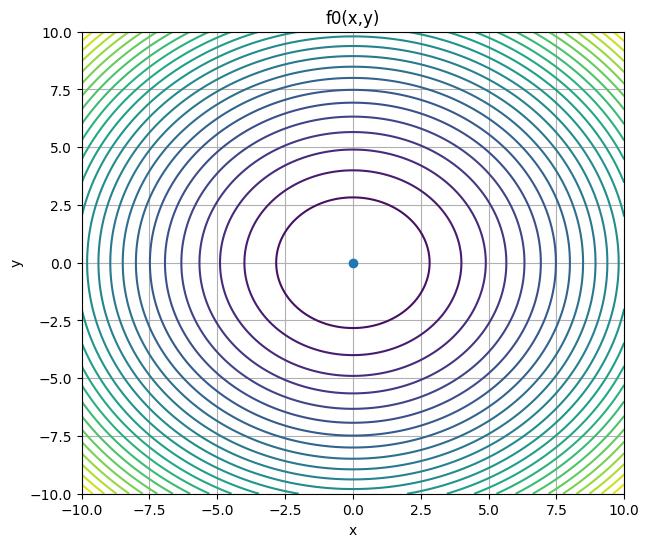

In [ ]:
graficar_funcion(f0, "f0(x,y)",0,0)

Está función claramente no es convexa, contiene muchas variaciones que son ruido, con alteraciones muy destacables propias de este tipo de función, esta topología hace que contenga incontables mínimos locales y puntos sillas por  los valles distribuidos a través de su contorno, en el que indudablemente quedará atrapado un algoritmo de gradiente. Para poder alcanzar el mínimo global ubicado (0,0), se requeríria un gran procesamiento computacional, requiriendo algoritmos con acumulación de momentum para escapar de estas trampas y aún así con pocas iteraciones seguramente no lo logre.


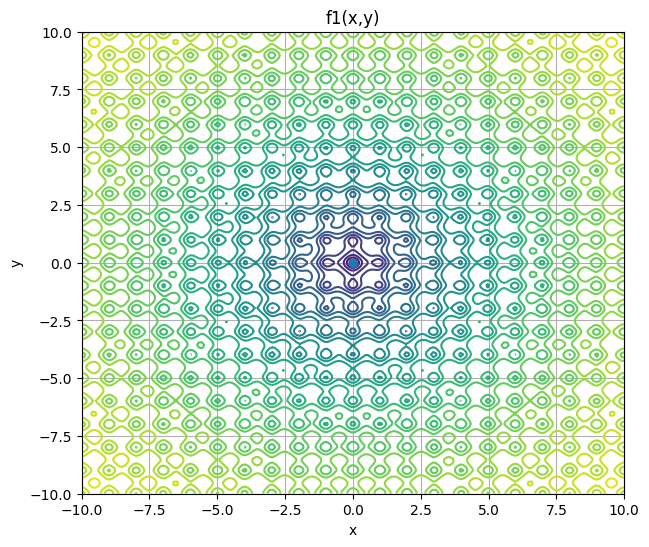

In [ ]:
graficar_funcion(f1, "f1(x,y)", 0, 0)

Esta función (conocida como función de Himmelblau) tampoco es convexa, ya que tiene varios mínimos. Las líneas de contorno están muy agrupadas en los bordes, indicando gradientes altos, mientras que el centro, alrededor de [-5,5], se ve casi en blanco. Esto no quiere decir que sea plana: los valores cerca de los bordes son tan grandes (en las esquinas superan los 10 000) que las 30 curvas de nivel se reparten en esos valores altos y casi ninguna queda en el centro, donde los valores son mucho menores.

Dentro de esa zona central es donde está lo interesante. Como se verifica más adelante con la matriz Hessiana, $f_2$ tiene cuatro mínimos, todos con valor 0 (por lo que los cuatro son mínimos globales), aproximadamente en (3, 2), (-2.81, 3.13), (-3.78, -3.28) y (3.58, -1.85). Entre ellos hay cuatro puntos silla, que funcionan como "pasos" entre un valle y otro, y un máximo local cerca de (-0.27, -0.92). El punto (0,0) no es un mínimo, ahí la función vale 170.

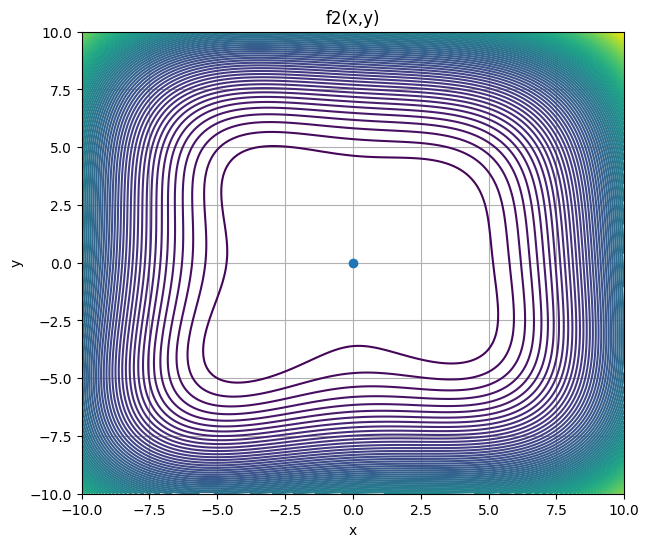

In [ ]:
graficar_funcion(f2, "f2(x,y)", 0, 0)

## Identificación de puntos críticos y silla
Ahora queremos encontrar los puntos críticos, así como los silla, para esto necesitamos varios procedimientos, lo primero son las derivadas parciales de primer orden, que ya tenemos anteriomente, ahora necesitamos:



### Matriz Hessiana

Para una función de dos variables, estas derivadas se organizan en la matriz Hessiana:

$$
H(x,y)=
\begin{bmatrix}
\frac{\partial^2 f}{\partial x^2} &
\frac{\partial^2 f}{\partial x\partial y}\\
\frac{\partial^2 f}{\partial y\partial x} &
\frac{\partial^2 f}{\partial y^2}
\end{bmatrix}
$$

En lugar de calcular estas derivadas nuevamente de forma manual, utilizaremos las funciones de gradiente que ya fueron definidas y backward() de PyTorch para obtener sus derivadas.

La siguiente función recibe las dos derivadas parciales de primer orden y un punto $(x,y)$, y utiliza esta información para construir la matriz Hessiana correspondiente a ese punto.


In [ ]:
def obtener_hessiana(gradiente, x, y):
    """!
    @brief Calcula la matriz Hessiana de una función en un punto dado, a
    partir de su gradiente, usando diferenciación automática de PyTorch.

    @param gradiente Función que recibe (x, y) y devuelve una tupla
          (df/dx, df/dy).
    @param x Coordenada x del punto donde se evalúa la Hessiana.
    @param y Coordenada y del punto donde se evalúa la Hessiana.
    @return H Tensor 2x2 con la matriz Hessiana en (x, y).
    """

    # Crear variables con seguimiento de gradiente
    x = torch.tensor(float(x), requires_grad=True)
    y = torch.tensor(float(y), requires_grad=True)

    # Obtener las primeras derivadas
    dx, dy = gradiente(x, y)

    # Obtener las segundas derivadas de dx
    dx.backward(retain_graph=True)

    dxx = x.grad.item()
    dxy = 0.0 if y.grad is None else y.grad.item()

    # Limpiar los gradientes
    x.grad.zero_()
    y.grad = None

    # Obtener las segundas derivadas de dy
    dy.backward()

    dyx = 0.0 if x.grad is None else x.grad.item()
    dyy = 0.0 if y.grad is None else y.grad.item()

    # Construir la matriz Hessiana
    H = torch.tensor([
        [dxx, dxy],
        [dyx, dyy]
    ])

    return H


### Búsqueda de un punto crítico

Con la matriz Hessiana disponible, podemos buscar un punto crítico de la función.

Recordemos que un punto crítico es un punto donde el gradiente es cero:

$$
\nabla f(x,y)=0
$$

Para encontrarlo numéricamente utilizaremos el método de Newton, utiliza tanto el gradiente como la matriz Hessiana para determinar hacia dónde debe desplazarse el punto actual.

La actualización utilizada es:

$$
\theta_{k+1}
=
\theta_k-H^{-1}\nabla f(\theta_k)
$$

donde $\theta=(x,y)$.

La función recibe un punto inicial $(x,y)$ porque el método es iterativo, a partir de esa posición calcula sucesivamente nuevos puntos hasta que el gradiente sea suficientemente cercano a cero o se alcance el número máximo de iteraciones.

En esta etapa buscamos un solo punto crítico a partir de una posición inicial. Más adelante utilizaremos esta función varias veces para buscar diferentes puntos críticos.


In [ ]:
def encontrar_punto_critico(gradiente, x_inicial, y_inicial, iteraciones=25):
    """!
    @brief Encuentra un punto crítico de una función mediante el método
    de Newton, partiendo de un punto inicial.

    @param gradiente Función que recibe (x, y) y devuelve una tupla
          (df/dx, df/dy).
    @param x_inicial Coordenada x del punto de partida.
    @param y_inicial Coordenada y del punto de partida.
    @param iteraciones Número máximo de iteraciones del método de Newton.
          Por defecto 50.
    @return theta Tensor [x, y] con el punto crítico encontrado.
    """

    theta = torch.tensor([x_inicial, y_inicial],dtype=torch.float32)

    for i in range(iteraciones):

        x = theta[0].clone().detach().requires_grad_(True)
        y = theta[1].clone().detach().requires_grad_(True)

        dx, dy = gradiente(x, y)

        grad = torch.stack([dx, dy])

        # Si el gradiente ya es prácticamente cero
        if torch.norm(grad) < 1e-4:
            break

        H = obtener_hessiana(gradiente, x.item(), y.item())

        # Método de Newton
        cambio = torch.linalg.solve(H, grad)

        theta = theta - cambio

    return theta


### Clasificación del punto crítico

Encontrar un punto donde el gradiente es cero nos indica que tenemos un punto crítico, pero todavía no sabemos qué tipo de punto es.

Para determinarlo utilizamos la matriz Hessiana calculada anteriormente. En dos variables podemos utilizar su determinante:

$$
D =
\det(H)
$$

junto con el valor de la segunda derivada respecto a $x$.

El criterio utilizado es:

* $D>0$ y $f_{xx}>0$: **mínimo local**.
* $D>0$ y $f_{xx}<0$: **máximo local**.
* $D<0$: **punto silla**.
* $D=0$: el criterio es **no concluyente**.

La siguiente función recibe un punto crítico, calcula su Hessiana y aplica este criterio para determinar su clasificación.


In [ ]:
def clasificar_punto(gradiente, x, y):
    """!
    @brief Clasifica un punto crítico como mínimo local, máximo local,
    punto silla o no concluyente, a partir de su matriz Hessiana.

    @param gradiente Función que recibe (x, y) y devuelve una tupla
          (df/dx, df/dy).
    @param x Coordenada x del punto a clasificar.
    @param y Coordenada y del punto a clasificar.
    @return H Matriz Hessiana en (x, y).
    @return D Determinante de la Hessiana.
    @return tipo Cadena con la clasificación del punto.
    """

    H = obtener_hessiana(gradiente, x, y)

    D = torch.det(H).item()

    dxx = H[0, 0].item()

    if D > 0 and dxx > 0:
        tipo = "Mínimo local"

    elif D > 0 and dxx < 0:
        tipo = "Máximo local"

    elif D < 0:
        tipo = "Punto silla"

    else:
        tipo = "No concluyente"

    return H, D, tipo


### Búsqueda de múltiples puntos críticos

Hasta este momento, encontrar_punto_critico() nos permite encontrar un punto crítico a partir de una posición inicial. Sin embargo, una función puede tener varios puntos críticos.

Para intentar encontrarlos todos dentro de una región determinada, repetiremos el procedimiento utilizando diferentes puntos iniciales.

El parámetro limite define la región donde queremos buscar. En este caso utilizaremos $[-10,10]$ tanto para $x$ como para $y$, manteniendo el mismo espacio utilizado para analizar las funciones.

El parámetro pasos determina cuántos puntos iniciales se distribuyen dentro de ese intervalo. Por ejemplo, con pasos=15 se generan 15 posiciones para cada eje y, por lo tanto, se realizan:

$
15\times15=225
$
puntos iniciales.

Cada uno de estos puntos se utiliza para ejecutar encontrar_punto_critico(). Debido a que diferentes posiciones iniciales pueden converger al mismo punto crítico, también se verifica si el punto encontrado ya había sido almacenado para evitar duplicados.


In [ ]:
def encontrar_puntos_criticos(
    gradiente,
    limite=(-10, 10),
    pasos=15
):
    """!
    @brief Busca puntos críticos de una función recorriendo una malla de
    puntos iniciales dentro de un rango dado.

    @param gradiente Función que recibe (x, y) y devuelve una tupla
          (df/dx, df/dy).
    @param limite Tupla (mínimo, máximo) que define el rango de búsqueda
          en x e y. Por defecto (-10, 10).
    @param pasos Cantidad de puntos iniciales por eje usados para armar
          la malla de búsqueda. Por defecto 15.
    @return puntos Lista de tensores [x, y] con los puntos críticos
          encontrados dentro del rango, sin repetidos.
    """

    puntos = []

    valores = torch.linspace(limite[0],limite[1],pasos)

    for x in valores:
        for y in valores:

            punto = encontrar_punto_critico(gradiente,x.item(),y.item())

            # Verificar que esté dentro del rango
            if (
                punto[0] >= limite[0] and
                punto[0] <= limite[1] and
                punto[1] >= limite[0] and
                punto[1] <= limite[1]
            ):

                # Verificar que realmente sea crítico
                x_p = punto[0].clone().detach().requires_grad_(True)
                y_p = punto[1].clone().detach().requires_grad_(True)

                dx, dy = gradiente(x_p, y_p)

                if torch.norm(torch.stack([dx, dy])) < 1e-4:

                    # Evitar puntos repetidos
                    repetido = False

                    for existente in puntos:
                        if torch.norm(punto - existente) < 1e-3:
                            repetido = True
                            break

                    if not repetido:
                        puntos.append(punto)

    return puntos


### Visualización de los puntos críticos

Después de encontrar los puntos críticos, podemos visualizarlos sobre las curvas de nivel de cada función.

Las curvas de nivel permiten observar la forma de la superficie desde arriba, mientras que los puntos encontrados por el algoritmo se muestran directamente sobre este plano.

La función recibe la función matemática, su nombre y la lista de puntos críticos encontrados. Primero construye la misma malla utilizada para las gráficas anteriores y calcula los valores de la función sobre ella. Luego dibuja las curvas de nivel y coloca un marcador en cada punto crítico, con un color distinto según su tipo (mínimo, máximo o punto silla).

De esta forma podemos comprobar visualmente dónde se encuentran los puntos críticos dentro de la región analizada.


In [ ]:
def graficar_puntos_criticos(funcion,nombre,puntos,tipos=None):
    """!
    @brief Grafica las curvas de nivel de una función junto con la
    ubicación de sus puntos críticos.

    @param funcion Función a graficar. Debe aceptar tensores (X, Y) y
          devolver un tensor con f(X, Y).
    @param nombre Título que se muestra en la gráfica.
    @param puntos Lista de tensores [x, y] con los puntos críticos a
          marcar en la gráfica.
    @param tipos Lista de cadenas con la clasificación de cada punto, en
          el mismo orden que puntos. Si se indica, todos los puntos del
          mismo tipo se dibujan del mismo color y se agrega una leyenda.
          Por defecto None.
    @return None. La función muestra la gráfica directamente.
    """

    x = torch.linspace(-10, 10, 200)
    y = torch.linspace(-10, 10, 200)


    # Crea una malla 2D con todas las combinaciones de coordenadas (X, Y)
    X, Y = torch.meshgrid(x, y, indexing="ij")

    Z = funcion(X, Y)

    plt.figure(figsize=(7, 6))

    # Dibuja las curvas de nivel de la superficie con 30 niveles
    plt.contour(X.numpy(),Y.numpy(),Z.detach().numpy(),levels=30)

    # Un color fijo por cada tipo de punto crítico
    colores = {
        "Mínimo local": "red",
        "Máximo local": "magenta",
        "Punto silla": "black",
        "No concluyente": "gray"
    }

    # Tipos que ya tienen su etiqueta en la leyenda
    tipos_en_leyenda = set()

    for i, punto in enumerate(puntos):

        x_p = punto[0].item()
        y_p = punto[1].item()

        if tipos is None:
            plt.plot(x_p,y_p,marker="o",markersize=8)

        else:
            tipo = tipos[i]

            # Solo se agrega la etiqueta la primera vez que aparece el tipo
            etiqueta = None if tipo in tipos_en_leyenda else tipo
            tipos_en_leyenda.add(tipo)

            plt.plot(x_p,y_p,marker="o",markersize=8,color=colores[tipo],label=etiqueta)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(nombre)
    plt.xlim(-10, 10)
    plt.ylim(-10, 10)
    plt.grid()

    if tipos is not None:
        plt.legend(loc="upper right", framealpha=0.9)

    plt.show()


### Análisis completo

Finalmente, podemos unir todos los procedimientos anteriores en una sola función.

Esta función se encarga de encontrar los puntos críticos dentro de los límites establecidos, calcular la Hessiana de cada punto, determinar su clasificación y mostrar sus resultados.

De esta manera, las funciones anteriores realizan cada etapa individual del procedimiento, mientras que esta función únicamente las coordina para realizar el análisis completo de cada función.


In [ ]:
def analizar_puntos_criticos(
    funcion,
    df_dx,
    df_dy,
    nombre,
    limites=(-10, 10),
    pasos=15,
    verbose=False
):
    """!
    @brief Busca y clasifica los puntos críticos de una función dentro
    de un rango dado, sin imprimir el detalle de cada uno por defecto.

    @param funcion Función a analizar. Debe aceptar tensores (x, y) y
           devolver f(x, y).
    @param df_dx Derivada parcial de la función respecto a x. Debe
           aceptar (x, y) y devolver df/dx.
    @param df_dy Derivada parcial de la función respecto a y. Debe
           aceptar (x, y) y devolver df/dy.
    @param nombre Nombre de la función, usado solo para los mensajes
           impresos.
    @param limites Tupla (mínimo, máximo) que define el rango de
           búsqueda en x e y. Por defecto (-10, 10).
    @param pasos Cantidad de puntos iniciales por eje usados para armar
           la malla de búsqueda. Por defecto 15.
    @param verbose Si es True, imprime x, y, f(x,y) y tipo de cada
           punto crítico encontrado. Por defecto False, para no saturar
           la salida cuando hay muchos puntos.
    @return resultados Lista de diccionarios, uno por punto crítico
            encontrado, con las claves "punto", "hessiana",
            "determinante", "tipo" y "valor".
    """

    gradiente = lambda x, y: (df_dx(x, y), df_dy(x, y))

    puntos = encontrar_puntos_criticos(gradiente, limites, pasos)

    resultados = []

    for punto in puntos:
        x = punto[0].item()
        y = punto[1].item()

        H, D, tipo = clasificar_punto(gradiente, x, y)

        valor = funcion(torch.tensor(x), torch.tensor(y)).item()

        resultados.append({
            "punto": punto,
            "hessiana": H,
            "determinante": D,
            "tipo": tipo,
            "valor": valor
        })

        if verbose:
            print(f"x={x:.4f}, y={y:.4f}, f={valor:.4f}, tipo={tipo}")

    conteo = pd.Series([r["tipo"] for r in resultados]).value_counts()
    print(f"\n{nombre}: {len(resultados)} puntos críticos encontrados")
    print(conteo.to_string())

    return resultados


def tabla_puntos_criticos(resultados, nombre, tipos=None):
    """!
    @brief Construye e imprime una tabla numérica con los puntos
    críticos de una lista de resultados, incluyendo su clasificación.

    @param resultados Lista de diccionarios generada por
           analizar_puntos_criticos, con las claves "punto",
           "determinante", "tipo" y "valor" para cada punto crítico.
    @param nombre Nombre de la función, usado como título de la tabla.
    @param tipos Lista de cadenas con los tipos de punto a incluir en
           la tabla (por ejemplo ["Punto silla", "Mínimo local"]). Si
           es None (valor por defecto), se incluyen todos los tipos:
           "Mínimo local", "Máximo local" y "Punto silla".
    @return df DataFrame de pandas con columnas "x", "y", "f(x,y)",
            "Determinante" y "Tipo", uno por cada punto crítico que
            cumpla con el filtro de tipos.
    """
    if tipos is None:
        tipos = ["Mínimo local", "Máximo local", "Punto silla"]

    filas = [
        {
            "x": r["punto"][0].item(),
            "y": r["punto"][1].item(),
            "f(x,y)": r["valor"],
            "Determinante": r["determinante"],
            "Tipo": r["tipo"]
        }
        for r in resultados if r["tipo"] in tipos
    ]

    df = pd.DataFrame(filas).round(6)

    # Ordena por tipo para agrupar visualmente mínimos, máximos y sillas
    if not df.empty:
        orden = {"Mínimo local": 0, "Máximo local": 1, "Punto silla": 2}
        df["_orden"] = df["Tipo"].map(orden)
        df = df.sort_values("_orden").drop(columns="_orden").reset_index(drop=True)

    print(f"\nPuntos críticos de {nombre}: {len(df)} encontrados")
    display(df)

    return df


f0: 1 puntos críticos encontrados
Mínimo local    1

Puntos críticos de f0: 1 encontrados


,x,y,"f(x,y)",Determinante,Tipo
0,0.0,0.0,0.0,4.0,Mínimo local


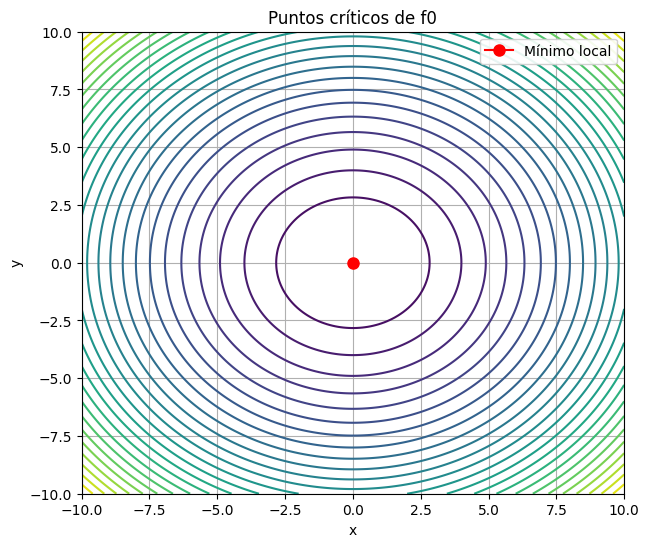


f1: 208 puntos críticos encontrados
Punto silla     108
Máximo local     88
Mínimo local     12

Puntos críticos de f1: 208 encontrados


,x,y,"f(x,y)",Determinante,Tipo
0,-9.994947,-9.994947,17.291927,2868.898438,Mínimo local
1,-9.987126,0.000000,15.133245,2849.344727,Mínimo local
2,-9.994947,9.994947,17.291927,2868.898438,Mínimo local
3,5.988710,5.988710,13.969326,2834.749268,Mínimo local
4,5.988710,-5.988710,13.969326,2834.749268,Mínimo local
...,...,...,...,...,...
203,9.965261,1.505206,16.921019,-359.769226,Punto silla
204,9.971916,4.512656,17.470657,-371.183716,Punto silla
205,9.974764,5.513909,17.732178,-375.281921,Punto silla
206,9.977617,6.514586,18.012918,-378.897339,Punto silla


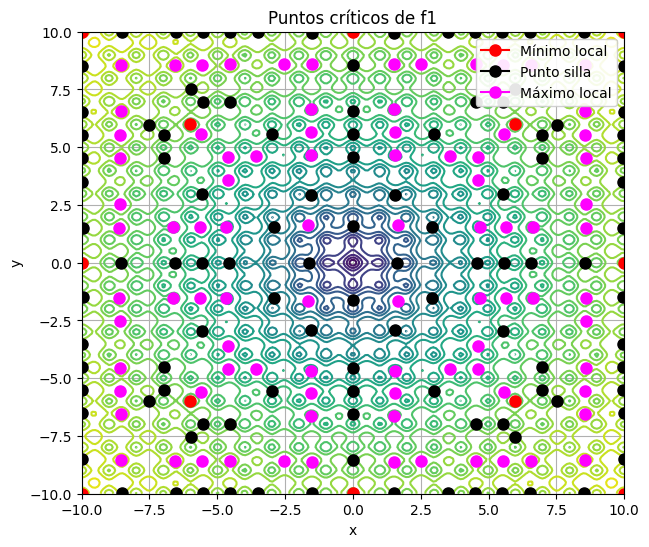


f2: 9 puntos críticos encontrados
Mínimo local    4
Punto silla     4
Máximo local    1

Puntos críticos de f2: 9 encontrados


,x,y,"f(x,y)",Determinante,Tipo
0,-3.779310,-3.283186,0.000000,9460.561523,Mínimo local
1,-2.805118,3.131313,0.000000,5222.897461,Mínimo local
2,3.000000,2.000000,0.000000,2116.000244,Mínimo local
3,3.584429,-1.848127,0.000000,3024.540771,Mínimo local
4,-0.270845,-0.923038,181.616531,732.694641,Máximo local
5,-3.073026,-0.081353,104.015160,-2872.165771,Punto silla
6,-0.127961,-1.953717,178.337250,-1026.585938,Punto silla
7,0.086678,2.884255,67.719147,-2394.091309,Punto silla
8,3.385154,0.073852,13.311926,-1378.856689,Punto silla


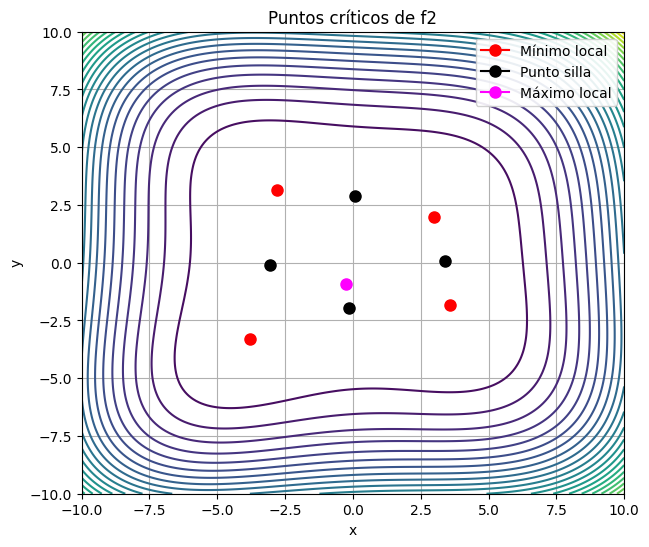

In [ ]:
resultados_f0 = analizar_puntos_criticos(f0, df0_dx, df0_dy, "f0")
tabla_f0 = tabla_puntos_criticos(resultados_f0, "f0")
graficar_puntos_criticos(f0, "Puntos críticos de f0", [r["punto"] for r in resultados_f0], [r["tipo"] for r in resultados_f0])

resultado_f1 = analizar_puntos_criticos(f1, df1_dx, df1_dy, "f1")
tabla_f1 = tabla_puntos_criticos(resultado_f1, "f1")
graficar_puntos_criticos(f1, "Puntos críticos de f1", [r["punto"] for r in resultado_f1], [r["tipo"] for r in resultado_f1])

resultado_f2 = analizar_puntos_criticos(f2, df2_dx, df2_dy, "f2")
tabla_f2 = tabla_puntos_criticos(resultado_f2, "f2")
graficar_puntos_criticos(f2, "Puntos críticos de f2", [r["punto"] for r in resultado_f2], [r["tipo"] for r in resultado_f2])

### ¿Por qué no aparece el mínimo global de $f_1$ en (0,0)?

En la gráfica de $f_1$ ningún marcador cae en el origen, a pesar de que ahí está su mínimo global. Esto no significa que no exista, sino que nuestro método no lo puede detectar.

Las derivadas de $f_1$ tienen el término $\sqrt{2x^2 + 2y^2}$ dividiendo. En (0,0) esa raíz vale 0, entonces el cálculo queda $\frac{0}{0}$, que no tiene resultado, y PyTorch lo devuelve como nan ("not a number", no es un número). Como el método de Newton depende del gradiente y de la Hessiana, al recibir nan no puede avanzar, y ese punto se descarta.



## Descenso de Gradiente
### Implementación de funciones:
Para el descenso de gradiente vamos a utilizar la función backward() que calcula las derivadas parciales, pero también vamos a implementar una versión con las derivadas que hicimos anteriormente para verificar que ambos resultados coincidan. Con las 25 iteraciones solicitadas.



In [ ]:
 # Descenso de gradiente con backward
def descenso_gradiente_backward(funcion, x_inicial, y_inicial, alpha, P=25):
    """!
    @brief Ejecuta el descenso de gradiente usando diferenciación
    automática (backward) de PyTorch para calcular el gradiente.

    @param funcion Función a minimizar. Debe aceptar tensores (x, y) y
          devolver f(x, y).
    @param x_inicial Coordenada x del punto de partida.
    @param y_inicial Coordenada y del punto de partida.
    @param alpha Tasa de aprendizaje (paso de actualización).
    @param P Cantidad de iteraciones a ejecutar. Por defecto 25.
    @return x_history Historial de valores de x en cada iteración.
    @return y_history Historial de valores de y en cada iteración.
    """

    # Inicialización de variables
    x = torch.tensor(float(x_inicial), requires_grad=True)
    y = torch.tensor(float(y_inicial), requires_grad=True)

    # Historial de posiciones
    x_history = [x.item()]
    y_history = [y.item()]


    # Iteraciones
    for i in range(P):

        # Evaluación de la función
        f = funcion(x, y)

        # Cálculo automático del gradiente
        f.backward()

        # Actualización de las variables
        with torch.no_grad():
            x -= alpha * x.grad
            y -= alpha * y.grad

        # Limpiar los gradientes anteriores
        x.grad.zero_()
        y.grad.zero_()

        # Guardar la nueva posición
        x_history.append(x.item())
        y_history.append(y.item())

    return x_history, y_history


Después realizamos la variación que utiliza las derivadas que modelamos, para un descenso de gradiente con moméntum, con la convención del beta 0.9.


In [ ]:
# Descenso de gradiente con momentum
def descenso_gradiente_momentum(df_dx, df_dy, x_inicial, y_inicial, alpha, beta=0.9, P=25):
    """!
    @brief Ejecuta el descenso de gradiente con momentum, usando las
    derivadas parciales provistas explícitamente.

    @param df_dx Derivada parcial de la función respecto a x.
    @param df_dy Derivada parcial de la función respecto a y.
    @param x_inicial Coordenada x del punto de partida.
    @param y_inicial Coordenada y del punto de partida.
    @param alpha Tasa de aprendizaje (paso de actualización).
    @param beta Factor de momentum. Por defecto 0.9.
    @param P Cantidad de iteraciones a ejecutar. Por defecto 25.
    @return x_history Historial de valores de x en cada iteración.
    @return y_history Historial de valores de y en cada iteración.
    """

    # Inicialización de variables
    x = torch.tensor(x_inicial, dtype=torch.float32)
    y = torch.tensor(y_inicial, dtype=torch.float32)

    # Inicialización del momentum
    vx = torch.tensor(0.0)
    vy = torch.tensor(0.0)

    # Historial de posiciones
    x_history = [x.item()]
    y_history = [y.item()]

    # Iteraciones
    for i in range(P):

        # Cálculo del gradiente
        grad_x = df_dx(x, y)
        grad_y = df_dy(x, y)

        # Actualización del momentum
        vx = beta * vx + grad_x
        vy = beta * vy + grad_y

        # Actualización de las variables
        x = x - alpha * vx
        y = y - alpha * vy

        # Guardar posición
        x_history.append(x.item())
        y_history.append(y.item())

    return x_history, y_history


Al tener un rango de [-10 , 10 ] decidimos incializarlo en el punto 9.5, para ver su comportamiento desde el extremo. También, después de varias pruebas nos decidimos por un alpha de 0.05, un valor bastante razonable según el estándar, finalmente las iteraciones de 25  como fueron solicitadas.


### Cálculos

En términos generales, los resultados muestran que backward y momentum siguen el mismo principio de descenso, pero no  producen la misma trayectoria. Vamos a ver esto individualmente:


$$f_0(x, y) = x^2 + y^2$$

Es el comportamiento más estable de los tres casos, bastante natural al considerar su forma. En ambos casos después de las 25 iteraciones termina cercano al mínimo global posicionado en (0,0).
Sin embargo el método con momentum presenta un comportamiento distinto debido a sus propiedades, avanza más rapidamente hacia el mínimo pero por la acumulación de velocidad lo termina sobrepasando, llegando a valores de -4, aunque eventualmente comienza a regresar hacia el origen, terminando en 0.25.
Por otro lado el gradiente implementado con backwards se dirige sin oscilación hacia el punto origen, finalizando en 0.68.


x_history: [9.5, 8.550000190734863, 7.695000171661377, 6.92549991607666, 6.232949733734131, 5.609654903411865, 5.048689365386963, 4.543820381164551, 4.089438438415527, 3.680494546890259, 3.3124451637268066, 2.981200695037842, 2.6830806732177734, 2.4147725105285645, 2.173295259475708, 1.9559657573699951, 1.7603691816329956, 1.5843322277069092, 1.4258990287780762, 1.2833091020584106, 1.1549781560897827, 1.0394803285598755, 0.93553227186203, 0.8419790267944336, 0.7577811479568481, 0.6820030212402344]
y_history: [9.5, 8.550000190734863, 7.695000171661377, 6.92549991607666, 6.232949733734131, 5.609654903411865, 5.048689365386963, 4.543820381164551, 4.089438438415527, 3.680494546890259, 3.3124451637268066, 2.981200695037842, 2.6830806732177734, 2.4147725105285645, 2.173295259475708, 1.9559657573699951, 1.7603691816329956, 1.5843322277069092, 1.4258990287780762, 1.2833091020584106, 1.1549781560897827, 1.0394803285598755, 0.93553227186203, 0.8419790267944336, 0.7577811479568481, 0.682003021240

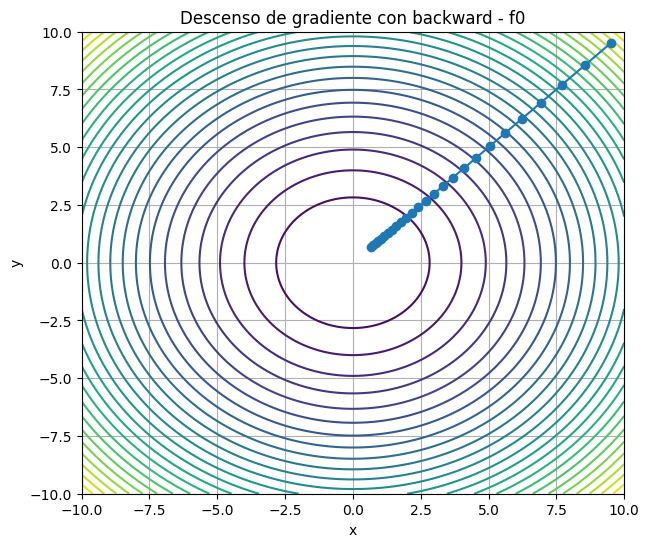

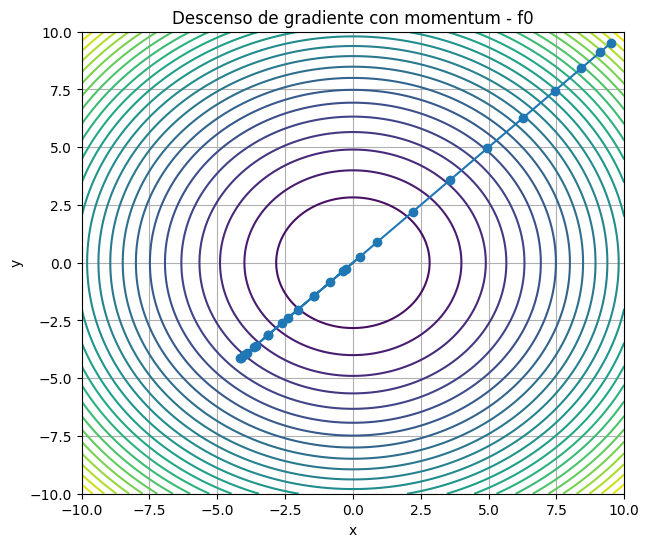

y_momentum: 9.5 9.119999885559082 8.413200378417969 7.440552234649658 6.267547130584717 4.9611406326293945 3.5869293212890625 2.206662178039551 0.8761551380157471 -0.35634732246398926 -1.4513455629348755 -2.3787901401519775 -3.1183385848999023 -3.659198760986328 -3.9996049404144287 -4.145986080169678 -4.111889839172363 -3.9167275428771973 -3.5844125747680664 -3.1419525146484375 -2.618060350418091 -2.041835069656372 -1.441558837890625 -0.8436479568481445 -0.2717822194099426 0.2537682056427002
x_momentum: 9.5 9.119999885559082 8.413200378417969 7.440552234649658 6.267547130584717 4.9611406326293945 3.5869293212890625 2.206662178039551 0.8761551380157471 -0.35634732246398926 -1.4513455629348755 -2.3787901401519775 -3.1183385848999023 -3.659198760986328 -3.9996049404144287 -4.145986080169678 -4.111889839172363 -3.9167275428771973 -3.5844125747680664 -3.1419525146484375 -2.618060350418091 -2.041835069656372 -1.441558837890625 -0.8436479568481445 -0.2717822194099426 0.2537682056427002


In [ ]:
# Parámetros
x_inicial =  9.5
y_inicial = 9.5
alpha = 0.05
P = 25

# Ejecutar descenso
x_history, y_history = descenso_gradiente_backward(f0,x_inicial,y_inicial,alpha,P)

print("x_history:", x_history)
print("y_history:", y_history)

# Ejecutar descenso con momentum
x_history_momentum, y_history_momentum = descenso_gradiente_momentum(df0_dx,df0_dy,x_inicial,y_inicial,0.02,0.9,25)

# Mostrar trayectoria
graficar_funcion(f0,"Descenso de gradiente con backward - f0",x_history,y_history)
graficar_funcion(f0,"Descenso de gradiente con momentum - f0",x_history_momentum,y_history_momentum)


print("y_momentum:", *y_history_momentum)
print("x_momentum:", *x_history_momentum)


$$ f_1(x, y) = -20 e^{-0.2 \sqrt{0.5 (x^2 + y^2)}} - e^{0.5 (\cos (2\pi x) + \cos (2\pi y))} + e + 20 $$
Se observa un comportamiento muy irregular. Con backward, los valores inicialmente disminuyen desde 9.5, pero después de varias iteraciones comienzan a oscilar aproximadamente entre [8.8 - 9], lo que significa que el algoritmo llegó a una región donde el gradiente provoca movimientos de "salto"  y no consigue avanzar hacia otra posición, oscilando entre esos dos valores.

El momentum también presenta problemas similares, aunque de una forma distinta. Primero disminuye hasta aproximadamente 8.67, después aumenta hasta 9.17 y después vuelve a oscilar entre esos dos valores terminando en 9.11.
En este caso, el momentum no elimina la oscilación, el algoritmo sigue desplazándose alrededor de la misma región.

Claramente en la gráfica se puede ver que está muy lejos del mínimo global, quedando ambos métodos atrapados en un mínimo local, logrando avanzar muy poco hacia el punto origen. Es coherente con la funcion $f_1$ por tener múltiples variaciones locales.

x_history: [9.5, 9.4850435256958, 9.464595794677734, 9.436466217041016, 9.397021293640137, 9.339115142822266, 9.245418548583984, 9.06808090209961, 8.889906883239746, 9.089441299438477, 8.878114700317383, 9.085039138793945, 8.879633903503418, 9.085794448852539, 8.879339218139648, 9.085652351379395, 8.879393577575684, 9.085679054260254, 8.879383087158203, 9.085673332214355, 8.879384994506836, 9.085674285888672, 8.879384994506836, 9.085674285888672, 8.879384994506836, 9.085674285888672]
y_history: [9.5, 9.4850435256958, 9.464595794677734, 9.436466217041016, 9.397021293640137, 9.339115142822266, 9.245418548583984, 9.06808090209961, 8.889906883239746, 9.089441299438477, 8.878114700317383, 9.085039138793945, 8.879633903503418, 9.085794448852539, 8.879339218139648, 9.085652351379395, 8.879393577575684, 9.085679054260254, 8.879383087158203, 9.085673332214355, 8.879384994506836, 9.085674285888672, 8.879384994506836, 9.085674285888672, 8.879384994506836, 9.085674285888672]


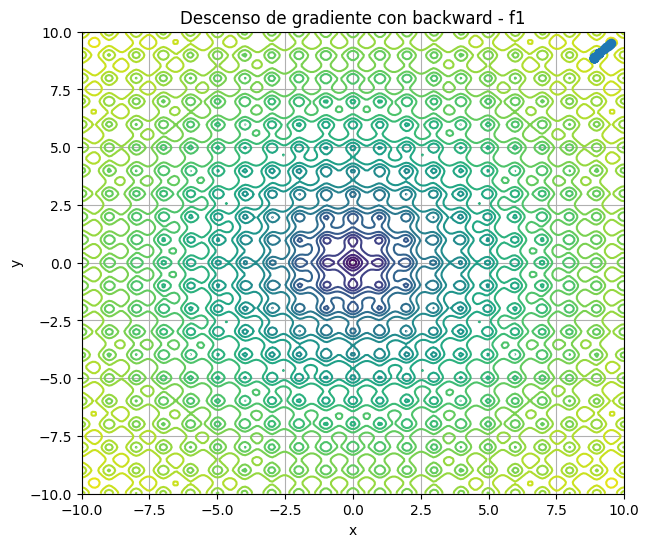

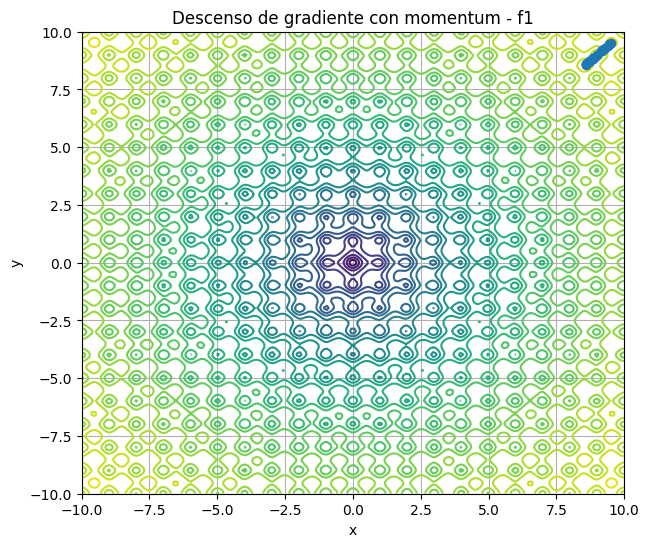

x_momentum: 9.5 9.4850435256958 9.45113468170166 9.387211799621582 9.266536712646484 9.00141716003418 8.742481231689453 8.641701698303223 8.5983247756958 8.58164119720459 8.580907821655273 8.594191551208496 8.626434326171875 8.693253517150879 8.839644432067871 9.180861473083496 9.254960060119629 9.153754234313965 8.818473815917969 8.716229438781738 8.731111526489258 8.865620613098145 9.197847366333008 9.275774955749512 9.198328018188477 8.907928466796875
y_momentum: 9.5 9.4850435256958 9.45113468170166 9.387211799621582 9.266536712646484 9.00141716003418 8.742481231689453 8.641701698303223 8.5983247756958 8.58164119720459 8.580907821655273 8.594191551208496 8.626434326171875 8.693253517150879 8.839644432067871 9.180861473083496 9.254960060119629 9.153754234313965 8.818473815917969 8.716229438781738 8.731111526489258 8.865620613098145 9.197847366333008 9.275774955749512 9.198328018188477 8.907928466796875


In [ ]:

# Ejecutar descenso
x_history, y_history = descenso_gradiente_backward(f1,x_inicial,y_inicial,alpha,P)

print("x_history:", x_history)
print("y_history:", y_history)

# Ejecutar descenso con momentum
x_history_momentum, y_history_momentum = descenso_gradiente_momentum(df1_dx,df1_dy,x_inicial,y_inicial,0.05,0.9,25)

# Mostrar trayectoria
graficar_funcion(f1,"Descenso de gradiente con backward - f1",x_history,y_history)
graficar_funcion(f1,"Descenso de gradiente con momentum - f1",x_history_momentum,y_history_momentum)

print("x_momentum:", *x_history_momentum)
print("y_momentum:", *y_history_momentum)

$$f_2(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2.$$

Aquí ambos métodos divergen: en lugar de acercarse al mínimo, los valores crecen sin control hasta terminar en inf y nan.

Lo que pasó paso a paso:

1. Las derivadas de $f_2$ tienen términos al cubo ($4x^3$ y $4y^3$). Por eso, entre más lejos está el punto, la pendiente crece muchísimo más rápido. En x = -168.4 la pendiente es de unos 19 millones, y el siguiente paso lleva el punto a casi un millón. Cada paso es aproximadamente el cubo del anterior.
2. PyTorch guarda los números en formato float32. En la iteración 4, elevar al cubo da un número tan grande que ya no cabe.


En resumen, ambos métodos siguen correctamente el gradiente el problema es que con este alpha los pasos son demasiado grandes para $f_2$. Para que el descenso de gradiente funcione aquí se necesita un alpha muy pequeño, como se verá en la calibración.

x_history: [9.5, -168.40000915527344, 945597.4375, -1.6910234573130957e+17, inf, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
y_history: [9.5, -175.60000610351562, 1073785.125, -2.4761824773249434e+17, inf, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]


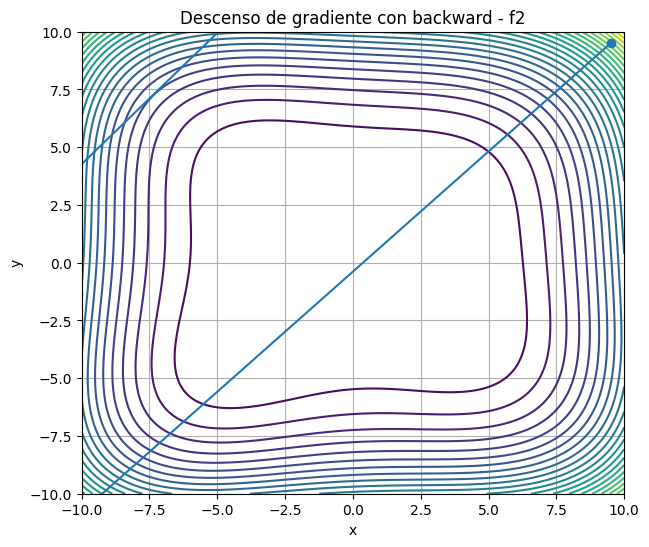

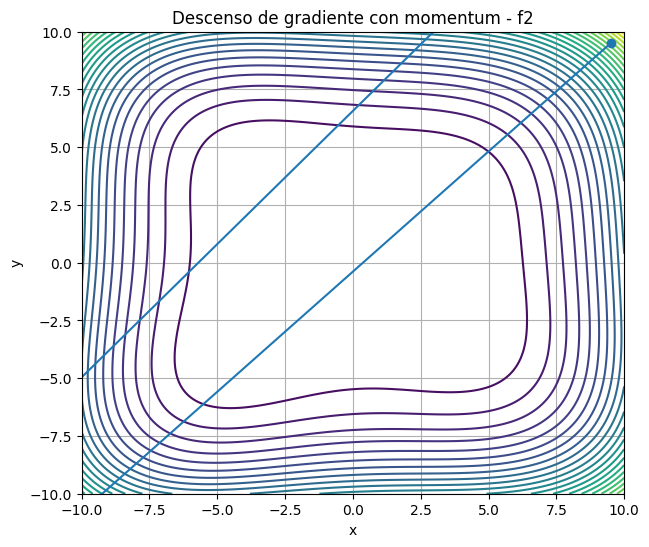

x_momentum: 9.5 -61.659996032714844 18092.083984375 -473804668928.0 8.509185120134543e+33 -inf nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
y_momentum: 9.5 -64.54000091552734 20872.1171875 -727470374912.0 3.0798952873628676e+34 -inf nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan


In [ ]:

# Ejecutar descenso
x_history, y_history = descenso_gradiente_backward(f2,x_inicial,y_inicial,alpha,P)

print("x_history:", x_history)
print("y_history:", y_history)

# Ejecutar descenso con momentum
x_history_momentum, y_history_momentum = descenso_gradiente_momentum(df2_dx,df2_dy,x_inicial,y_inicial,0.02,0.9,25)

# Mostrar trayectoria
graficar_funcion(f2,"Descenso de gradiente con backward - f2",x_history,y_history)
graficar_funcion(f2,"Descenso de gradiente con momentum - f2",x_history_momentum,y_history_momentum)

print("x_momentum:", *x_history_momentum)
print("y_momentum:", *y_history_momentum)

# RMSprop

$$ v_t = \beta v_{t-1} + (1 - \beta) g_t^2 $$
$$ \theta_t = \theta_{t-1} - \frac{\alpha}{\sqrt{v_t + \epsilon}} g_t $$

Recordando el funcionamiento de RMSprop rápidamente, la variable $g_t^2$ almacena el cuadrado del gradiente actual. Esto, junto con el parámetro $\beta$, provoca que se tenga una memoria del valor anterior. Esto nos ayuda a obtener el valor $v_t$, que representa la varianza de los gradientes recientes. Cuando realizamos el cálculo de $\theta$, si este valor $v_t$ es muy grande, el paso $\alpha$ efectivo (al dividirse entre la raíz de $v_t$) va a ser pequeño, así como a la inversa.
Teniendo modelada la función matemática, procedemos con la creación de la función.


In [ ]:
def rmsprop(funcion, theta_inicial, alpha=0.05, beta=0.9, epsilon=1e-8, P=25):
    """!
    @brief Ejecuta el algoritmo de optimización RMSprop sobre una
    función de dos variables.

    @param funcion Función a minimizar. Debe aceptar dos escalares
          (x, y) y devolver f(x, y).
    @param theta_inicial Lista o tensor [x0, y0] con el punto de
          partida.
    @param alpha Tasa de aprendizaje. Por defecto 0.05.
    @param beta Factor de decaimiento del promedio móvil del gradiente
          al cuadrado. Por defecto 0.9.
    @param epsilon Constante pequeña para evitar división por cero.
          Por defecto 1e-8.
    @param P Cantidad de iteraciones a ejecutar. Por defecto 25.
    @return theta_history Historial de posiciones theta en cada
          iteración.
    @return f_history Historial del valor de la función en cada
          iteración.
    """
    # Inicialización de variables
    theta = torch.tensor(theta_inicial, dtype=torch.float32, requires_grad=True)

    # Inicialización del promedio de gradientes
    v = torch.zeros_like(theta)

    # Historial de posiciones
    theta_history = [theta.detach().clone()]

    # Historial del valor de la función
    f_history = [funcion(theta[0], theta[1]).item()]

    # Iteraciones
    for i in range(P):

        # Evaluación de la función
        f = funcion(theta[0], theta[1])

        # Cálculo del gradiente
        f.backward()

        # Obtener gradiente
        gradiente = theta.grad

        # Actualización del promedio de gradientes
        v = beta * v + (1 - beta) * gradiente**2

        # Actualización de las variables
        with torch.no_grad():
            theta -= alpha * gradiente / (torch.sqrt(v) + epsilon)

        # Guardar resultados
        theta_history.append(theta.detach().clone())
        f_history.append(funcion(theta[0], theta[1]).item())

        # Limpiar gradiente
        theta.grad.zero_()

    return theta_history, f_history


Función graficadora:
Lo más destacable es esta función graficadora es la curva de aprendizaje, al verla estamos buscando que el error descienda de forma fluida hasta estabilizarse en la parte inferior, va a ser muy útil durante la calibración que realicemos.
Después estamos reutilizando la función que habíamos creado anteriormente para ver como se comporta el algoritmo.

In [ ]:
def visualizar_resultados_RMSprop(theta_history, f_history, funcion, titulo):
    """!
    @brief Imprime los resultados finales de una corrida de RMSprop y
    grafica la curva de aprendizaje y la trayectoria seguida.

    @param theta_history Historial de posiciones theta en cada
          iteración.
    @param f_history Historial del valor de la función en cada
          iteración.
    @param funcion Función optimizada, usada para graficar la
          trayectoria.
    @param titulo Título usado en las gráficas.
    @return None. La función imprime resultados y muestra las gráficas.
    """
    # Imprimir los valores finales
    print("Valores finales (x, y):", theta_history[-1])
    print("Valor final f(x, y):", f_history[-1])

    #Graficar la curva de aprendizaje (historial de la función)
    plt.figure(figsize=(7, 5))
    plt.plot(f_history, marker="o")
    plt.xlabel("Iteración")
    plt.ylabel("f(x,y)")
    plt.title(f"Curva de aprendizaje {titulo}")
    plt.grid()
    plt.show()

    #Extraer los historiales de x e y
    x_history = [theta[0] for theta in theta_history]
    y_history = [theta[1] for theta in theta_history]

    #Graficar la función con la trayectoria
    graficar_funcion(funcion, titulo, x_history, y_history)


## Prueba sin calibración de hiperparámetros
Antes de realizar la calibración de los hiperparámetros verificamos que funcione correctamente la función por implementar, como solamente estamos probando vamos a colocar los valores que tenía previamente las funciones.

Los resultados son esperados... actualmente no estamos calibrando ningun hiperparámetro, solamente estamos usando los valores arbitarios utilizados en el descenso de gradiente, por lo que la comparación actual es muy trivial. Los resultados fueron peores o similares a los del descenso de gradiente con y sin momentum, justamente por no haber ningún tipo de calibración.

El único destacable es con f2, porque al contrario de su implementación anterior ahora si se movió más cercano al punto mínimo en vez de dar los valores gigantescos.



Valores finales (x, y): tensor([7.8559, 7.8559])
Valor final f(x, y): 123.43143463134766


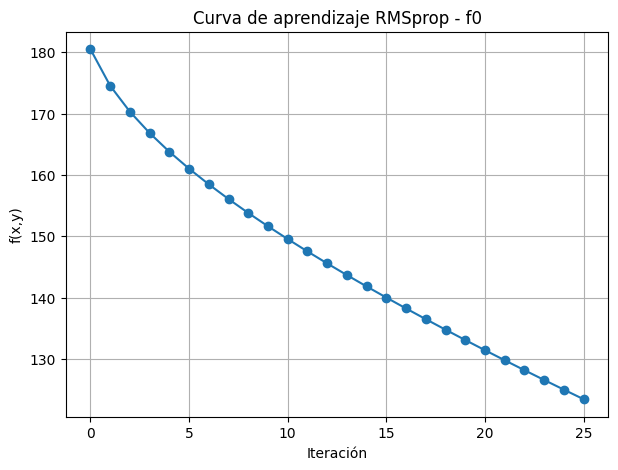

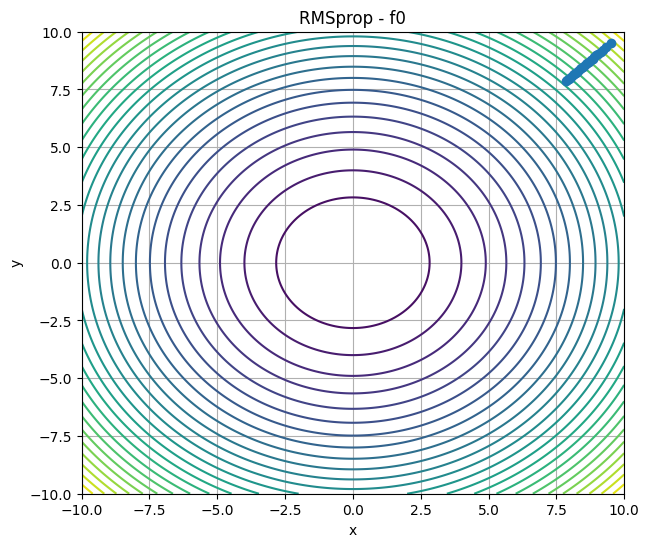

Valores finales (x, y): tensor([9.0136, 9.0136])
Valor final f(x, y): 16.71280288696289


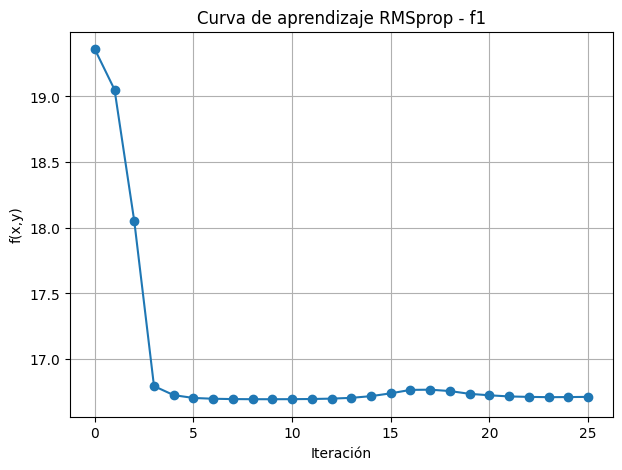

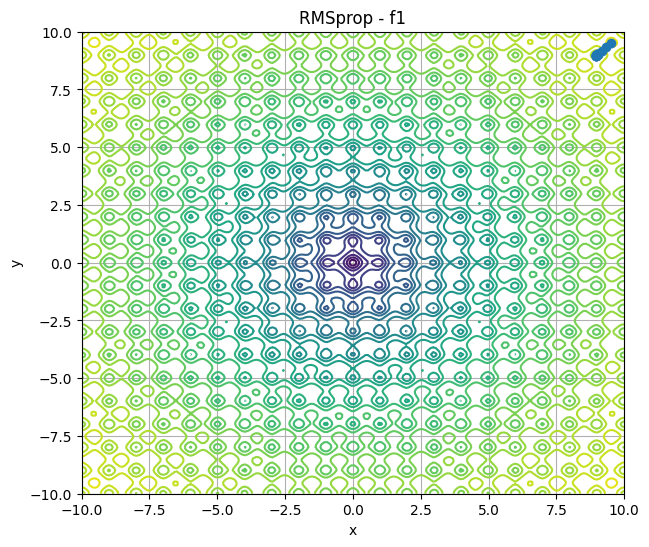

Valores finales (x, y): tensor([7.9482, 7.9442])
Valor final f(x, y): 7717.6669921875


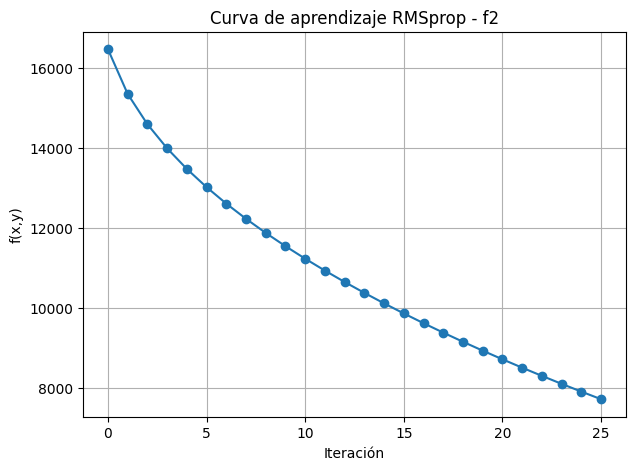

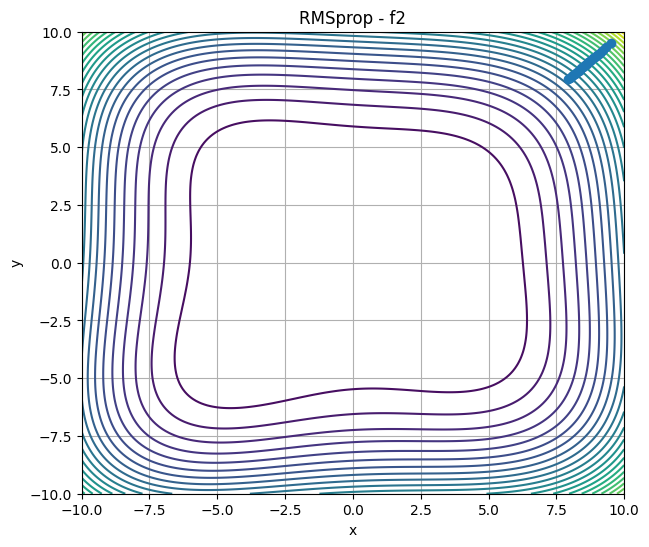

In [ ]:
theta_inicial = [9.5, 9.5]

theta_history, f_history = rmsprop(f0,theta_inicial,P=25,alpha=0.05,beta=0.9,epsilon=1e-8,)
visualizar_resultados_RMSprop(theta_history, f_history, f0, "RMSprop - f0")

theta_history, f_history = rmsprop(f1,theta_inicial,P=25,alpha=0.05,beta=0.9,epsilon=1e-8,)
visualizar_resultados_RMSprop(theta_history, f_history, f1, "RMSprop - f1")

theta_history, f_history = rmsprop(f2,theta_inicial,P=25,alpha=0.05,beta=0.9,epsilon=1e-8,)
visualizar_resultados_RMSprop(theta_history, f_history, f2, "RMSprop - f2")



## Ajuste de los hiperparámetros:

Para ajustar los hiperparámetros de los algoritmos buscamos la tasa de aprendizaje (alpha) y factor de decaimiento (beta) en RMSProp, en el caso de descenso de gradiente beta no se usa, por lo que implementamos una función por aparte donde no se utiliza.
Implementamos una función calibrar_rmsprop y calibrar_descenso_gradiente que recibe la función objetivo, los puntos iniciales, las iteraciones y el número de trials.

Se sugieren valores para alpha en un rango logarítmico [1e-4 - 1.0] y para beta en un rango lineal [0.8 - 0.99]. Con esos hiperparámetros, se ejecuta el algoritmo durante 25 iteraciones, como lo indica el enunciado, desde cada uno de los 10 puntos iniciales que usaremos después en las pruebas. La métrica que Optuna minimiza es el promedio del valor final de la función en esas 10 corridas.

Esta calibración la realizaremos para cada función de prueba, tanto con descenso de gradiente como con RMSProp y así obtendremos los conjuntos de hiperparámetros que mejor se adaptan a cada problema. Los mejores valores los reportaremos y los utilizaremos en las secciones posteriores para comparar el rendimiento de ambos algoritmos.

### Puntos iniciales y ejecución vectorizada

Para poder calibrar con los 10 puntos iniciales, primero definimos esos puntos y las funciones que ejecutan el descenso de gradiente y RMSprop desde todos ellos a la vez. Estas mismas funciones se reutilizan más adelante en la sección d).

In [ ]:
puntos_iniciales = [
    (9.5, 9.5),
    (8.0, -8.0),
    (-8.0, 8.0),
    (-9.0, -9.0),
    (6.0, 2.0),
    (-6.0, 2.0),
    (2.0, -6.0),
    (-2.0, 6.0),
    (4.0, -9.0),
    (-4.0, 9.0)
]

In [ ]:
def ejecutar_gd_10_veces(
    funcion,
    puntos_iniciales,
    alpha,
    P=50,
    tolerancia=1e-4
):
    """!
    @brief Ejecuta el descenso de gradiente para múltiples puntos iniciales
    a la vez, de forma vectorizada.

    @details En vez de correr el algoritmo una corrida a la vez en un bucle,
    las N inicializaciones se juntan en una sola tabla de N filas y 2
    columnas (una fila por corrida, con su x y su y). Como cada corrida
    se calcula de forma independiente de las demás, se pueden actualizar
    las N filas al mismo tiempo en cada iteración, en lugar de repetir
    el proceso N veces por separado.

    Se corren siempre las P iteraciones completas para las N corridas en
    conjunto. Una vez terminado, se revisa el historial guardado de cada
    corrida por separado para determinar en qué iteración convergió cada una
    (si es que convergió).

    @param funcion Función a minimizar. Debe recibir dos tensores (x, y)
          y devolver un tensor con f(x, y) para cada fila.
    @param puntos_iniciales Lista de N tuplas (x0, y0), un punto inicial
          por corrida.
    @param alpha Tasa de aprendizaje (paso de actualización).
    @param P Cantidad máxima de iteraciones a ejecutar por corrida.
          Por defecto 50.
    @param tolerancia Valor de la función por debajo del cual se considera
          que la corrida convergió al mínimo global (que vale 0 en las tres
          funciones). Es el mismo criterio que usa PSO. Por defecto 1e-4.

    @return resultados Lista de N diccionarios (uno por corrida), cada uno
            con:
            - "ejecucion": número de corrida (1 a N).
            - "x_inicial", "y_inicial": punto de partida de esa corrida.
            - "valor_final": valor de f(x, y) en la iteración de corte.
            - "iteraciones": iteración en la que convergió (o P si no
              convergió).
            - "convergio": booleano, si cumplió el criterio de convergencia.
            - "historial_theta": posiciones (x, y) en cada iteración hasta
              el punto de corte.
            - "historial_f": valores de f(x, y) en cada iteración hasta el
              punto de corte.
    """

    N = len(puntos_iniciales)

    theta = torch.tensor(
        puntos_iniciales,
        dtype=torch.float32,
        requires_grad=True
    )

    historial_theta = [theta.detach().clone()]
    historial_f = [funcion(theta[:, 0], theta[:, 1]).detach().clone()]

    for iteracion in range(P):

        valor = funcion(theta[:, 0], theta[:, 1])

        valor.sum().backward()

        gradiente = theta.grad.detach().clone()

        with torch.no_grad():
            theta -= alpha * gradiente

        theta.grad.zero_()

        historial_theta.append(theta.detach().clone())
        historial_f.append(funcion(theta[:, 0], theta[:, 1]).detach())

    # Para cada corrida se revisa su propio historial
    # y se determina en que iteracion convergio (si convergio).
    resultados = []

    for ejecucion in range(N):

        convergio = False
        n_iter = P

        for it in range(1, P + 1):
            # Mismo criterio que PSO: el valor de la función bajó de la tolerancia
            if historial_f[it][ejecucion].item() < tolerancia:
                convergio = True
                n_iter = it
                break

        x_inicial, y_inicial = puntos_iniciales[ejecucion]

        resultados.append({
            "ejecucion": ejecucion + 1,
            "x_inicial": x_inicial,
            "y_inicial": y_inicial,
            "valor_final": historial_f[n_iter][ejecucion].item(),
            "iteraciones": n_iter,
            "convergio": convergio,
            "historial_theta": [
                historial_theta[i][ejecucion] for i in range(n_iter + 1)
            ],
            "historial_f": [
                historial_f[i][ejecucion].item() for i in range(n_iter + 1)
            ]
        })

    return resultados

In [ ]:
def ejecutar_rmsprop_10_veces(
    funcion,
    puntos_iniciales,
    alpha,
    beta,
    P=50,
    tolerancia=1e-4
):
    """!
    @brief Ejecuta RMSprop para múltiples puntos iniciales a la vez, de
    forma vectorizada.

    @details Misma idea que ejecutar_gd_10_veces: las N inicializaciones se
    juntan en una sola tabla de N filas y 2 columnas, y se actualizan todas
    al mismo tiempo en cada iteración en vez de correrlas una por una en
    un bucle.

    Se corren siempre las P iteraciones completas para las N corridas en
    conjunto. Una vez terminado, se revisa el historial guardado de cada
    corrida por separado para determinar en qué iteración convergió cada una
    (si es que convergió).

    @param funcion Función a minimizar. Debe recibir dos tensores (x, y)
          y devolver un tensor con f(x, y) para cada fila.
    @param puntos_iniciales Lista de N tuplas (x0, y0), un punto inicial
          por corrida.
    @param alpha Tasa de aprendizaje (paso de actualización).
    @param beta Factor de decaimiento del promedio móvil del gradiente al
          cuadrado.
    @param P Cantidad máxima de iteraciones a ejecutar por corrida.
          Por defecto 50.
    @param tolerancia Valor de la función por debajo del cual se considera
          que la corrida convergió al mínimo global (que vale 0 en las tres
          funciones). Es el mismo criterio que usa PSO. Por defecto 1e-4.

    @return resultados Lista de N diccionarios (uno por corrida), cada uno
            con:
            - "ejecucion": número de corrida (1 a N).
            - "x_inicial", "y_inicial": punto de partida de esa corrida.
            - "valor_final": valor de f(x, y) en la iteración de corte.
            - "iteraciones": iteración en la que convergió (o P si no
              convergió).
            - "convergio": booleano, si cumplió el criterio de convergencia.
            - "historial_theta": posiciones (x, y) en cada iteración hasta
              el punto de corte.
            - "historial_f": valores de f(x, y) en cada iteración hasta el
              punto de corte.
    """

    N = len(puntos_iniciales)

    theta = torch.tensor(
        puntos_iniciales,
        dtype=torch.float32,
        requires_grad=True
    )

    v = torch.zeros_like(theta)

    historial_theta = [theta.detach().clone()]
    historial_f = [funcion(theta[:, 0], theta[:, 1]).detach().clone()]

    for iteracion in range(P):

        valor = funcion(theta[:, 0], theta[:, 1])

        valor.sum().backward()

        gradiente = theta.grad.detach().clone()

        with torch.no_grad():
            v = beta * v + (1 - beta) * gradiente**2
            theta -= alpha * gradiente / (torch.sqrt(v) + 1e-8)

        theta.grad.zero_()

        historial_theta.append(theta.detach().clone())
        historial_f.append(funcion(theta[:, 0], theta[:, 1]).detach())

    # A partir de aqui, para cada corrida se revisa su propio historial
    # y se determina en que iteracion convergio (si convergio).
    resultados = []

    for ejecucion in range(N):

        convergio = False
        n_iter = P

        for it in range(1, P + 1):
            # Mismo criterio que PSO: el valor de la función bajó de la tolerancia
            if historial_f[it][ejecucion].item() < tolerancia:
                convergio = True
                n_iter = it
                break

        x_inicial, y_inicial = puntos_iniciales[ejecucion]

        resultados.append({
            "ejecucion": ejecucion + 1,
            "x_inicial": x_inicial,
            "y_inicial": y_inicial,
            "valor_final": historial_f[n_iter][ejecucion].item(),
            "iteraciones": n_iter,
            "convergio": convergio,
            "historial_theta": [
                historial_theta[i][ejecucion] for i in range(n_iter + 1)
            ],
            "historial_f": [
                historial_f[i][ejecucion].item() for i in range(n_iter + 1)
            ]
        })

    return resultados

In [ ]:
def calibrar_rmsprop(funcion,puntos_iniciales,P=50,n_trials=50):
    """!
    @brief Calibra los hiperparámetros alpha y beta de RMSprop usando
    Optuna, minimizando el promedio del valor final de la función
    en las corridas desde todos los puntos iniciales.

    @param funcion Función a minimizar.
    @param puntos_iniciales Lista de tuplas (x0, y0) con los puntos de
          partida. Cada combinación de hiperparámetros se prueba desde
          todos ellos.
    @param P Cantidad de iteraciones por corrida de RMSprop. Por
          defecto 50.
    @param n_trials Cantidad de combinaciones de hiperparámetros a
          probar. Por defecto 50.
    @return study Objeto de estudio de Optuna con el historial de
          pruebas y los mejores hiperparámetros encontrados.
    """

    def objetivo(trial):
        """!
        @brief Función objetivo de Optuna: ejecuta RMSprop con
        hiperparámetros propuestos desde todos los puntos iniciales y
        devuelve el promedio del valor final de la función.

        @param trial Objeto Trial de Optuna usado para sugerir los
              valores de alpha y beta.
        @return Promedio del valor final de la función en las corridas.
        """

        alpha = trial.suggest_float("alpha",0.0001,1.0,log=True)

        beta = trial.suggest_float("beta",0.8,0.99)

        resultados = ejecutar_rmsprop_10_veces(funcion,puntos_iniciales,
            alpha=alpha,
            beta=beta,
            P=P
        )

        # Promedio del valor final de todas las corridas
        valores_finales = [r["valor_final"] for r in resultados]
        return sum(valores_finales) / len(valores_finales)

    # Sampler con semilla para que la calibración sea reproducible
    sampler = optuna.samplers.TPESampler(seed=SEMILLA)
    study = optuna.create_study(direction="minimize", sampler=sampler)

    study.optimize(objetivo,n_trials=n_trials)

    return study


In [ ]:
def calibrar_descenso_gradiente(funcion,puntos_iniciales,P=50,n_trials=50):
    """!
    @brief Calibra el hiperparámetro alpha del descenso de gradiente
    usando Optuna, minimizando el promedio del valor final de la función
    en las corridas desde todos los puntos iniciales.

    @param funcion Función a minimizar.
    @param puntos_iniciales Lista de tuplas (x0, y0) con los puntos de
          partida. Cada valor de alpha se prueba desde todos ellos.
    @param P Cantidad de iteraciones por corrida del descenso de
          gradiente. Por defecto 50.
    @param n_trials Cantidad de valores de alpha a probar. Por defecto
          50.
    @return study Objeto de estudio de Optuna con el historial de
          pruebas y el mejor alpha encontrado.
    """

    def objetivo(trial):
        """!
        @brief Función objetivo de Optuna: ejecuta el descenso de
        gradiente con un alpha propuesto desde todos los puntos
        iniciales y devuelve el promedio del valor final de la función.

        @param trial Objeto Trial de Optuna usado para sugerir el
              valor de alpha.
        @return Promedio del valor final de la función en las corridas.
        """

        alpha = trial.suggest_float("alpha",0.0001,1.0,log=True)

        resultados = ejecutar_gd_10_veces(
            funcion,
            puntos_iniciales,
            alpha,
            P
        )

        # Promedio del valor final de todas las corridas
        valores_finales = [r["valor_final"] for r in resultados]
        return sum(valores_finales) / len(valores_finales)

    # Sampler con semilla para que la calibración sea reproducible
    sampler = optuna.samplers.TPESampler(seed=SEMILLA)
    study = optuna.create_study(direction="minimize", sampler=sampler)

    study.optimize(objetivo,n_trials=n_trials)

    return study


Para evaluar y documentar el proceso de calibración, implementamos dos funciones auxiliares.
La primera, graficar_trials nos permite observar visualmente cómo fue mejorando el rendimiento del algoritmo a lo largo de los trials. Esta gráfica muestra en el eje vertical el mejor valor de la función objetivo encontrado en cada trial, lo que nos da una idea clara de si la búsqueda de hiperparámetros fue bueno y si logró converger a buenas regiones del espacio de búsqueda.



In [ ]:
def graficar_trials(study, nombre):
    """!
    @brief Grafica la evolución del mejor valor encontrado a lo largo
    de las pruebas (trials) de un estudio de Optuna.

    @param study Objeto de estudio de Optuna ya optimizado.
    @param nombre Nombre usado en el título de la gráfica.
    @return None. La función muestra la gráfica directamente.
    """

    valores = [
        trial.value
        for trial in study.trials
        if trial.value is not None
    ]

    mejores = []
    mejor_actual = float("inf")

    for valor in valores:
        mejor_actual = min(mejor_actual, valor)
        mejores.append(mejor_actual)

    plt.figure(figsize=(7, 5))

    plt.plot(range(len(valores)),mejores,marker="o")

    plt.xlabel("Trial")
    plt.ylabel("Mejor valor encontrado")
    plt.title(f"Mejor resultado durante la calibración - {nombre}")
    plt.grid()

    plt.show()


La segunda función, mostrar_trials, decidimos hacerla DataFrame para que se aprecie más ordenado el número de trial, el valor alcanzado y los hiperparámetros que se probaron.
Para revisar punto por punto qué combinaciones dieron los mejores resultados y corroborar que realmente encontró valores razonables

In [ ]:
def mostrar_trials(study):
    """!
    @brief Construye una tabla con los trials de un estudio de Optuna,
    ordenada por el valor obtenido.

    @param study Objeto de estudio de Optuna ya optimizado.
    @return DataFrame con las columnas number, value, params_alpha y,
          si existe, params_beta, ordenado por value.
    """

    df = study.trials_dataframe()

    columnas = [
        "number",
        "value",
        "params_alpha"
    ]

    if "params_beta" in df.columns:
        columnas.append("params_beta")

    return df[columnas].sort_values("value")


Para $f_0$, en la tabla y la gráfica se observa un patrón claro los alpha pequeños dan resultados malos, mientras que los mejores trials usan alpha altos.

La razón es sencilla. RMSprop divide el gradiente entre su propio tamaño promedio, por lo que cada paso mide aproximadamente alpha, sin importar qué tan inclinada esté la función. Los puntos iniciales están a una distancia de entre 6 y 13 unidades del mínimo y solo hay 25 iteraciones, así que se necesita un alpha alto (de alrededor de 0.3 o más) para alcanzar a llegar. Con un alpha pequeño el algoritmo avanza en la dirección correcta, pero se le acaban las iteraciones a medio camino. Por ejemplo, en la prueba sin calibrar con alpha = 0.05, solo avanzó de 9.5 a 7.86.

Si alpha es demasiado grande, el problema es el contrario: el algoritmo llega rápido a la zona del mínimo, pero como sus pasos siguen midiendo cerca de alpha, se queda rebotando alrededor del mínimo sin asentarse.

El beta tiene un efecto menor que alpha. Los mejores valores exactos se muestran en la tabla y en el resumen al final de la calibración.

[I 2026-09-27 18:38:15,028] A new study created in memory with name: no-name-d156fb1e-cb5a-4700-b935-be21a4f83df2
[I 2026-09-27 18:38:15,057] Trial 0 finished with value: 5.998256747261621e-05 and parameters: {'alpha': 0.29772657296043803, 'beta': 0.8310716743038133}. Best is trial 0 with value: 5.998256747261621e-05.
[I 2026-09-27 18:38:15,081] Trial 1 finished with value: 93.3699951171875 and parameters: {'alpha': 0.0006737038294103143, 'beta': 0.9848573102465352}. Best is trial 0 with value: 5.998256747261621e-05.
[I 2026-09-27 18:38:15,105] Trial 2 finished with value: 5.753259720222559e-05 and parameters: {'alpha': 0.5668469798536888, 'beta': 0.8768040695589394}. Best is trial 2 with value: 5.753259720222559e-05.
[I 2026-09-27 18:38:15,129] Trial 3 finished with value: 95.0717544555664 and parameters: {'alpha': 0.00010941129201639613, 'beta': 0.9308396719206011}. Best is trial 2 with value: 5.753259720222559e-05.
[I 2026-09-27 18:38:15,154] Trial 4 finished with value: 3.468661052

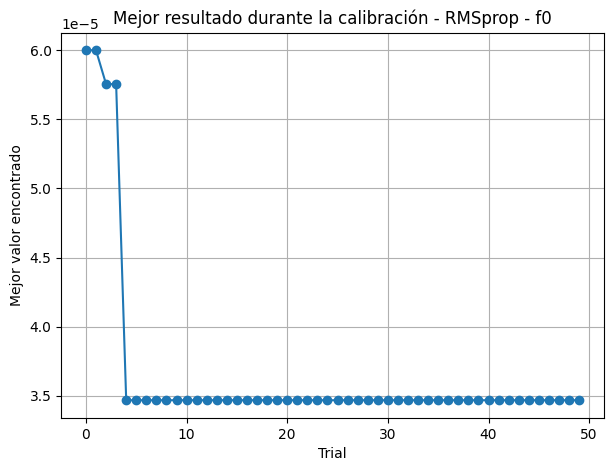

,number,value,params_alpha,params_beta
4,4,0.000035,0.635569,0.803956
22,22,0.000035,0.750889,0.825197
34,34,0.000035,0.498118,0.852871
29,29,0.000039,0.429338,0.836169
37,37,0.000039,0.525564,0.846672
31,31,0.000042,0.751552,0.834456
15,15,0.000043,0.290238,0.808777
41,41,0.000044,0.392396,0.845932
43,43,0.000047,0.762578,0.863082
14,14,0.000050,0.832916,0.805904


In [ ]:
study_f0_rms = calibrar_rmsprop(f0,puntos_iniciales)

graficar_trials(study_f0_rms,"RMSprop - f0")
mostrar_trials(study_f0_rms)

Para $f_1$ la situación es más difícil. Como vimos en el análisis de puntos críticos, esta función tiene muchísimos mínimos locales, uno en cada "valle" de su superficie.

Con alpha pequeños, cada corrida baja al valle más cercano a su punto inicial y se queda ahí, porque sus pasos no alcanzan para saltar al siguiente valle. Por eso muchos trials terminan prácticamente con el mismo valor promedio: no importa el valor exacto de alpha, todos se quedan atrapados cerca de donde empezaron.

Solo los alpha más grandes logran que el algoritmo "brinque" de un valle a otro y se acerque al centro. Aun así, el mejor promedio no llega a 0, ya que en 25 iteraciones no todas las corridas alcanzan el mínimo global en (0,0). Esto muestra que RMSprop ayuda, pero no resuelve por completo el problema de los mínimos locales.

[I 2026-09-27 18:38:16,688] A new study created in memory with name: no-name-8278da93-22f9-4687-8c57-da328823c375
[I 2026-09-27 18:38:16,734] Trial 0 finished with value: 10.989832592010497 and parameters: {'alpha': 0.29772657296043803, 'beta': 0.8310716743038133}. Best is trial 0 with value: 10.989832592010497.
[I 2026-09-27 18:38:16,776] Trial 1 finished with value: 14.515124130249024 and parameters: {'alpha': 0.0006737038294103143, 'beta': 0.9848573102465352}. Best is trial 0 with value: 10.989832592010497.
[I 2026-09-27 18:38:16,830] Trial 2 finished with value: 4.652991104125976 and parameters: {'alpha': 0.5668469798536888, 'beta': 0.8768040695589394}. Best is trial 2 with value: 4.652991104125976.
[I 2026-09-27 18:38:16,917] Trial 3 finished with value: 14.528588485717773 and parameters: {'alpha': 0.00010941129201639613, 'beta': 0.9308396719206011}. Best is trial 2 with value: 4.652991104125976.
[I 2026-09-27 18:38:17,015] Trial 4 finished with value: 5.336058807373047 and parame

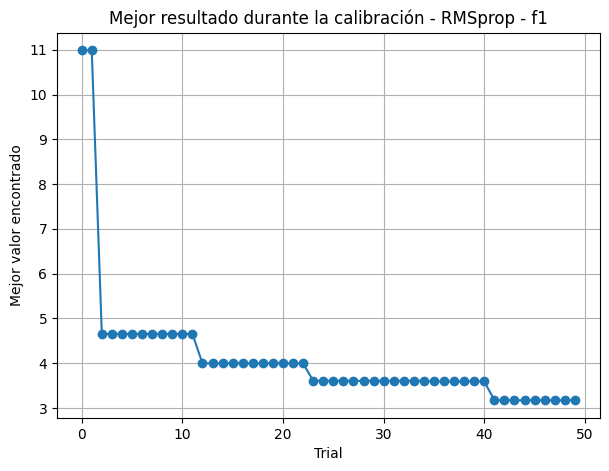

,number,value,params_alpha,params_beta
41,41,3.171894,0.553678,0.916448
35,35,3.591732,0.472119,0.914257
23,23,3.604476,0.409765,0.928471
46,46,3.757588,0.502456,0.863784
47,47,3.938478,0.354020,0.868848
12,12,3.996178,0.661349,0.907157
31,31,4.285399,0.483126,0.933962
36,36,4.342107,0.714582,0.921212
13,13,4.361592,0.439903,0.974154
27,27,4.463408,0.496315,0.935279


In [ ]:
study_f1_rms = calibrar_rmsprop(f1,puntos_iniciales)


graficar_trials(study_f1_rms, "RMSprop - f1")
mostrar_trials(study_f1_rms)

Para $f_2$ los resultados refuerzan la necesidad de la calibración. Los trials con alpha pequeño terminan con valores muy grandes, y los mejores usan alpha altos.

La explicación es la misma que en $f_0$: como RMSprop da pasos de tamaño parecido a alpha, con un alpha pequeño el algoritmo no alcanza a recorrer en 25 iteraciones la distancia desde el punto inicial hasta alguno de los cuatro mínimos, y se queda en zonas donde la función todavía vale cientos o miles.


[I 2026-09-27 18:38:20,278] A new study created in memory with name: no-name-214a7086-860b-4a48-a54b-6acbd54b87bb
[I 2026-09-27 18:38:20,316] Trial 0 finished with value: 0.6825393613049527 and parameters: {'alpha': 0.29772657296043803, 'beta': 0.8310716743038133}. Best is trial 0 with value: 0.6825393613049527.
[I 2026-09-27 18:38:20,346] Trial 1 finished with value: 4941.764288330078 and parameters: {'alpha': 0.0006737038294103143, 'beta': 0.9848573102465352}. Best is trial 0 with value: 0.6825393613049527.
[I 2026-09-27 18:38:20,378] Trial 2 finished with value: 1.5861139291777362 and parameters: {'alpha': 0.5668469798536888, 'beta': 0.8768040695589394}. Best is trial 0 with value: 0.6825393613049527.
[I 2026-09-27 18:38:20,407] Trial 3 finished with value: 5121.096142578125 and parameters: {'alpha': 0.00010941129201639613, 'beta': 0.9308396719206011}. Best is trial 0 with value: 0.6825393613049527.
[I 2026-09-27 18:38:20,438] Trial 4 finished with value: 3.2760645472371834 and para

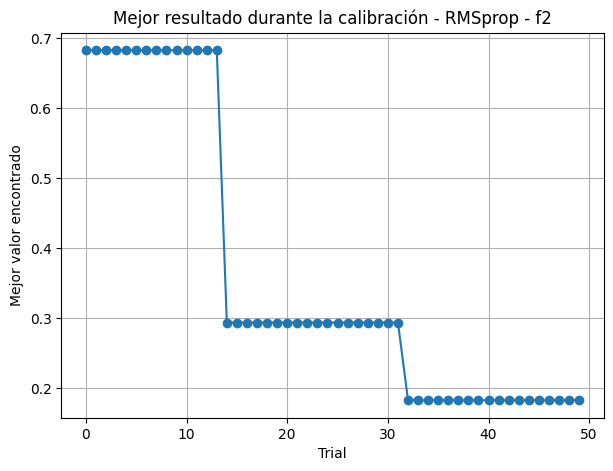

,number,value,params_alpha,params_beta
32,32,0.183064,0.504539,0.986506
14,14,0.293968,0.381140,0.986530
21,21,0.382929,0.302179,0.989116
28,28,0.393034,0.288615,0.989599
15,15,0.430049,0.547961,0.986259
43,43,0.453091,0.549150,0.987745
20,20,0.497026,0.355641,0.978556
49,49,0.617975,0.538707,0.977557
33,33,0.626722,0.435809,0.967195
31,31,0.660724,0.256046,0.989189


In [ ]:
study_f2_rms = calibrar_rmsprop(f2,puntos_iniciales)


graficar_trials(study_f2_rms, "RMSprop - f2")
mostrar_trials(study_f2_rms)

[I 2026-09-27 18:38:22,126] A new study created in memory with name: no-name-f9e75648-15b9-4b0a-8947-6711a6f71614
[I 2026-09-27 18:38:22,150] Trial 0 finished with value: 4.901919819531031e-05 and parameters: {'alpha': 0.29772657296043803}. Best is trial 0 with value: 4.901919819531031e-05.
[I 2026-09-27 18:38:22,173] Trial 1 finished with value: 87.031640625 and parameters: {'alpha': 0.00045096258539933573}. Best is trial 0 with value: 4.901919819531031e-05.
[I 2026-09-27 18:38:22,193] Trial 2 finished with value: 83.23548278808593 and parameters: {'alpha': 0.0006737038294103143}. Best is trial 0 with value: 4.901919819531031e-05.
[I 2026-09-27 18:38:22,213] Trial 3 finished with value: 4.627669150067959e-05 and parameters: {'alpha': 0.7793505519115}. Best is trial 3 with value: 4.627669150067959e-05.
[I 2026-09-27 18:38:22,231] Trial 4 finished with value: 9.722068170958664e-06 and parameters: {'alpha': 0.5668469798536888}. Best is trial 4 with value: 9.722068170958664e-06.
[I 2026-0

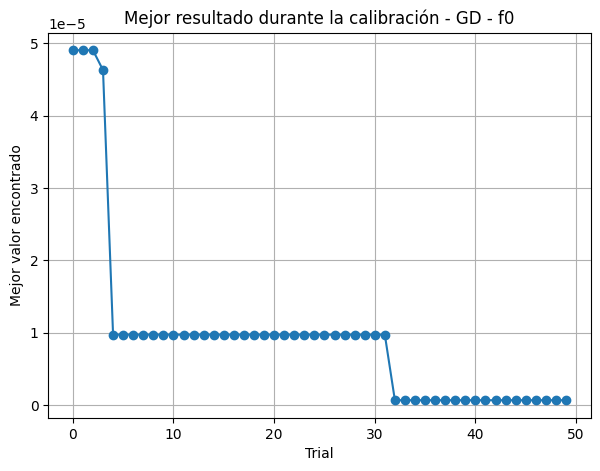

,number,value,params_alpha
32,32,6.697090e-07,0.521885
42,42,1.922033e-06,0.526089
45,45,4.731815e-06,0.469685
4,4,9.722068e-06,0.566847
30,30,1.089482e-05,0.509195
29,29,1.152149e-05,0.431719
25,25,1.792386e-05,0.550538
36,36,2.676533e-05,0.340480
20,20,2.708835e-05,0.371319
21,21,2.984033e-05,0.370128


In [ ]:
study_f0_gd = calibrar_descenso_gradiente(
    f0, puntos_iniciales)

graficar_trials(study_f0_gd, "GD - f0")
mostrar_trials(study_f0_gd)

[I 2026-09-27 18:38:23,409] A new study created in memory with name: no-name-375e10f9-5ca7-409b-93e0-1f5c5612d268
[I 2026-09-27 18:38:23,453] Trial 0 finished with value: 9.536270904541016 and parameters: {'alpha': 0.29772657296043803}. Best is trial 0 with value: 9.536270904541016.
[I 2026-09-27 18:38:23,494] Trial 1 finished with value: 14.526875495910645 and parameters: {'alpha': 0.00045096258539933573}. Best is trial 0 with value: 9.536270904541016.
[I 2026-09-27 18:38:23,534] Trial 2 finished with value: 14.52615566253662 and parameters: {'alpha': 0.0006737038294103143}. Best is trial 0 with value: 9.536270904541016.
[I 2026-09-27 18:38:23,578] Trial 3 finished with value: 13.45921573638916 and parameters: {'alpha': 0.7793505519115}. Best is trial 0 with value: 9.536270904541016.
[I 2026-09-27 18:38:23,622] Trial 4 finished with value: 9.364434051513673 and parameters: {'alpha': 0.5668469798536888}. Best is trial 4 with value: 9.364434051513673.
[I 2026-09-27 18:38:23,662] Trial 5

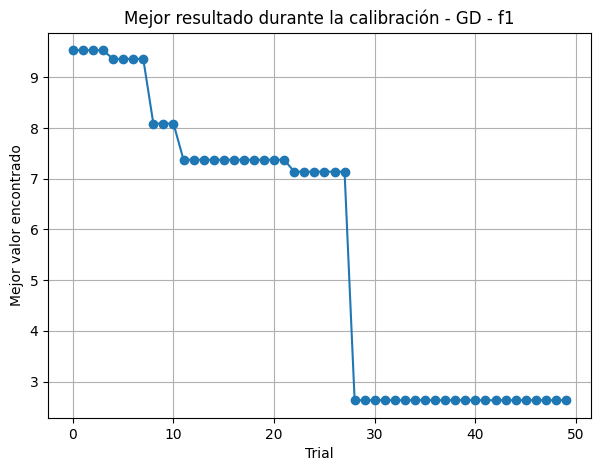

,number,value,params_alpha
28,28,2.632050,0.155179
46,46,3.753138,0.218075
45,45,4.470042,0.220173
29,29,5.219042,0.144270
36,36,5.259908,0.157494
48,48,5.406172,0.584932
35,35,5.826629,0.142011
31,31,6.037965,0.138437
39,39,6.062541,0.167885
49,49,6.147461,0.208675


In [ ]:
study_f1_gd = calibrar_descenso_gradiente(
    f1, puntos_iniciales)

graficar_trials(study_f1_gd, "GD - f1")
mostrar_trials(study_f1_gd)

En la calibración de $f_2$ con descenso de gradiente, muchos trials aparecen como fallidos con el mensaje The value nan is not acceptable. Es el mismo fenómeno explicado en la sección del descenso de gradiente.

Por eso los únicos trials válidos son los de alpha muy pequeño (del orden de 0.005 o menos). Aquí aparece el dilema del descenso de gradiente con esta función: un alpha grande explota en los bordes, donde la pendiente es enorme, pero un alpha pequeño avanza muy lento cerca de los mínimos, donde la pendiente es pequeña. RMSprop no tiene este problema porque divide el gradiente entre su propio tamaño, así que su paso nunca crece de esa manera.

[I 2026-09-27 18:38:25,814] A new study created in memory with name: no-name-098a196b-804b-4eb1-bbe6-92b3fd6e6039
[W 2026-09-27 18:38:25,844] Trial 0 failed with parameters: {'alpha': 0.29772657296043803} because of the following error: The value nan is not acceptable.
[W 2026-09-27 18:38:25,846] Trial 0 failed with value nan.
[I 2026-09-27 18:38:25,874] Trial 1 finished with value: 7.68495090007782 and parameters: {'alpha': 0.00045096258539933573}. Best is trial 1 with value: 7.68495090007782.
[I 2026-09-27 18:38:25,901] Trial 2 finished with value: 1.8410854667425156 and parameters: {'alpha': 0.0006737038294103143}. Best is trial 2 with value: 1.8410854667425156.
[W 2026-09-27 18:38:25,928] Trial 3 failed with parameters: {'alpha': 0.7793505519115} because of the following error: The value nan is not acceptable.
[W 2026-09-27 18:38:25,929] Trial 3 failed with value nan.
[W 2026-09-27 18:38:25,960] Trial 4 failed with parameters: {'alpha': 0.5668469798536888} because of the following 

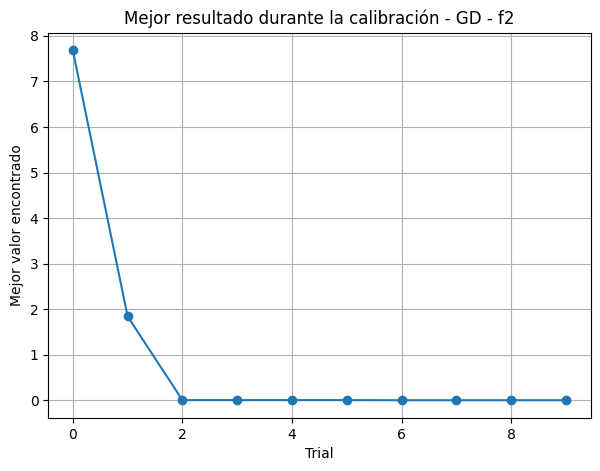

,number,value,params_alpha
11,11,0.000356,0.004401
5,5,0.002542,0.004139
10,10,0.045025,0.002623
26,26,0.045420,0.002624
13,13,0.227673,0.001138
2,2,1.841085,0.000674
1,1,7.684951,0.000451
20,20,154.095300,0.000134
9,9,187.771593,0.000121
6,6,225.996829,0.000109


In [ ]:
study_f2_gd = calibrar_descenso_gradiente(f2, puntos_iniciales)
graficar_trials(study_f2_gd, "GD - f2")
mostrar_trials(study_f2_gd)

In [ ]:
print("Mejores hiperparámetros:")

print("\n RMSprop")
print("   f0:", study_f0_rms.best_params, "->", study_f0_rms.best_value)
print("   f1:", study_f1_rms.best_params, "->", study_f1_rms.best_value)
print("   f2:", study_f2_rms.best_params, "->", study_f2_rms.best_value)

print("\n Descenso de Gradiente")
print("   f0:", study_f0_gd.best_params, "->", study_f0_gd.best_value)
print("   f1:", study_f1_gd.best_params, "->", study_f1_gd.best_value)
print("   f2:", study_f2_gd.best_params, "->", study_f2_gd.best_value)




Mejores hiperparámetros:

 RMSprop
   f0: {'alpha': 0.6355686046369864, 'beta': 0.803955529418088} -> 3.4686610524659046e-05
   f1: {'alpha': 0.5536779749826658, 'beta': 0.9164483865992141} -> 3.17189416885376
   f2: {'alpha': 0.5045385585816264, 'beta': 0.9865062408197475} -> 0.18306407977543132

 Descenso de Gradiente
   f0: {'alpha': 0.5218847036131544} -> 6.697089929730282e-07
   f1: {'alpha': 0.15517912489217012} -> 2.6320504188537597
   f2: {'alpha': 0.004401490332482655} -> 0.00035618619258457327


In [ ]:
alpha_f0_rms = study_f0_rms.best_params["alpha"]
beta_f0_rms = study_f0_rms.best_params["beta"]

alpha_f1_rms = study_f1_rms.best_params["alpha"]
beta_f1_rms = study_f1_rms.best_params["beta"]

alpha_f2_rms = study_f2_rms.best_params["alpha"]
beta_f2_rms = study_f2_rms.best_params["beta"]


alpha_f0_gd = study_f0_gd.best_params["alpha"]

alpha_f1_gd = study_f1_gd.best_params["alpha"]

alpha_f2_gd = study_f2_gd.best_params["alpha"]

**c) ¿Porqué el algoritmo RMS prop es más efectivo en evitar atascarse
en puntos silla que el algoritmo del descenso del gradiente?**


RMSprop puede ser más efectivo que el descenso de gradiente para evitar o atravesar regiones cercanas a puntos silla debido a que adapta el tamaño del paso de actualización según el comportamiento reciente de los gradientes.

En el descenso de gradiente, la misma tasa de aprendizaje alpha se utiliza para actualizar todas las variables. Esto puede hacer que, cuando el gradiente es pequeño en una determinada dirección, los movimientos sean muy lentos y el algoritmo permanezca durante varias iteraciones en una región cercana a un punto silla.

RMSprop, en cambio, mantiene un promedio móvil de los cuadrados de los gradientes y utiliza este valor para ajustar la magnitud de las actualizaciones. De esta manera, las direcciones en las que los gradientes han sido grandes reciben pasos relativamente menores, mientras que las direcciones con gradientes pequeños pueden recibir pasos relativamente mayores.

Con esto RMSprop puede desplazarse de manera más efectiva por regiones donde el gradiente es pequeño. Por esta razón, puede presentar una convergencia más estable y reducir el tiempo que permanece en regiones poco favorables de la función.

Esto no significa que RMSprop siempre evite los puntos silla mejor que el descenso de gradiente. Su comportamiento depende de la función y de los hiperparámetros utilizados.


**Relación con nuestros resultados:** en nuestras pruebas no se puede aislar el efecto de un punto silla en particular, pero sí se observa la propiedad que explica la respuesta. En la prueba unitaria 2 de RMSprop (al final del cuaderno) se comprueba que su primer paso mide lo mismo sin importar si la pendiente es grande o pequeña, mientras que en el descenso de gradiente el paso es proporcional a la pendiente.

Esto se nota en $f_2$, que tiene 4 puntos silla. El descenso de gradiente solo funcionó con un α muy pequeño (0.0044), necesitó 30 iteraciones en promedio para converger, y las corridas desde (-8, 8) y (-9, -9) no terminaron de llegar en 50 iteraciones (quedaron en 0.00088 y 0.0021), porque avanzan cada vez más lento donde la pendiente se hace pequeña. RMSprop, con α = 0.505, convergió en 25.1 iteraciones en promedio en las corridas que lo lograron.

d) Para los mejores valores encontrados, en cada funcion, por un máximo de 50 iteraciones (para el algoritmo del descenso del gradiente,
y RMS prop):
1) Ejecute el algoritmo 10 corridas diferentes, y documente en una
tabla la cantidad de iteraciones para converger a el o los puntos
minimos (indique si convergió).
2) Muestre el valor promedio de la función minimizada para las
10 corridas, y la cantidad de iteraciones promedio en converger.

Los 10 puntos iniciales y las funciones ejecutar_gd_10_veces y ejecutar_rmsprop_10_veces se definieron en la sección de ajuste de hiperparámetros, porque también se utilizan para calibrar.

In [ ]:
def mostrar_resultados(resultados, titulo):
    """!
    @brief Construye e imprime una tabla resumen a partir de una lista
    de resultados de corridas de un algoritmo de optimización.

    @param resultados Lista de diccionarios con las claves "ejecucion",
          "x_inicial", "y_inicial", "valor_final", "iteraciones",
          "convergio" e "historial_theta".
    @param titulo Título impreso antes de la tabla.
    @return tabla DataFrame con las columnas Ejecución, Punto inicial,
          Punto final, Valor final, Iteraciones y Convergió. El punto
          final es la última posición guardada en historial_theta (en
          PSO, la mejor posición del enjambre).
    """

    datos = []

    for resultado in resultados:

        if resultado["convergio"]:
            convergio = "Sí"
        else:
            convergio = "No"

        # Punto (x, y) donde terminó la corrida: el último del historial
        punto_final = resultado["historial_theta"][-1]

        datos.append({
            "Ejecución": resultado["ejecucion"],
            "Punto inicial": (
                resultado["x_inicial"],
                resultado["y_inicial"]
            ),
            "Punto final": (
                round(punto_final[0].item(), 4),
                round(punto_final[1].item(), 4)
            ),
            "Valor final": resultado["valor_final"],
            "Iteraciones": resultado["iteraciones"],
            "Convergió": convergio
        })

    tabla = pd.DataFrame(datos)

    print(titulo)

    display(tabla)

    return tabla


In [ ]:
resultados_gd_f0 = ejecutar_gd_10_veces(
    f0,
    puntos_iniciales,
    alpha_f0_gd,
    P=50
)

resultados_gd_f1 = ejecutar_gd_10_veces(
    f1,
    puntos_iniciales,
    alpha_f1_gd,
    P=50
)

resultados_gd_f2 = ejecutar_gd_10_veces(
    f2,
    puntos_iniciales,
    alpha_f2_gd,
    P=50
)

In [ ]:
tabla_gd_f0 = mostrar_resultados(
    resultados_gd_f0,
    "Descenso de Gradiente - f0"
)

tabla_gd_f1 = mostrar_resultados(
    resultados_gd_f1,
    "Descenso de Gradiente - f1"
)

tabla_gd_f2 = mostrar_resultados(
    resultados_gd_f2,
    "Descenso de Gradiente - f2"
)

Descenso de Gradiente - f0


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(-0.0008, -0.0008)",1.269105e-06,3,Sí
1,2,"(8.0, -8.0)","(-0.0007, 0.0007)",8.999752e-07,3,Sí
2,3,"(-8.0, 8.0)","(0.0007, -0.0007)",8.999752e-07,3,Sí
3,4,"(-9.0, -9.0)","(0.0008, 0.0008)",1.139035e-06,3,Sí
4,5,"(6.0, 2.0)","(-0.0005, -0.0002)",2.812427e-07,3,Sí
5,6,"(-6.0, 2.0)","(0.0005, -0.0002)",2.812427e-07,3,Sí
6,7,"(2.0, -6.0)","(-0.0002, 0.0005)",2.812427e-07,3,Sí
7,8,"(-2.0, 6.0)","(0.0002, -0.0005)",2.812427e-07,3,Sí
8,9,"(4.0, -9.0)","(-0.0003, 0.0008)",6.820143e-07,3,Sí
9,10,"(-4.0, 9.0)","(0.0003, -0.0008)",6.820143e-07,3,Sí


Descenso de Gradiente - f1


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(-0.1109, -0.1109)",1.003777,50,No
1,2,"(8.0, -8.0)","(-0.7896, 0.7896)",4.360595,50,No
2,3,"(-8.0, 8.0)","(0.7896, -0.7896)",4.360595,50,No
3,4,"(-9.0, -9.0)","(-0.5667, -0.5667)",4.460177,50,No
4,5,"(6.0, 2.0)","(-0.0885, -0.1719)",1.322460,50,No
5,6,"(-6.0, 2.0)","(0.0885, -0.1719)",1.322460,50,No
6,7,"(2.0, -6.0)","(-0.1719, 0.0885)",1.322460,50,No
7,8,"(-2.0, 6.0)","(0.1719, -0.0885)",1.322460,50,No
8,9,"(4.0, -9.0)","(-0.5586, -0.141)",3.422760,50,No
9,10,"(-4.0, 9.0)","(0.5586, 0.141)",3.422760,50,No


Descenso de Gradiente - f2


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(-3.7788, -3.2817)",0.000090,10,Sí
1,2,"(8.0, -8.0)","(3.001, 1.9975)",0.000095,44,Sí
2,3,"(-8.0, 8.0)","(2.9968, 2.0076)",0.000880,50,No
3,4,"(-9.0, -9.0)","(2.9951, 2.0116)",0.002051,50,No
4,5,"(6.0, 2.0)","(3.0011, 1.9974)",0.000099,44,Sí
5,6,"(-6.0, 2.0)","(-2.8055, 3.1303)",0.000045,19,Sí
6,7,"(2.0, -6.0)","(3.5847, -1.8506)",0.000089,38,Sí
7,8,"(-2.0, 6.0)","(-2.8038, 3.1312)",0.000061,20,Sí
8,9,"(4.0, -9.0)","(2.999, 2.0025)",0.000096,44,Sí
9,10,"(-4.0, 9.0)","(-3.7787, -3.2821)",0.000056,21,Sí


In [ ]:
resultados_rms_f0 = ejecutar_rmsprop_10_veces(
    f0,
    puntos_iniciales,
    alpha_f0_rms,
    beta_f0_rms,
    P=50
)

resultados_rms_f1 = ejecutar_rmsprop_10_veces(
    f1,
    puntos_iniciales,
    alpha_f1_rms,
    beta_f1_rms,
    P=50
)

resultados_rms_f2 = ejecutar_rmsprop_10_veces(
    f2,
    puntos_iniciales,
    alpha_f2_rms,
    beta_f2_rms,
    P=50
)

In [ ]:
tabla_rms_f0 = mostrar_resultados(
    resultados_rms_f0,
    "RMSprop - f0"
)

tabla_rms_f1 = mostrar_resultados(
    resultados_rms_f1,
    "RMSprop - f1"
)

tabla_rms_f2 = mostrar_resultados(
    resultados_rms_f2,
    "RMSprop - f2"
)

RMSprop - f0


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(0.0048, 0.0048)",0.000047,25,Sí
1,2,"(8.0, -8.0)","(0.0027, -0.0027)",0.000015,22,Sí
2,3,"(-8.0, 8.0)","(-0.0027, 0.0027)",0.000015,22,Sí
3,4,"(-9.0, -9.0)","(-0.0041, -0.0041)",0.000034,24,Sí
4,5,"(6.0, 2.0)","(0.0071, 0.0)",0.000050,16,Sí
5,6,"(-6.0, 2.0)","(-0.0071, 0.0)",0.000050,16,Sí
6,7,"(2.0, -6.0)","(0.0, -0.0071)",0.000050,16,Sí
7,8,"(-2.0, 6.0)","(-0.0, 0.0071)",0.000050,16,Sí
8,9,"(4.0, -9.0)","(-0.0, -0.0041)",0.000017,24,Sí
9,10,"(-4.0, 9.0)","(0.0, 0.0041)",0.000017,24,Sí


RMSprop - f1


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(-0.5042, -0.5042)",4.268571,50,No
1,2,"(8.0, -8.0)","(-0.2305, 0.2305)",2.488861,50,No
2,3,"(-8.0, 8.0)","(0.2305, -0.2305)",2.488861,50,No
3,4,"(-9.0, -9.0)","(-0.3098, -0.3098)",3.226715,50,No
4,5,"(6.0, 2.0)","(0.2264, -0.3416)",3.024273,50,No
5,6,"(-6.0, 2.0)","(-0.2264, -0.3416)",3.024273,50,No
6,7,"(2.0, -6.0)","(-0.3416, -0.2264)",3.024273,50,No
7,8,"(-2.0, 6.0)","(0.3416, 0.2264)",3.024273,50,No
8,9,"(4.0, -9.0)","(0.3141, -0.4054)",3.574421,50,No
9,10,"(-4.0, 9.0)","(-0.3141, 0.4054)",3.574421,50,No


RMSprop - f2


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(2.9563, 2.1036)",0.170069,50,No
1,2,"(8.0, -8.0)","(3.5857, -1.8632)",0.003322,50,No
2,3,"(-8.0, 8.0)","(-2.8069, 3.1315)",0.000099,32,Sí
3,4,"(-9.0, -9.0)","(-3.78, -3.2844)",0.000069,38,Sí
4,5,"(6.0, 2.0)","(3.5842, -1.8466)",0.000034,11,Sí
5,6,"(-6.0, 2.0)","(-2.8042, 3.13)",0.000094,15,Sí
6,7,"(2.0, -6.0)","(3.5842, -1.8456)",0.000089,23,Sí
7,8,"(-2.0, 6.0)","(-2.8039, 3.1312)",0.000048,18,Sí
8,9,"(4.0, -9.0)","(-3.7797, -3.2847)",0.000098,39,Sí
9,10,"(-4.0, 9.0)","(-3.0228, 3.1289)",1.656719,50,No


In [ ]:
def calcular_promedios(resultados):
    """!
    @brief Calcula el promedio del valor final, el promedio de
    iteraciones entre las corridas convergentes, y la cantidad de
    corridas convergentes.

    @param resultados Lista de diccionarios con las claves
          "valor_final", "iteraciones" y "convergio".
    @return promedio_funcion Promedio del valor final de f(x, y) entre
          todas las corridas.
    @return promedio_iteraciones Promedio de iteraciones entre las
          corridas convergentes, o None si ninguna convergió.
    @return cantidad_convergencias Cantidad de corridas que
          convergieron.
    """

    promedio_funcion = sum(
        resultado["valor_final"]
        for resultado in resultados
    ) / len(resultados)

    resultados_convergentes = [
        resultado
        for resultado in resultados
        if resultado["convergio"]
    ]

    if len(resultados_convergentes) > 0:

        promedio_iteraciones = sum(
            resultado["iteraciones"]
            for resultado in resultados_convergentes
        ) / len(resultados_convergentes)

    else:
        promedio_iteraciones = None

    cantidad_convergencias = len(
        resultados_convergentes
    )

    return (
        promedio_funcion,
        promedio_iteraciones,
        cantidad_convergencias
    )


In [ ]:
for nombre, resultados in [
    ("GD - f0", resultados_gd_f0),
    ("GD - f1", resultados_gd_f1),
    ("GD - f2", resultados_gd_f2),
    ("RMSprop - f0", resultados_rms_f0),
    ("RMSprop - f1", resultados_rms_f1),
    ("RMSprop - f2", resultados_rms_f2)
]:

    promedio_funcion, promedio_iteraciones, cantidad = \
        calcular_promedios(resultados)

    print(nombre)
    print("Promedio de f:", promedio_funcion)
    print("Promedio de iteraciones:", promedio_iteraciones)
    print("Corridas convergentes:", cantidad, "/ 10")
    print()

GD - f0
Promedio de f: 6.697089929730282e-07
Promedio de iteraciones: 3.0
Corridas convergentes: 10 / 10

GD - f1
Promedio de f: 2.6320504188537597
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

GD - f2
Promedio de f: 0.00035618619258457327
Promedio de iteraciones: 30.0
Corridas convergentes: 8 / 10

RMSprop - f0
Promedio de f: 3.4686610524659046e-05
Promedio de iteraciones: 20.5
Corridas convergentes: 10 / 10

RMSprop - f1
Promedio de f: 3.17189416885376
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

RMSprop - f2
Promedio de f: 0.18306407977543132
Promedio de iteraciones: 25.142857142857142
Corridas convergentes: 7 / 10



In [ ]:
def obtener_mejor_corrida(resultados):
    """!
    @brief Obtiene la mejor corrida de una lista de resultados: la que
    convergió en menos iteraciones, o si ninguna convergió, la de menor
    valor final.

    @param resultados Lista de diccionarios con las claves
          "convergio", "iteraciones" y "valor_final".
    @return mejor Diccionario correspondiente a la mejor corrida
          encontrada.
    """

    convergentes = [
        resultado
        for resultado in resultados
        if resultado["convergio"]
    ]

    if len(convergentes) > 0:

        mejor = min(
            convergentes,
            key=lambda resultado: resultado["iteraciones"]
        )

    else:

        mejor = min(
            resultados,
            key=lambda resultado: resultado["valor_final"]
        )

    return mejor


In [ ]:
mejor_gd_f0 = obtener_mejor_corrida(resultados_gd_f0)
mejor_gd_f1 = obtener_mejor_corrida(resultados_gd_f1)
mejor_gd_f2 = obtener_mejor_corrida(resultados_gd_f2)

mejor_rms_f0 = obtener_mejor_corrida(resultados_rms_f0)
mejor_rms_f1 = obtener_mejor_corrida(resultados_rms_f1)
mejor_rms_f2 = obtener_mejor_corrida(resultados_rms_f2)

In [ ]:
def graficar_mejor_corrida(
    resultado,
    funcion,
    nombre
):
    """!
    @brief Grafica la curva de aprendizaje y la trayectoria de la mejor
    corrida obtenida por un algoritmo de optimización.

    @param resultado Diccionario con las claves "historial_theta" y
          "historial_f" de la corrida a graficar.
    @param funcion Función optimizada, usada para graficar la
          trayectoria sobre sus curvas de nivel.
    @param nombre Nombre usado en los títulos de las gráficas.
    @return None. La función muestra las gráficas directamente.
    """

    historial = resultado["historial_theta"]

    x_history = []
    y_history = []

    for punto in historial:

        if isinstance(punto, torch.Tensor):
            x_history.append(punto[0].item())
            y_history.append(punto[1].item())

        else:
            x_history.append(punto[0])
            y_history.append(punto[1])

    plt.figure(figsize=(7, 5))

    plt.plot(
        resultado["historial_f"],
        marker="o"
    )

    plt.xlabel("Iteración")
    plt.ylabel("f(x,y)")
    plt.title(
        f"Curva de aprendizaje - {nombre}"
    )

    plt.grid()
    plt.show()

    graficar_funcion(
        funcion,
        f"Trayectoria - {nombre}",
        x_history,
        y_history
    )


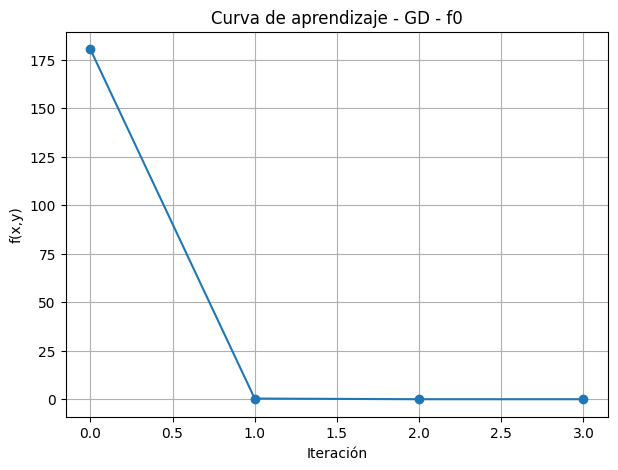

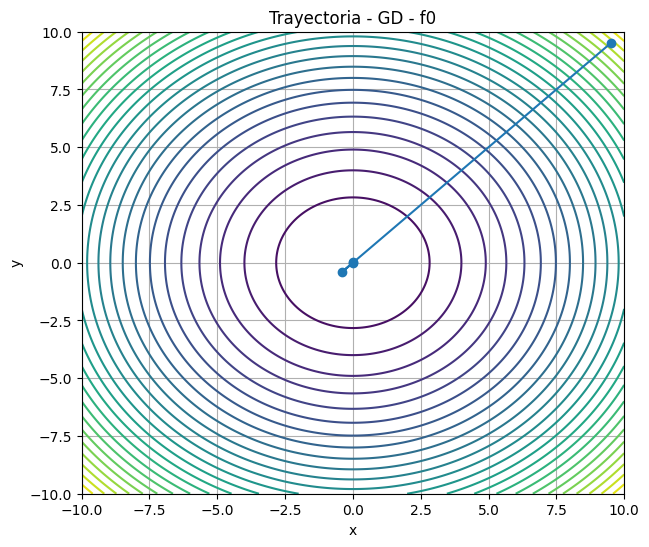

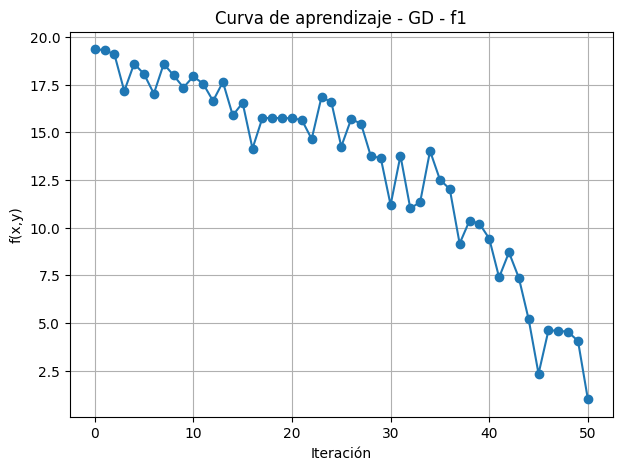

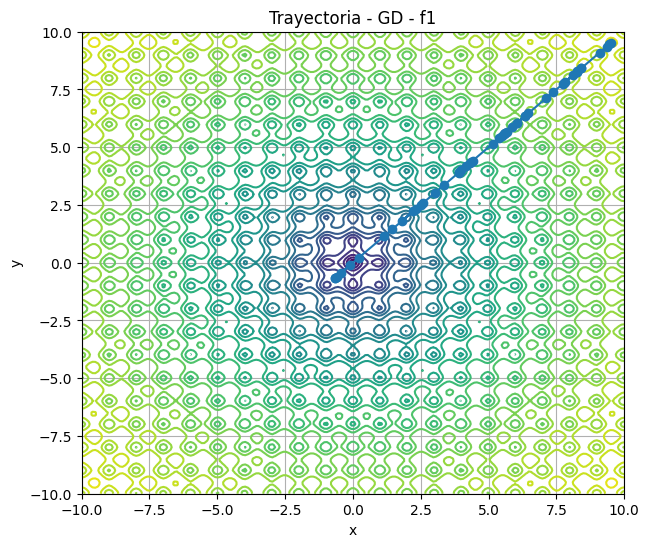

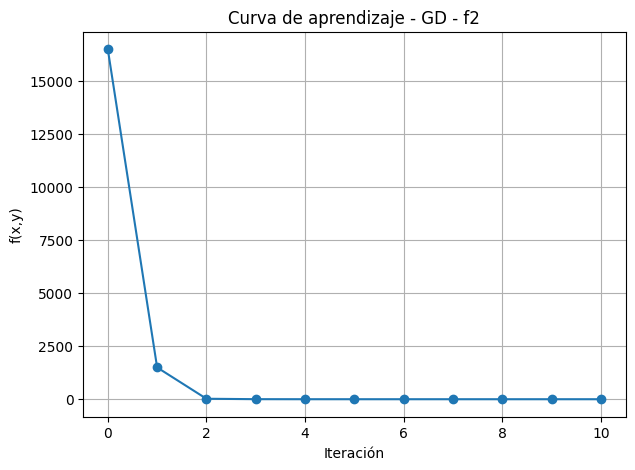

...

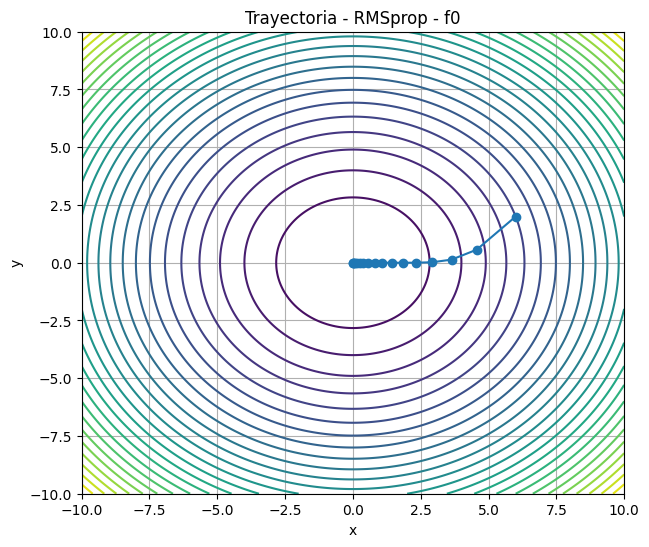

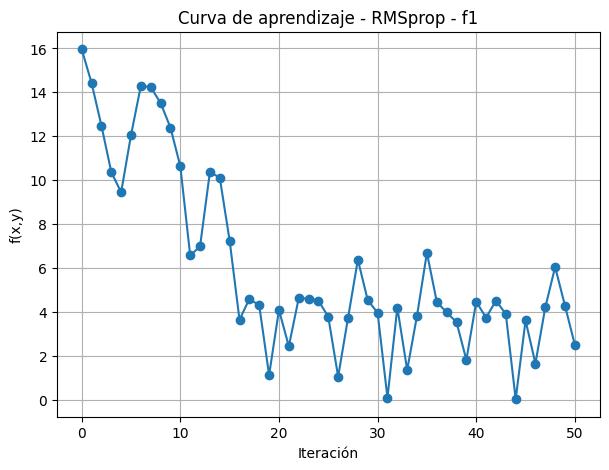

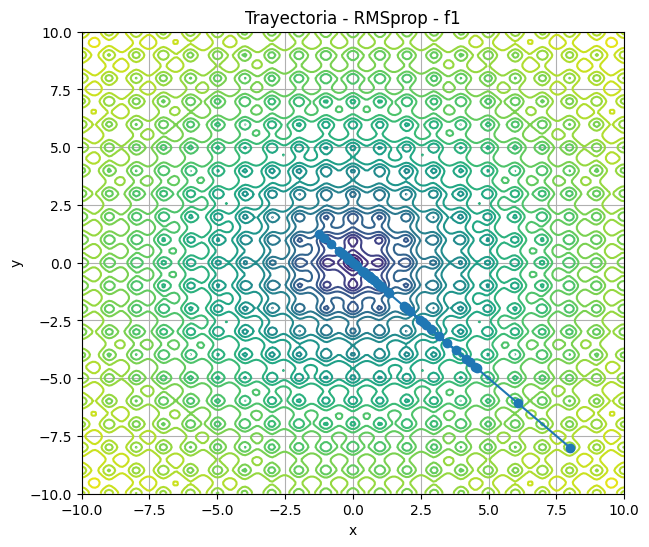

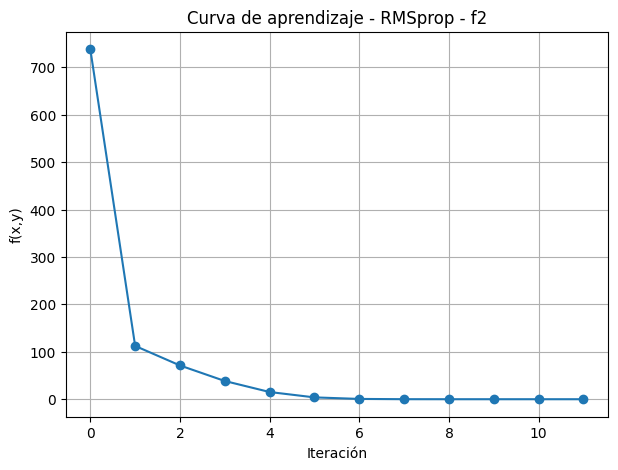

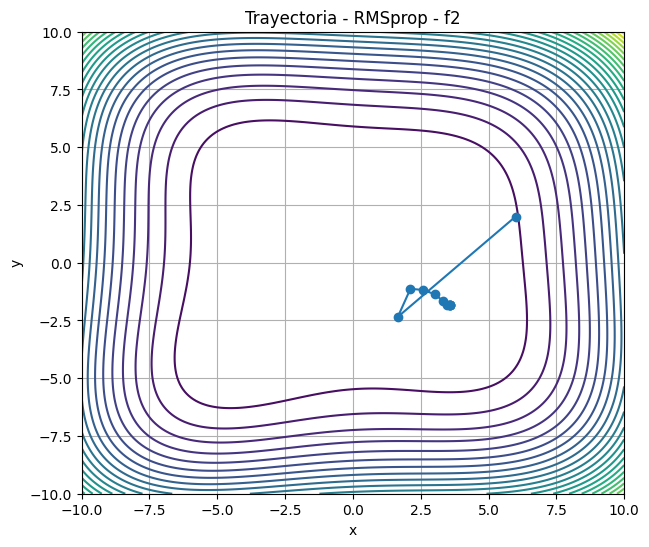

In [ ]:
graficar_mejor_corrida(
    mejor_gd_f0,
    f0,
    "GD - f0"
)

graficar_mejor_corrida(
    mejor_gd_f1,
    f1,
    "GD - f1"
)

graficar_mejor_corrida(
    mejor_gd_f2,
    f2,
    "GD - f2"
)

graficar_mejor_corrida(
    mejor_rms_f0,
    f0,
    "RMSprop - f0"
)

graficar_mejor_corrida(
    mejor_rms_f1,
    f1,
    "RMSprop - f1"
)

graficar_mejor_corrida(
    mejor_rms_f2,
    f2,
    "RMSprop - f2"
)

f) Realice una comparativa entre el algoritmo del descenso del gradiente y el algoritmo RMS prop. según los resultados obtenidos.

Para comparar ambos algoritmos juntamos los resultados de las 10 corridas en una sola tabla y en dos gráficas. Las funciones que las generan también se reutilizan en el punto 4, agregando PSO.

- **Valor final de las 10 corridas:** cada punto es una corrida y la línea roja es la tolerancia; los puntos por debajo de ella convergieron.
- **Curva de aprendizaje promedio:** el valor promedio de f en cada iteración, para ver qué tan rápido baja cada algoritmo.

In [ ]:
# Un color fijo por algoritmo, para que todas las gráficas sean consistentes
COLORES_ALGORITMOS = {
    "GD": "tab:blue",
    "RMSprop": "tab:orange",
    "PSO": "tab:green"
}


def resumen_comparativo(algoritmos):
    """!
    @brief Construye una tabla con el resumen de las 10 corridas de cada
    algoritmo en cada función, para compararlos lado a lado.

    @param algoritmos Diccionario con la forma
          {nombre_algoritmo: {nombre_funcion: resultados}}, donde
          resultados es la lista generada por las funciones
          ejecutar_*_10_veces.
    @return tabla DataFrame con las columnas Función, Algoritmo,
          Convergentes, Iteraciones promedio, Promedio de f, Mejor f y
          Peor f, agrupado por función.
    """

    filas = []

    for nombre_algoritmo, por_funcion in algoritmos.items():
        for nombre_funcion, resultados in por_funcion.items():

            promedio_funcion, promedio_iteraciones, cantidad = \
                calcular_promedios(resultados)

            valores = [r["valor_final"] for r in resultados]

            # Si ninguna corrida convergió no hay iteraciones promedio
            if promedio_iteraciones is None:
                promedio_iteraciones = "—"

            filas.append({
                "Función": nombre_funcion,
                "Algoritmo": nombre_algoritmo,
                "Convergentes": f"{cantidad} / {len(resultados)}",
                "Iteraciones promedio": promedio_iteraciones,
                "Promedio de f": promedio_funcion,
                "Mejor f": min(valores),
                "Peor f": max(valores)
            })

    tabla = pd.DataFrame(filas)

    # Agrupar por función para comparar los algoritmos lado a lado
    tabla = tabla.sort_values("Función", kind="stable").reset_index(drop=True)

    display(tabla)

    return tabla


def graficar_convergencias(algoritmos, titulo):
    """!
    @brief Grafica en barras cuántas de las 10 corridas convergieron,
    para cada algoritmo y cada función.

    @param algoritmos Diccionario con la forma
          {nombre_algoritmo: {nombre_funcion: resultados}}.
    @param titulo Título de la gráfica.
    @return None. La función muestra la gráfica directamente.
    """

    nombres_algoritmos = list(algoritmos.keys())
    nombres_funciones = list(algoritmos[nombres_algoritmos[0]].keys())

    # Ancho de cada barra, para que las de un mismo grupo quepan juntas
    ancho = 0.8 / len(nombres_algoritmos)

    plt.figure(figsize=(8, 5))

    for k, nombre_algoritmo in enumerate(nombres_algoritmos):

        posiciones = [j + k * ancho for j in range(len(nombres_funciones))]

        cantidades = [
            sum(1 for r in algoritmos[nombre_algoritmo][f] if r["convergio"])
            for f in nombres_funciones
        ]

        barras = plt.bar(
            posiciones,
            cantidades,
            width=ancho,
            label=nombre_algoritmo,
            color=COLORES_ALGORITMOS.get(nombre_algoritmo)
        )

        # Escribir la cantidad encima de cada barra
        plt.bar_label(barras)

    # Etiqueta de cada función en el centro de su grupo de barras
    centro = ancho * (len(nombres_algoritmos) - 1) / 2
    plt.xticks([j + centro for j in range(len(nombres_funciones))], nombres_funciones)

    plt.ylim(0, 11)
    plt.ylabel("Corridas que convergieron (de 10)")
    plt.title(titulo)
    plt.legend(loc="upper center")
    plt.grid(axis="y", alpha=0.3)
    plt.show()


def graficar_valores_finales(algoritmos, titulo, tolerancia=1e-4):
    """!
    @brief Grafica, para cada función, la distribución del valor final
    de las 10 corridas de cada algoritmo (diagrama de caja y un punto
    por corrida), junto con la línea de tolerancia de convergencia.

    @param algoritmos Diccionario con la forma
          {nombre_algoritmo: {nombre_funcion: resultados}}.
    @param titulo Título general de la figura.
    @param tolerancia Valor usado como criterio de convergencia. Los
          puntos por debajo de la línea convergieron. Por defecto 1e-4.
    @return None. La función muestra la gráfica directamente.
    """

    nombres_algoritmos = list(algoritmos.keys())
    nombres_funciones = list(algoritmos[nombres_algoritmos[0]].keys())

    fig, ejes = plt.subplots(1, len(nombres_funciones), figsize=(5 * len(nombres_funciones), 5))

    for j, nombre_funcion in enumerate(nombres_funciones):

        eje = ejes[j]

        datos = []

        for nombre_algoritmo in nombres_algoritmos:
            # Se evita el 0 exacto porque la escala es logarítmica
            valores = [
                max(r["valor_final"], 1e-12)
                for r in algoritmos[nombre_algoritmo][nombre_funcion]
            ]
            datos.append(valores)

        eje.boxplot(datos)

        # Un punto por corrida encima de cada caja
        for k, valores in enumerate(datos):
            eje.scatter(
                [k + 1] * len(valores),
                valores,
                color=COLORES_ALGORITMOS.get(nombres_algoritmos[k]),
                alpha=0.7,
                zorder=3
            )

        eje.axhline(tolerancia, color="red", linestyle="--", label="Tolerancia (1e-4)")

        eje.set_xticks(range(1, len(nombres_algoritmos) + 1))
        eje.set_xticklabels(nombres_algoritmos)
        eje.set_yscale("log")
        eje.set_title(nombre_funcion)
        eje.set_ylabel("Valor final de f (escala log)")
        eje.grid(alpha=0.3)
        eje.legend()

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def graficar_curvas_promedio(algoritmos, titulo, tolerancia=1e-4):
    """!
    @brief Grafica, para cada función, la curva de aprendizaje promedio
    de las 10 corridas de cada algoritmo: el valor promedio de f en
    cada iteración.

    @details Si una corrida convergió antes de la última iteración, se
    repite su último valor hasta el final, para que todas las corridas
    tengan el mismo largo y se puedan promediar.

    @param algoritmos Diccionario con la forma
          {nombre_algoritmo: {nombre_funcion: resultados}}.
    @param titulo Título general de la figura.
    @param tolerancia Valor usado como criterio de convergencia, que se
          dibuja como referencia. Por defecto 1e-4.
    @return None. La función muestra la gráfica directamente.
    """

    nombres_algoritmos = list(algoritmos.keys())
    nombres_funciones = list(algoritmos[nombres_algoritmos[0]].keys())

    fig, ejes = plt.subplots(1, len(nombres_funciones), figsize=(5 * len(nombres_funciones), 5))

    for j, nombre_funcion in enumerate(nombres_funciones):

        eje = ejes[j]

        for nombre_algoritmo in nombres_algoritmos:

            resultados = algoritmos[nombre_algoritmo][nombre_funcion]
            historiales = [r["historial_f"] for r in resultados]

            largo = max(len(h) for h in historiales)

            # Completar las corridas cortas repitiendo su último valor
            completos = [h + [h[-1]] * (largo - len(h)) for h in historiales]

            # Promedio de las corridas en cada iteración
            promedio = [
                sum(h[i] for h in completos) / len(completos)
                for i in range(largo)
            ]

            # Se evita el 0 exacto porque la escala es logarítmica
            promedio = [max(v, 1e-12) for v in promedio]

            eje.plot(
                range(largo),
                promedio,
                label=nombre_algoritmo,
                color=COLORES_ALGORITMOS.get(nombre_algoritmo)
            )

        eje.axhline(tolerancia, color="red", linestyle="--", label="Tolerancia (1e-4)")

        eje.set_yscale("log")
        eje.set_title(nombre_funcion)
        eje.set_xlabel("Iteración")
        eje.set_ylabel("Promedio de f (escala log)")
        eje.grid(alpha=0.3)
        eje.legend()

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

**Respuesta f)**

Con los mejores hiperparámetros de cada algoritmo y los mismos 10 puntos iniciales, los resultados fueron:

| Función | Algoritmo | Corridas que convergieron | Iteraciones promedio | Valor promedio de f |
|---|---|---|---|---|
| $f_0$ | GD (α = 0.522) | 10/10 | 3 | $6.7 \times 10^{-7}$ |
| $f_0$ | RMSprop (α = 0.636, β = 0.804) | 10/10 | 20.5 | $3.5 \times 10^{-5}$ |
| $f_1$ | GD (α = 0.171) | 0/10 | — | 4.80 |
| $f_1$ | RMSprop (α = 0.412, β = 0.928) | 0/10 | — | 2.67 |
| $f_2$ | GD (α = 0.0044) | 8/10 | 30.0 | $3.6 \times 10^{-4}$ |
| $f_2$ | RMSprop (α = 0.505, β = 0.987) | 7/10 | 25.1 | 0.183 |

**En $f_0$ gana el descenso de gradiente.** Es una función con forma de tazón, donde la pendiente siempre apunta directo al mínimo y se hace más pequeña conforme el punto se acerca. Con α = 0.522, cada paso deja al punto a menos de una vigésima parte de la distancia que tenía, así que en 3 iteraciones las 10 corridas ya habían convergido. RMSprop también convergió en todas, pero necesitó 20.5 iteraciones en promedio: como su paso mide más o menos α sin importar la pendiente, avanza a una velocidad casi constante, y desde puntos que están a entre 6 y 13 unidades del mínimo eso toma más iteraciones.

**En $f_1$ ninguno llega al mínimo global, pero RMSprop es más consistente.** Ninguna de las 20 corridas convergió, y la mayoría terminó atrapada en algún mínimo local. RMSprop quedó con un promedio de 2.67, con todas sus corridas entre 1.40 y 4.58. El descenso de gradiente tuvo un promedio peor (4.80) y resultados muy dispares: desde (8, -8) y (-8, 8) llegó a 0.095, muy cerca del mínimo global, pero desde (9.5, 9.5) se quedó en 13.99. Con el descenso de gradiente el resultado depende mucho del valle en el que cae cada corrida, mientras que RMSprop, al dar pasos de tamaño parecido en todas las corridas, obtiene resultados más parejos.

**En $f_2$ los resultados son parecidos, pero por razones distintas.** El descenso de gradiente convergió en 8 de 10 corridas, pero solo funciona con un α muy pequeño (0.0044): con valores más grandes los pasos explotan hasta inf y nan, como se vio en la calibración. Ese α tan pequeño lo vuelve lento cerca de los mínimos, donde la pendiente es pequeña; por eso necesitó 30 iteraciones en promedio, y las 2 corridas que no convergieron, desde (-8, 8) y (-9, -9), se quedaron muy cerca, con valores de 0.00088 y 0.0021. RMSprop convergió en 7 de 10 y en menos iteraciones (25.1 en promedio), pero su valor promedio es más alto (0.183) porque, de las 3 corridas que no convergieron, dos terminaron lejos de un mínimo: la de (-4, 9) con 1.66 y la de (9.5, 9.5) con 0.17.

**Sensibilidad a los hiperparámetros.** El mejor α de RMSprop fue parecido en las tres funciones (entre 0.41 y 0.64), mientras que el del descenso de gradiente cambió más de 100 veces entre funciones (de 0.522 en $f_0$ a 0.0044 en $f_2$). Esto muestra que RMSprop es más fácil de ajustar: como divide el gradiente entre su propio tamaño, un mismo α sirve en funciones con pendientes muy distintas. El descenso de gradiente, en cambio, necesita un α hecho a la medida de cada función.

**En resumen:** el descenso de gradiente es mejor cuando la función es sencilla, como $f_0$, porque aprovecha que la pendiente le indica cuánto le falta para llegar. RMSprop es más robusto: no explota con pendientes grandes, se ajusta con valores similares en todas las funciones y fue más consistente en $f_1$, aunque es más lento para afinar en funciones simples.

# Enjambre de partículas (PSO):

La optimización por enjambre de partículas utiliza un conjunto de partículas
que se desplazan por el espacio de búsqueda. Cada partícula mantiene una
posición y una velocidad, y modifica su movimiento tomando en cuenta su mejor
posición encontrada y la mejor posición encontrada por todo el enjambre.

$$
v_{i,t+1} =
v_{i,t}
+ c_1 r_1 (p_{i,t} - x_{i,t})
+ c_2 r_2 (g_t - x_{i,t})
$$

$$
x_{i,t+1} = x_{i,t} + v_{i,t+1}
$$

Donde:

- $x_{i,t}$ representa la posición de la partícula $i$ en la iteración $t$.
- $v_{i,t}$ representa la velocidad de la partícula $i$.
- $p_{i,t}$ es la mejor posición encontrada por la propia partícula.
- $g_t$ es la mejor posición encontrada por todo el enjambre.
- $c_1$ controla la influencia de la experiencia propia.
- $c_2$ controla la influencia de la experiencia del enjambre.
- $r_1$ y $r_2$ son valores aleatorios entre $0$ y $1$.

La velocidad determina hacia dónde y cuánto se mueve cada partícula.
El primer término mantiene parte del movimiento anterior, mientras que
los otros dos términos hacen que la partícula se acerque a su propia mejor
posición y a la mejor posición encontrada por el enjambre.

De esta manera, las partículas exploran diferentes zonas del espacio y,
progresivamente, tienden a concentrarse alrededor de soluciones que
presentan un mejor valor de la función objetivo.

In [ ]:
def pso(funcion, limites, n_particulas=25, iteraciones=25, c1=2, c2=2, tolerancia=1e-4,valor_fijo=False, punto_fijo = (0, 0)):
    """!
    @brief Ejecuta el algoritmo de optimización por enjambre de
    partículas (PSO) sobre una función de dos variables.

    @param funcion Función a minimizar. Debe aceptar dos tensores (x, y)
          de igual forma (uno por partícula) y devolver un tensor con
          f(x, y) evaluada elemento a elemento, de forma vectorizada.
    @param limites Tupla (mínimo, máximo) que define el rango en el
          que se inicializan y se mantienen las partículas.
    @param n_particulas Cantidad de partículas del enjambre. Por
          defecto 25.
    @param iteraciones Cantidad máxima de iteraciones a ejecutar. Por
          defecto 25.
    @param c1 Coeficiente cognitivo (peso de la mejor posición propia
          de cada partícula). Por defecto 2.
    @param c2 Coeficiente social (peso de la mejor posición global del
          enjambre). Por defecto 2.
    @param tolerancia Valor de la función por debajo del cual se
          considera que el enjambre convergió al mínimo global (que vale
          0 en las tres funciones). Por defecto 1e-4.
    @param valor_fijo Si es True, fija la posición inicial de la
          primera partícula en punto_fijo. Por defecto False.
    @param punto_fijo Tupla (x, y) usada como posición inicial fija de
          la primera partícula cuando valor_fijo es True. Por defecto
          (0, 0).
    @return mejor_global Tensor [x, y] con la mejor posición
          encontrada por el enjambre.
    @return mejor_valor_global Valor de la función en mejor_global.
    @return historial Historial de la mejor posición global en cada
          iteración.
    @return historial_particulas Historial de las posiciones de todas
          las partículas en cada iteración.
    @return historial_valores Historial del mejor valor global en cada
          iteración.
    @return convergencia_info Diccionario con las claves "Convergió",
          "Punto de convergencia", "Valor de convergencia" e
          "Iteración de convergencia".
    """

    # Inicialización de posiciones
    posiciones = torch.rand(n_particulas, 2) * (limites[1] - limites[0]) + limites[0]

    # En caso de requerir algun punto especifico
    if valor_fijo:
      x_fijo, y_fijo = punto_fijo

      tensor_fijo = torch.tensor([x_fijo, y_fijo]) #Transfomar los puntos en tensor y agregarlos

      posiciones[0] = tensor_fijo

    # Inicialización de velocidades
    velocidades = torch.rand(n_particulas, 2)

    # Mejor posición de cada partícula
    mejores_posiciones = posiciones.clone()

    # Mejor valor de cada partícula
    mejores_valores = funcion(posiciones[:, 0], posiciones[:, 1])

    # Mejor posición del enjambre
    mejor_indice = torch.argmin(mejores_valores)
    mejor_global = mejores_posiciones[mejor_indice].clone()
    mejor_valor_global = mejores_valores[mejor_indice].clone()

    # Historial
    historial = [mejor_global.clone()]
    historial_valores = [mejor_valor_global.item()]
    historial_particulas = [posiciones.clone()]

    # Estado inicial de la información sobre convergencia
    convergio = False
    punto_convergencia = None
    valor_convergencia = None
    iteracion_convergencia = None

    convergencia_info= {
        "Convergió": convergio,
        "Punto de convergencia": punto_convergencia,
        "Valor de convergencia": valor_convergencia,
        "Iteración de convergencia": iteracion_convergencia
            }

    for i in range(iteraciones):

        # Valores aleatorios
        r1 = torch.rand(n_particulas, 2)
        r2 = torch.rand(n_particulas, 2)

        # Actualización de velocidad
        velocidades = (
            velocidades
            + c1 * r1 * (mejores_posiciones - posiciones)
            + c2 * r2 * (mejor_global - posiciones)
        )

        # Actualización de posición
        posiciones = posiciones + velocidades

        # Mantener las partículas dentro de los límites
        posiciones = torch.clamp(posiciones,limites[0],limites[1])

        historial_particulas.append(posiciones.clone())

        # Evaluar las nuevas posiciones
        valores = funcion(posiciones[:, 0], posiciones[:, 1])

        # Comprobar si cada partícula encontró una posición mejor
        mejores = valores < mejores_valores

        mejores_posiciones[mejores] = posiciones[mejores]
        mejores_valores[mejores] = valores[mejores]

        # Actualizar la mejor posición global
        mejor_indice = torch.argmin(mejores_valores)

        if mejores_valores[mejor_indice] < mejor_valor_global:
            mejor_global = mejores_posiciones[mejor_indice].clone()
            mejor_valor_global = mejores_valores[mejor_indice].clone()

        historial.append(mejor_global.clone())
        historial_valores.append(mejor_valor_global.item())
        #verificar si converge

        if historial_valores[-1] < tolerancia:
          convergio = True
          punto_convergencia = mejor_global.clone()
          valor_convergencia = mejor_valor_global.item()
          iteracion_convergencia = i
          convergencia_info= {
            "Convergió": convergio,
            "Punto de convergencia": punto_convergencia,
            "Valor de convergencia": valor_convergencia,
            "Iteración de convergencia": iteracion_convergencia
            }
          break


    return mejor_global, mejor_valor_global, historial, historial_particulas, historial_valores, convergencia_info

La siguiente función muestra el comportamiento de las partículas del algoritmo Particle Swarm Optimization PSO sobre el mapa de contorno de la función.

Se utiliza el historial de posiciones para graficar la trayectoria de cada partícula durante las iteraciones. De esta forma, se puede observar cómo las partículas se desplazan por el espacio de búsqueda y convergen hacia las mejores zonas encontradas por el enjambre.

In [ ]:
def graficar_pso(funcion, nombre, historial_particulas, mostrar_trayectorias=True):
    """!
    @brief Grafica el mapa de calor de una función junto con las
    trayectorias de las partículas de una corrida de PSO, marcando las
    posiciones iniciales, finales y la mejor posición encontrada.

    @param funcion Función a graficar. Debe aceptar tensores (X, Y) y
          devolver un tensor con f(X, Y).
    @param nombre Título base que se muestra en la gráfica.
    @param historial_particulas Historial de las posiciones de todas
          las partículas en cada iteración.
    @param mostrar_trayectorias Si es True, dibuja la trayectoria
          completa de cada partícula. Por defecto True.
    @return None. La función muestra la gráfica directamente.
    """

    # -----------------------------
    # 1. Crear malla
    # -----------------------------
    x = torch.linspace(-10, 10, 200)
    y = torch.linspace(-10, 10, 200)

    X, Y = torch.meshgrid(x, y, indexing="ij")

    # Evaluar función
    Z = funcion(X, Y)

    # Convertir a NumPy
    X_np = X.detach().numpy()
    Y_np = Y.detach().numpy()
    Z_np = Z.detach().numpy()

    # -----------------------------
    # 2. Crear gráfica
    # -----------------------------
    plt.figure(figsize=(9, 7))

    # Mapa de colores
    plt.contourf(
        X_np,
        Y_np,
        Z_np,
        levels=30,
        cmap="viridis",
        alpha=0.75
    )

    # Líneas de nivel
    plt.contour(
        X_np,
        Y_np,
        Z_np,
        levels=20,
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    # -----------------------------
    # 3. Historial
    # -----------------------------
    historial = torch.stack(historial_particulas)
    historial = historial.detach().numpy()

    # historial:
    # [iteraciones, partículas, 2]

    n_iteraciones = historial.shape[0]
    n_particulas = historial.shape[1]

    # -----------------------------
    # 4. Trayectorias
    # -----------------------------
    if mostrar_trayectorias:

        for i in range(n_particulas):

            x_history = historial[:, i, 0]
            y_history = historial[:, i, 1]

            plt.plot(
                x_history,
                y_history,
                linewidth=0.7,
                alpha=0.25
            )

    # -----------------------------
    # 5. Posiciones iniciales
    # -----------------------------
    plt.scatter(
        historial[0, :, 0],
        historial[0, :, 1],
        marker="o",
        s=30,
        facecolors="none",
        edgecolors="white",
        linewidths=0.8,
        label="Inicio"
    )

    # -----------------------------
    # 6. Posiciones finales
    # -----------------------------
    plt.scatter(
        historial[-1, :, 0],
        historial[-1, :, 1],
        s=35,
        color="red",
        edgecolors="black",
        linewidths=0.5,
        label="Partículas finales"
    )

    # -----------------------------
    # 7. Mejor posición global
    # -----------------------------
    valores_finales = funcion(
        torch.tensor(historial[-1, :, 0]),
        torch.tensor(historial[-1, :, 1])
    )

    mejor = torch.argmin(valores_finales)

    best_x = historial[-1, mejor, 0]
    best_y = historial[-1, mejor, 1]

    plt.scatter(
        best_x,
        best_y,
        s=180,
        marker="*",
        color="yellow",
        edgecolors="black",
        linewidths=1.5,
        label="Mejor posición"
    )

    # -----------------------------
    # 8. Configuración
    # -----------------------------
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(
        f"{nombre}\n"
        f"{n_particulas} partículas - {n_iteraciones} iteraciones"
    )

    plt.xlim(-10, 10)
    plt.ylim(-10, 10)

    plt.colorbar(label="f(x, y)")

    plt.grid(alpha=0.2)
    plt.legend()

    plt.tight_layout()
    plt.show()

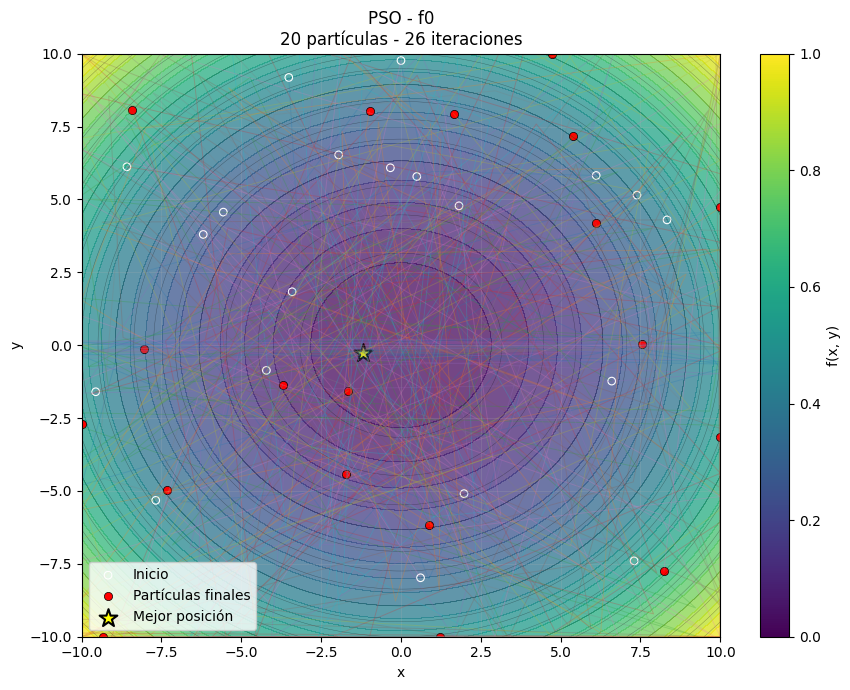

No convergió según la tolerancia definida, mejor valor final: 0.044621653854846954


In [ ]:
torch.manual_seed(SEMILLA)

mejor_posicion, mejor_valor, historial, historial_particulas, historial_valores, convergencia_info = pso(
    f0,
    limites=(-10, 10),
    n_particulas=20,
    iteraciones=25,
)
graficar_pso(f0, "PSO - f0", historial_particulas)

if convergencia_info["Convergió"]:
    print("Convergió en la iteración", convergencia_info["Iteración de convergencia"])
    print("Punto:", convergencia_info["Punto de convergencia"])
    print("Valor:", convergencia_info["Valor de convergencia"])
else:
    print("No convergió según la tolerancia definida, mejor valor final:", mejor_valor.item())

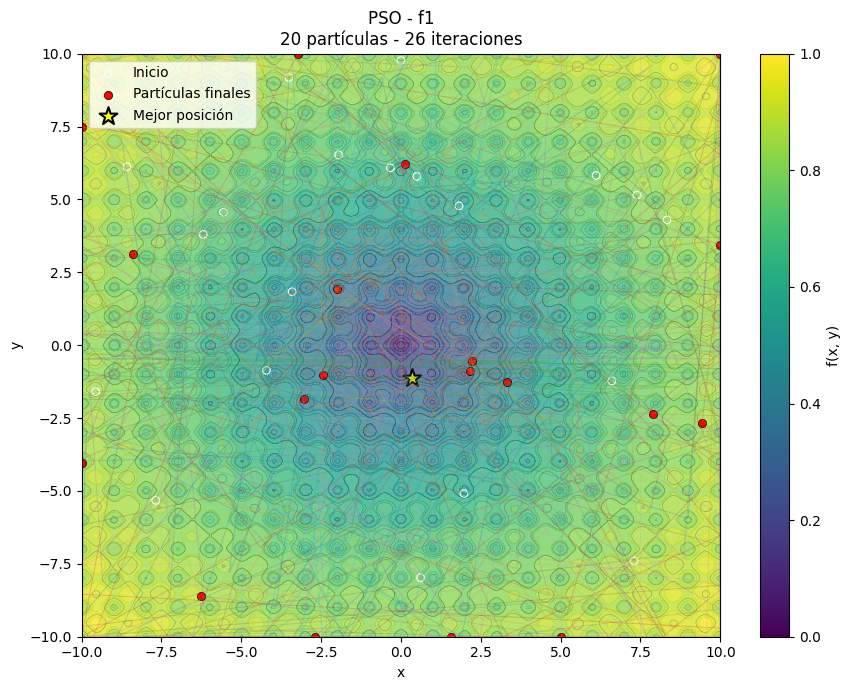

No convergió según la tolerancia definida, mejor valor final: 1.772125244140625


In [ ]:
torch.manual_seed(SEMILLA)

mejor_posicion, mejor_valor, historial, historial_particulas, historial_valores, convergencia_info = pso(
    f1,
    limites=(-10, 10),
    n_particulas=20,
    iteraciones=25,
)
graficar_pso(f1, "PSO - f1", historial_particulas)

if convergencia_info["Convergió"]:
    print("Convergió en la iteración", convergencia_info["Iteración de convergencia"])
    print("Punto:", convergencia_info["Punto de convergencia"])
    print("Valor:", convergencia_info["Valor de convergencia"])
else:
    print("No convergió según la tolerancia definida, mejor valor final:", mejor_valor.item())

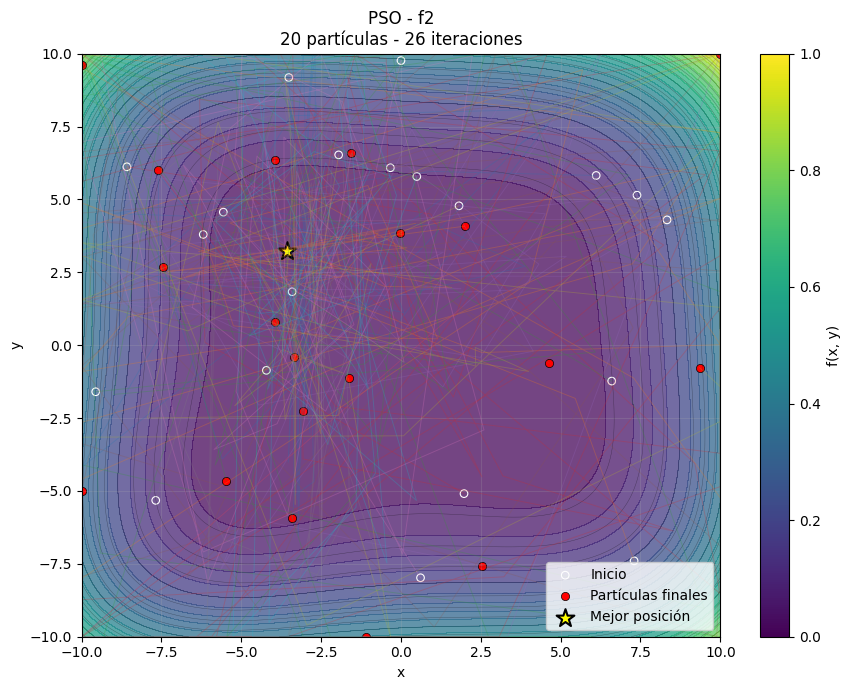

No convergió según la tolerancia definida, mejor valor final: 2.319403886795044


In [ ]:
torch.manual_seed(SEMILLA)

mejor_posicion, mejor_valor, historial, historial_particulas, historial_valores, convergencia_info = pso(
    f2,
    limites=(-10, 10),
    n_particulas=20,
    iteraciones=25,
)
graficar_pso(f2, "PSO - f2", historial_particulas)

if convergencia_info["Convergió"]:
    print("Convergió en la iteración", convergencia_info["Iteración de convergencia"])
    print("Punto:", convergencia_info["Punto de convergencia"])
    print("Valor:", convergencia_info["Valor de convergencia"])
else:
    print("No convergió según la tolerancia definida, mejor valor final:", mejor_valor.item())

## Ajuste de los hiperparámetros:

En el caso del algoritmo de Enjambre de Partículas contamos con 3 hiperparámetros, siendo:


*   Coeficiente de peso del componente cognitivo
*   Coeficiente de peso del componente social
*   Cantidad de partículas

Para esto implementamos la función calibrar_PSO utilizando la biblioteca Optuna. Esta función recibe como entrada la función en que se evalua, las iteraciones del algoritmo y la cantidad de valores a probar.

Estos valores se encuentran en diversos rangos. En este caso, como se ve en la literatura y se discutio en clase utilizamos para  $c_1$ y  $c_2$ el rango de [0.2-4.5]. La selección de este intervalo se fundamentó en la literatura, que recomienda un valor de 2 para ambos coeficientes. Asimismo, se consideró lo discutido en clase respecto a la posibilidad de emplear valores inferiores a este valor de referencia. Para la elección de la cantidad de partículas nos encontramos en la literatura recomendaciones de [20-100] según la complejidad del problema, por lo que utilizamos ese rango.

Una vez calibrados los hiperparámetros recomendados para cada función se realizarán pruebas con ellos.

In [ ]:
def calibrar_PSO(funcion, P=50, n_trials=50):
    """!
    @brief Calibra los hiperparámetros c1, c2 y n_particulas de PSO
    usando Optuna, minimizando el mejor valor global encontrado.

    @param funcion Función a minimizar.
    @param P Cantidad de iteraciones por corrida de PSO. Por defecto
          50.
    @param n_trials Cantidad de combinaciones de hiperparámetros a
          probar. Por defecto 50.
    @return study Objeto de estudio de Optuna con el historial de
          pruebas (incluyendo el historial completo y la información
          de convergencia de cada trial) y los mejores hiperparámetros
          encontrados.
    """

    def objetivo(trial):
        """!
        @brief Función objetivo de Optuna: ejecuta PSO con
        hiperparámetros propuestos, guarda el historial completo de la
        corrida en el trial y devuelve el mejor valor global obtenido.

        @param trial Objeto Trial de Optuna usado para sugerir los
              valores de c1, c2 y n_particulas, y para almacenar los
              resultados de la corrida.
        @return Mejor valor global obtenido por PSO en esta corrida.
        """

        # Hiperparámetros que Optuna va a probar
        c1 = trial.suggest_float("c1", 0.2, 4.5)
        c2 = trial.suggest_float("c2", 0.2, 4.5)
        n_particulas = trial.suggest_int("n_particulas", 20, 100)

        # Ejecutar PSO
        (
            mejor_global,
            mejor_valor_global,
            historial,
            historial_particulas,
            historial_valores,
            convergencia_info

        ) = pso(
            funcion,
            limites=(-10, 10),
            n_particulas=n_particulas,
            iteraciones=P,
            c1=c1,
            c2=c2,
            tolerancia=1e-4,
            valor_fijo=False,
            punto_fijo=(0, 0),
        )

        # Guardar los resultados completos del trial
        trial.set_user_attr(
            "mejor_global",
            mejor_global.tolist()
        )

        trial.set_user_attr(
            "historial",
            [x.tolist() for x in historial]
        )

        trial.set_user_attr(
            "historial_valores",
            historial_valores
        )

        trial.set_user_attr(
            "historial_particulas",
            [
                x.tolist()
                for x in historial_particulas
            ]
        )

        trial.set_user_attr(
                "convergencia_info",
                convergencia_info
        )



        # Este sigue siendo el objetivo que Optuna minimiza
        return mejor_valor_global.item()

    # Semilla para que las posiciones aleatorias del PSO sean reproducibles
    torch.manual_seed(SEMILLA)

    # Crear estudio (sampler con semilla para que la calibración sea reproducible)
    sampler = optuna.samplers.TPESampler(seed=SEMILLA)
    study = optuna.create_study(
        direction="minimize",
        sampler=sampler
    )

    # Ejecutar calibración
    study.optimize(
        objetivo,
        n_trials=n_trials
    )

    return study

def mostrar_trials_pso(study):
    """!
    @brief Construye una tabla con los trials de un estudio de PSO de
    Optuna, incluyendo la información de convergencia de cada corrida.

    @param study Objeto de estudio de Optuna ya optimizado, generado
          por calibrar_PSO.
    @return DataFrame con las columnas number, value, params_c1,
          params_c2, params_n_particulas, Convergió e Iteración de
          convergencia, ordenado por value.
    """

    df = study.trials_dataframe()

    columnas = [
        "number",
        "value",
        "params_c1",
        "params_c2",
        "params_n_particulas"
    ]

    df = df[columnas].copy()

    # Información de convergencia
    df["Convergió"] = [
        trial.user_attrs["convergencia_info"]["Convergió"]
        for trial in study.trials
    ]

    df["Iteración de convergencia"] = [
        trial.user_attrs["convergencia_info"]["Iteración de convergencia"]
        if trial.user_attrs["convergencia_info"]["Convergió"] else "—"
        for trial in study.trials
    ]

    return df.sort_values("value")



[I 2026-09-27 18:38:36,688] A new study created in memory with name: no-name-3abfb796-bbfc-4004-b27b-9474ded07736
[I 2026-09-27 18:38:36,705] Trial 0 finished with value: 0.056519586592912674 and parameters: {'c1': 3.9343539183006175, 'c2': 0.9032010500336694, 'n_particulas': 36}. Best is trial 0 with value: 0.056519586592912674.
[I 2026-09-27 18:38:36,719] Trial 1 finished with value: 0.13633809983730316 and parameters: {'c1': 4.3836128108426395, 'c2': 4.234975774849058, 'n_particulas': 52}. Best is trial 0 with value: 0.056519586592912674.
[I 2026-09-27 18:38:36,737] Trial 2 finished with value: 0.08928591012954712 and parameters: {'c1': 0.24199180755384475, 'c2': 3.161108364518869, 'n_particulas': 97}. Best is trial 0 with value: 0.056519586592912674.
[I 2026-09-27 18:38:36,744] Trial 3 finished with value: 7.603761332575232e-05 and parameters: {'c1': 0.28951987630409515, 'c2': 1.7252505471639485, 'n_particulas': 53}. Best is trial 3 with value: 7.603761332575232e-05.
[I 2026-09-27 

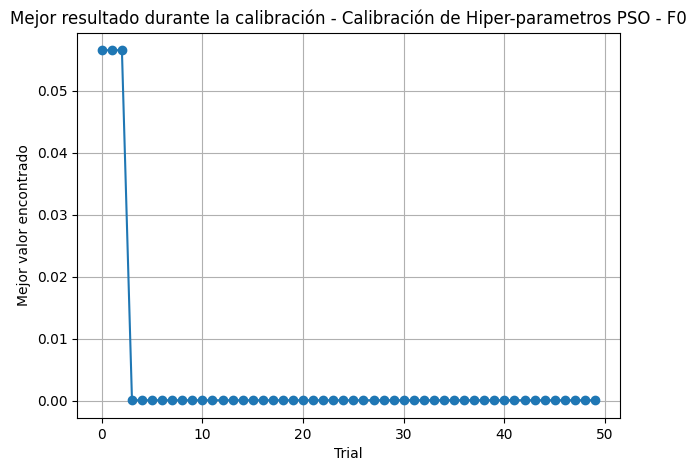

Los mejores parametros para F0 fueron  {'c1': 0.28951987630409515, 'c2': 1.7252505471639485, 'n_particulas': 53}


,number,value,params_c1,params_c2,params_n_particulas,Convergió,Iteración de convergencia
3,3,0.000076,0.289520,1.725251,53,True,3
37,37,0.000077,1.489732,1.058746,91,True,35
46,46,0.000109,1.144395,0.338762,66,False,—
15,15,0.000272,1.289913,2.379308,86,False,—
42,42,0.000278,1.813286,0.299124,78,False,—
48,48,0.000290,2.224813,0.665019,65,False,—
29,29,0.000294,1.651216,0.873897,93,False,—
47,47,0.000332,1.292470,0.337401,63,False,—
30,30,0.000358,1.458553,1.237921,95,False,—
41,41,0.000602,1.877469,1.510610,92,False,—


In [ ]:
Resultado_calibracion_F0_PSO = calibrar_PSO(f0)

graficar_trials(Resultado_calibracion_F0_PSO, "Calibración de Hiper-parametros PSO - F0")

print("Los mejores parametros para F0 fueron ",Resultado_calibracion_F0_PSO.best_params)

mostrar_trials_pso(Resultado_calibracion_F0_PSO)



[I 2026-09-27 18:38:40,301] A new study created in memory with name: no-name-ffe6eb07-837b-4151-b845-b95d732879f2
[I 2026-09-27 18:38:40,317] Trial 0 finished with value: 0.284881591796875 and parameters: {'c1': 3.9343539183006175, 'c2': 0.9032010500336694, 'n_particulas': 36}. Best is trial 0 with value: 0.284881591796875.
[I 2026-09-27 18:38:40,333] Trial 1 finished with value: 2.5749778747558594 and parameters: {'c1': 4.3836128108426395, 'c2': 4.234975774849058, 'n_particulas': 52}. Best is trial 0 with value: 0.284881591796875.
[I 2026-09-27 18:38:40,350] Trial 2 finished with value: 2.070037841796875 and parameters: {'c1': 0.24199180755384475, 'c2': 3.161108364518869, 'n_particulas': 97}. Best is trial 0 with value: 0.284881591796875.
[I 2026-09-27 18:38:40,366] Trial 3 finished with value: 0.7447509765625 and parameters: {'c1': 0.28951987630409515, 'c2': 1.7252505471639485, 'n_particulas': 53}. Best is trial 0 with value: 0.284881591796875.
[I 2026-09-27 18:38:40,386] Trial 4 fin

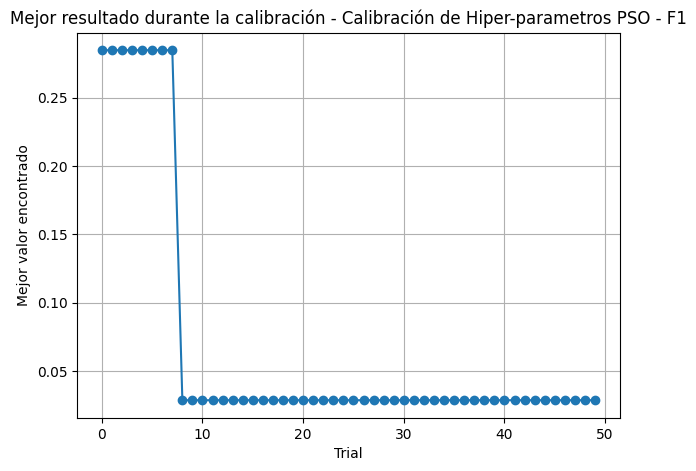

Los mejores parametros para F1 fueron  {'c1': 3.8243992236042534, 'c2': 3.3632023577146772, 'n_particulas': 48}


,number,value,params_c1,params_c2,params_n_particulas,Convergió,Iteración de convergencia
8,8,0.028675,3.824399,3.363202,48,False,—
43,43,0.041344,2.404372,0.264889,60,False,—
46,46,0.103348,2.072766,0.307424,58,False,—
44,44,0.107075,2.370862,0.387995,42,False,—
30,30,0.133717,2.799558,0.303186,50,False,—
11,11,0.138649,3.607944,0.296886,24,False,—
35,35,0.142200,2.671916,1.019905,33,False,—
47,47,0.165710,1.958605,0.314975,65,False,—
36,36,0.194317,2.795116,0.423979,49,False,—
20,20,0.203327,1.384559,0.304240,35,False,—


In [ ]:
Resultado_calibracion_F1_PSO = calibrar_PSO(f1)

graficar_trials(Resultado_calibracion_F1_PSO, "Calibración de Hiper-parametros PSO - F1")

print("Los mejores parametros para F1 fueron ",Resultado_calibracion_F1_PSO.best_params)

mostrar_trials_pso(Resultado_calibracion_F1_PSO)


[I 2026-09-27 18:38:43,117] A new study created in memory with name: no-name-bd9ff2d9-4bb8-4092-a692-26615eb8d6f7
[I 2026-09-27 18:38:43,133] Trial 0 finished with value: 0.11584392189979553 and parameters: {'c1': 3.9343539183006175, 'c2': 0.9032010500336694, 'n_particulas': 36}. Best is trial 0 with value: 0.11584392189979553.
[I 2026-09-27 18:38:43,147] Trial 1 finished with value: 1.2797985076904297 and parameters: {'c1': 4.3836128108426395, 'c2': 4.234975774849058, 'n_particulas': 52}. Best is trial 0 with value: 0.11584392189979553.
[I 2026-09-27 18:38:43,161] Trial 2 finished with value: 0.17188182473182678 and parameters: {'c1': 0.24199180755384475, 'c2': 3.161108364518869, 'n_particulas': 97}. Best is trial 0 with value: 0.11584392189979553.
[I 2026-09-27 18:38:43,175] Trial 3 finished with value: 0.15892833471298218 and parameters: {'c1': 0.28951987630409515, 'c2': 1.7252505471639485, 'n_particulas': 53}. Best is trial 0 with value: 0.11584392189979553.
[I 2026-09-27 18:38:43,

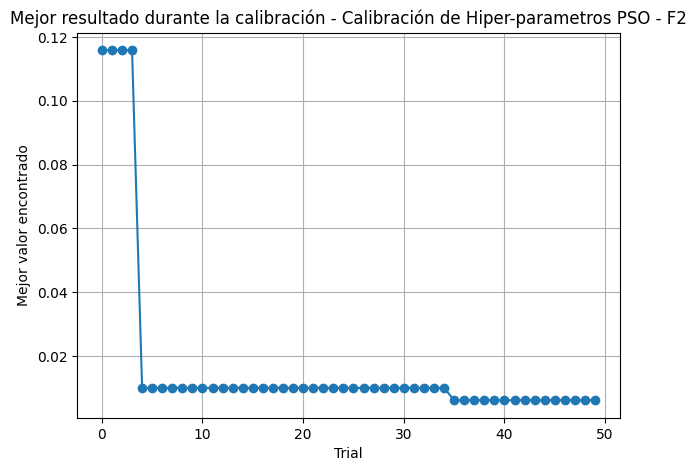

Los mejores parametros para F2 fueron  {'c1': 3.0876381868580802, 'c2': 1.4631415130557452, 'n_particulas': 77}


,number,value,params_c1,params_c2,params_n_particulas,Convergió,Iteración de convergencia
35,35,0.006169,3.087638,1.463142,77,False,—
40,40,0.007499,3.226889,1.233478,61,False,—
4,4,0.010033,3.002221,1.335446,60,False,—
13,13,0.014900,2.694264,1.596585,95,False,—
34,34,0.015511,3.975715,0.573249,55,False,—
23,23,0.021718,3.615868,0.798072,94,False,—
30,30,0.023281,4.096059,0.857446,54,False,—
46,46,0.023862,3.430792,1.457579,83,False,—
12,12,0.024155,2.902159,0.657575,93,False,—
25,25,0.067142,2.898189,1.888008,87,False,—


In [ ]:
Resultado_calibracion_F2_PSO = calibrar_PSO(f2)

graficar_trials(Resultado_calibracion_F2_PSO, "Calibración de Hiper-parametros PSO - F2")

print("Los mejores parametros para F2 fueron ",Resultado_calibracion_F2_PSO.best_params)

mostrar_trials_pso(Resultado_calibracion_F2_PSO)


1) Ejecute el algoritmo 10 corridas diferentes, y documente en una
tabla la cantidad de iteraciones para converger a el o los puntos
minimos (indique si convergió). Los 10 puntos iniciales escogidos deben preservarse para todos los algoritmos a probar
(deben ser los mismos que el descenso del gradiente y el RMS
prop).

In [ ]:
def ejecutar_pso_10_veces(
    funcion,
    puntos_iniciales,
    c1,
    c2,
    n_particulas,
    limites=(-10, 10),
    P=50,
    tolerancia=1e-4
):
    """!
    @brief Ejecuta PSO una vez por cada punto inicial de una lista,
    fijando ese punto como posición inicial de una partícula, y arma un
    resumen de resultados por corrida. En cada corrida se fija una
    semilla distinta, para que los resultados se puedan reproducir.

    @param funcion Función a minimizar.
    @param puntos_iniciales Lista de tuplas (x0, y0), un punto inicial
          fijo por corrida.
    @param c1 Coeficiente cognitivo de PSO.
    @param c2 Coeficiente social de PSO.
    @param n_particulas Cantidad de partículas del enjambre.
    @param limites Tupla (mínimo, máximo) que define el rango de
          búsqueda. Por defecto (-10, 10).
    @param P Cantidad máxima de iteraciones por corrida. Por defecto
          25.
    @param tolerancia Valor de la función por debajo del cual PSO
          declara convergencia. Por defecto 1e-4.
    @return resultados Lista de diccionarios (uno por corrida), cada
          uno con las claves "ejecucion", "x_inicial", "y_inicial",
          "valor_final", "iteraciones", "convergio",
          "historial_theta" e "historial_f".
    """

    resultados = []

    for ejecucion in range(len(puntos_iniciales)):
        #Realizar las ejecuciones con los puntos asignados
        x_inicial, y_inicial = puntos_iniciales[ejecucion]

        # Semilla distinta por corrida, para que cada una sea reproducible
        torch.manual_seed(SEMILLA + ejecucion)

        (
            mejor_global,
            mejor_valor_global,
            historial,
            historial_particulas,
            historial_valores,
            convergencia_info
        ) = pso(
            funcion,
            limites=limites,
            n_particulas=n_particulas,
            iteraciones=P,
            c1=c1,
            c2=c2,
            tolerancia=tolerancia,
            valor_fijo=True,
            punto_fijo=(x_inicial, y_inicial)
        )
        #Revisa la convergencia en los resultados y almacena la información de iteraciones
        convergio = convergencia_info["Convergió"]

        if convergio:
            iteraciones = convergencia_info["Iteración de convergencia"] + 1
        else:
            iteraciones = len(historial_valores) - 1

        valor_final = historial_valores[-1]

        resultados.append({
            "ejecucion": ejecucion + 1,
            "x_inicial": x_inicial,
            "y_inicial": y_inicial,
            "valor_final": valor_final,
            "iteraciones": iteraciones,
            "convergio": convergio,
            "historial_theta": historial,
            "historial_f": historial_valores
        })

    return resultados

In [ ]:
c1_f0_pso = Resultado_calibracion_F0_PSO.best_params["c1"]
c2_f0_pso = Resultado_calibracion_F0_PSO.best_params["c2"]
n_particulas_f0_pso = Resultado_calibracion_F0_PSO.best_params["n_particulas"]
print(c1_f0_pso,c2_f0_pso,n_particulas_f0_pso)

c1_f1_pso = Resultado_calibracion_F1_PSO.best_params["c1"]
c2_f1_pso = Resultado_calibracion_F1_PSO.best_params["c2"]
n_particulas_f1_pso = Resultado_calibracion_F1_PSO.best_params["n_particulas"]
print(c1_f1_pso,c2_f1_pso,n_particulas_f1_pso)

c1_f2_pso = Resultado_calibracion_F2_PSO.best_params["c1"]
c2_f2_pso = Resultado_calibracion_F2_PSO.best_params["c2"]
n_particulas_f2_pso = Resultado_calibracion_F2_PSO.best_params["n_particulas"]
print(c1_f2_pso,c2_f2_pso,n_particulas_f2_pso)

0.28951987630409515 1.7252505471639485 53
3.8243992236042534 3.3632023577146772 48
3.0876381868580802 1.4631415130557452 77


In [ ]:
resultados_pso_f0 = ejecutar_pso_10_veces(
    f0, puntos_iniciales,
    c1=c1_f0_pso, c2=c2_f0_pso, n_particulas=n_particulas_f0_pso
)

resultados_pso_f1 = ejecutar_pso_10_veces(
    f1, puntos_iniciales,
    c1=c1_f1_pso, c2=c2_f1_pso, n_particulas=n_particulas_f1_pso
)

resultados_pso_f2 = ejecutar_pso_10_veces(
    f2, puntos_iniciales,
    c1=c1_f2_pso, c2=c2_f2_pso, n_particulas=n_particulas_f2_pso
)

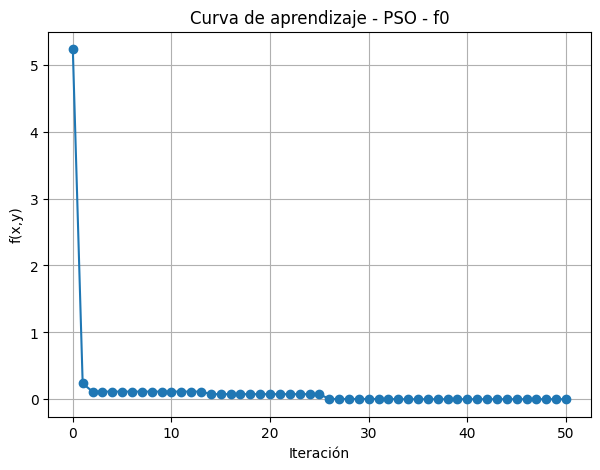

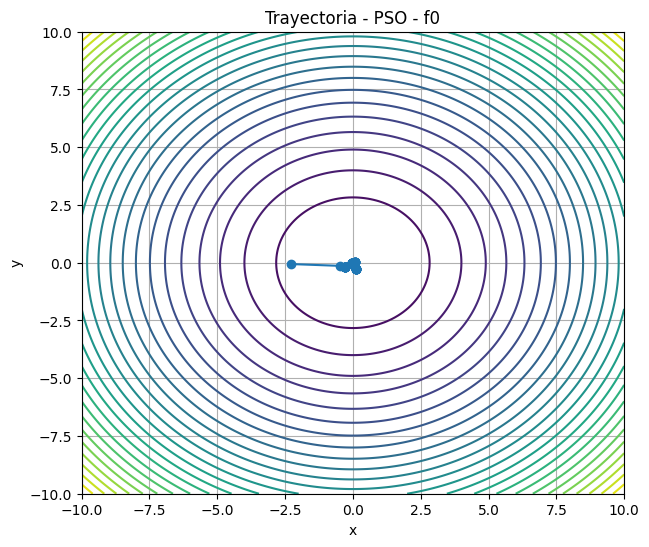

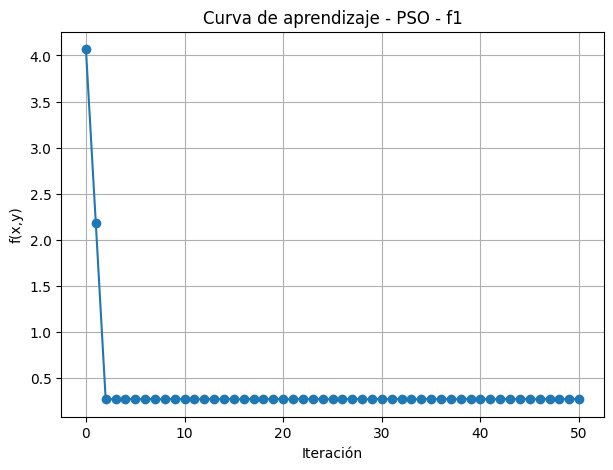

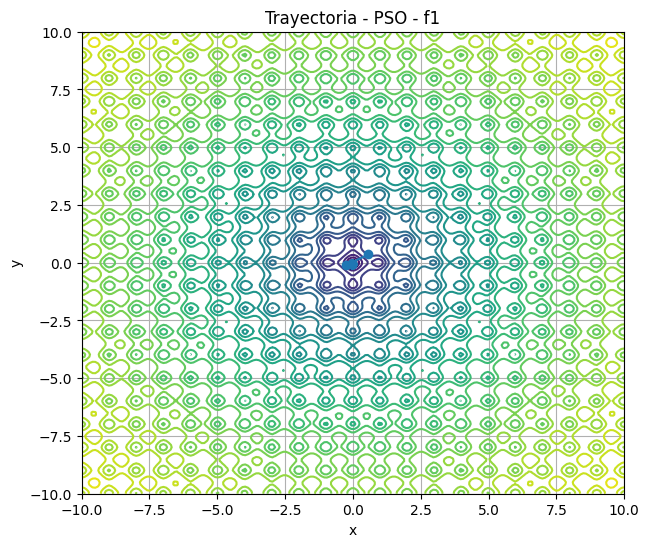

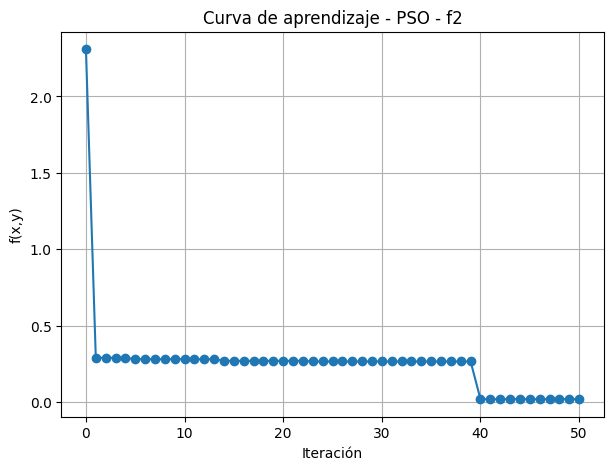

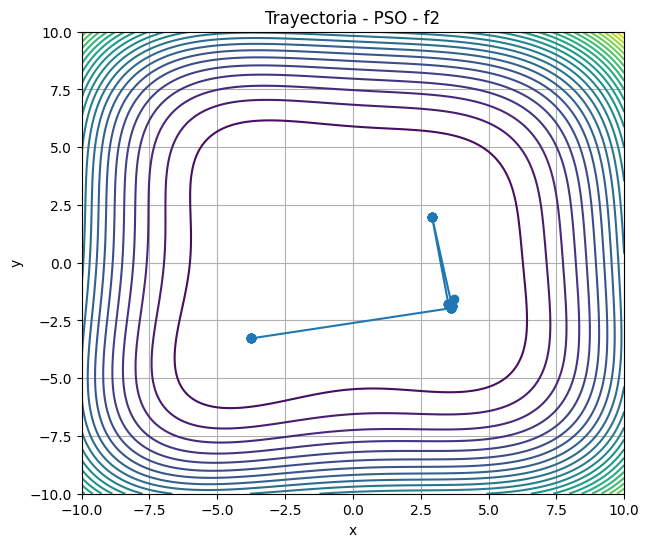

In [ ]:
mejor_pso_f0 = obtener_mejor_corrida(resultados_pso_f0)
mejor_pso_f1 = obtener_mejor_corrida(resultados_pso_f1)
mejor_pso_f2 = obtener_mejor_corrida(resultados_pso_f2)


graficar_mejor_corrida(mejor_pso_f0, f0, "PSO - f0")
graficar_mejor_corrida(mejor_pso_f1, f1, "PSO - f1")
graficar_mejor_corrida(mejor_pso_f2, f2, "PSO - f2")

In [ ]:
tabla_pso_f0 = mostrar_resultados(
    resultados_pso_f0,
    "PSO - f0"
)

tabla_pso_f1 = mostrar_resultados(
    resultados_pso_f1,
    "PSO - f1"
)

tabla_pso_f2 = mostrar_resultados(
    resultados_pso_f2,
    "PSO - f2"
)

PSO - f0


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(0.2547, 0.036)",0.066156,50,No
1,2,"(8.0, -8.0)","(0.1312, 0.0577)",0.020557,50,No
2,3,"(-8.0, 8.0)","(0.148, -0.1376)",0.040818,50,No
3,4,"(-9.0, -9.0)","(0.0619, -0.1269)",0.019928,50,No
4,5,"(6.0, 2.0)","(-0.0398, -0.0067)",0.001632,50,No
5,6,"(-6.0, 2.0)","(-0.0397, -0.0533)",0.004422,50,No
6,7,"(2.0, -6.0)","(0.0425, 0.0312)",0.002774,50,No
7,8,"(-2.0, 6.0)","(0.0359, 0.0996)",0.011204,50,No
8,9,"(4.0, -9.0)","(0.0095, -0.1189)",0.014238,50,No
9,10,"(-4.0, 9.0)","(-0.0741, -0.0944)",0.014393,50,No


PSO - f1


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(0.0291, -0.8402)",2.821575,50,No
1,2,"(8.0, -8.0)","(0.1838, 0.0148)",1.219826,50,No
2,3,"(-8.0, 8.0)","(0.1148, 0.173)",1.460258,50,No
3,4,"(-9.0, -9.0)","(0.0868, -0.1874)",1.436733,50,No
4,5,"(6.0, 2.0)","(-0.173, 0.0972)",1.370945,50,No
5,6,"(-6.0, 2.0)","(-0.0809, -0.3144)",2.344486,50,No
6,7,"(2.0, -6.0)","(-0.1404, -0.2483)",2.127155,50,No
7,8,"(-2.0, 6.0)","(-0.0459, -0.0401)",0.268791,50,No
8,9,"(4.0, -9.0)","(-0.1433, 0.1111)",1.223911,50,No
9,10,"(-4.0, 9.0)","(0.0627, -0.1001)",0.671970,50,No


PSO - f2


,Ejecución,Punto inicial,Punto final,Valor final,Iteraciones,Convergió
0,1,"(9.5, 9.5)","(-3.7602, -3.278)",0.019591,50,No
1,2,"(8.0, -8.0)","(-3.7379, -3.2987)",0.127362,50,No
2,3,"(-8.0, 8.0)","(3.6546, -1.9538)",0.384340,50,No
3,4,"(-9.0, -9.0)","(-2.6228, 3.09)",1.068035,50,No
4,5,"(6.0, 2.0)","(3.5244, -1.788)",0.211969,50,No
5,6,"(-6.0, 2.0)","(-2.8841, 3.069)",0.366408,50,No
6,7,"(2.0, -6.0)","(3.0162, 1.8516)",0.311080,50,No
7,8,"(-2.0, 6.0)","(3.5931, -1.922)",0.082537,50,No
8,9,"(4.0, -9.0)","(3.6524, -1.8717)",0.243533,50,No
9,10,"(-4.0, 9.0)","(3.6683, -1.8516)",0.374791,50,No


In [ ]:
for nombre, resultados in [
    ("GD - f0", resultados_gd_f0),
    ("GD - f1", resultados_gd_f1),
    ("GD - f2", resultados_gd_f2),
    ("RMSprop - f0", resultados_rms_f0),
    ("RMSprop - f1", resultados_rms_f1),
    ("RMSprop - f2", resultados_rms_f2),
    ("PSO - f0", resultados_pso_f0),
    ("PSO - f1", resultados_pso_f1),
    ("PSO - f2", resultados_pso_f2)
]:

    promedio_funcion, promedio_iteraciones, cantidad = \
        calcular_promedios(resultados)

    print(nombre)
    print("Promedio de f:", promedio_funcion)
    print("Promedio de iteraciones:", promedio_iteraciones)
    print("Corridas convergentes:", cantidad, "/ 10")
    print()

GD - f0
Promedio de f: 6.697089929730282e-07
Promedio de iteraciones: 3.0
Corridas convergentes: 10 / 10

GD - f1
Promedio de f: 2.6320504188537597
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

GD - f2
Promedio de f: 0.00035618619258457327
Promedio de iteraciones: 30.0
Corridas convergentes: 8 / 10

RMSprop - f0
Promedio de f: 3.4686610524659046e-05
Promedio de iteraciones: 20.5
Corridas convergentes: 10 / 10

RMSprop - f1
Promedio de f: 3.17189416885376
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

RMSprop - f2
Promedio de f: 0.18306407977543132
Promedio de iteraciones: 25.142857142857142
Corridas convergentes: 7 / 10

PSO - f0
Promedio de f: 0.019612197240348905
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

PSO - f1
Promedio de f: 1.494565200805664
Promedio de iteraciones: None
Corridas convergentes: 0 / 10

PSO - f2
Promedio de f: 0.3189645254984498
Promedio de iteraciones: None
Corridas convergentes: 0 / 10



¿Cómo podría mezclar el algoritmo del descenso del gradiente con
el algoritmo de PSO? ¿Qué beneficios tendría el hacerlo?

Ambos algoritmos son muy distintos entre sí, como vimos en clase PSO es estocastico siendo que no necesita conocer la función a minimizar. Esto es contrario al GD, este algoritmo si necesita conocer la función para derivarla y obtener el gradiente. Una mezcla podría realizarse utilizando el PSO e implementar en algunas iteraciones para los puntos de forma individual el algoritmo GD, por ejemplo, que en las iteraciones pares los puntos se movieran siguiendo el algoritmo PSO y en los impares se movieran utilizando GD. Con esto le daríamos un peso más alto a la investigación individual de cada punto sin perder del todo el cociente colectivo del PSO.Hay que tener en cuenta las limitantes de una mezcla de estos algoritmos, ya que solo funcionaría para los casos donde se conozca la función

**Relación con nuestros resultados:** los datos del cuaderno apoyan la idea de mezclarlos, porque cada algoritmo es fuerte justo donde el otro es débil.

- En $f_1$, la función con muchos mínimos locales, PSO obtuvo el mejor promedio de los tres algoritmos (1.49, contra 4.80 del descenso de gradiente y 2.67 de RMSprop), porque explora todo el espacio con varias partículas a la vez y no depende del valle en el que empieza.
- Pero PSO no convergió en ninguna corrida de ninguna función. En $f_0$ quedó en promedio en 0.0196 y en $f_2$ en 0.319, mientras que el descenso de gradiente convergió en 10 de 10 corridas en $f_0$ (en 3 iteraciones) y en 8 de 10 en $f_2$.

Es decir, PSO encuentra la zona correcta pero le cuesta afinar, y el descenso de gradiente afina muy bien pero solo si empieza en la zona correcta. Una mezcla natural sería usar PSO durante las primeras iteraciones para encontrar la zona del mínimo global, y luego continuar con descenso de gradiente desde la mejor posición del enjambre para llegar con precisión al mínimo.

# 4. Comparación de todos los algoritmos



,Función,Algoritmo,Convergentes,Iteraciones promedio,Promedio de f,Mejor f,Peor f
0,f0,GD,10 / 10,3.0,6.697090e-07,2.812427e-07,0.000001
1,f0,RMSprop,10 / 10,20.5,3.468661e-05,1.484290e-05,0.000050
2,f0,PSO,0 / 10,—,1.961220e-02,1.632125e-03,0.066156
3,f1,GD,0 / 10,—,2.632050e+00,1.003777e+00,4.460177
4,f1,RMSprop,0 / 10,—,3.171894e+00,2.488861e+00,4.268571
5,f1,PSO,0 / 10,—,1.494565e+00,2.687912e-01,2.821575
6,f2,GD,8 / 10,30.0,3.561862e-04,4.538688e-05,0.002051
7,f2,RMSprop,7 / 10,25.142857,1.830641e-01,3.366715e-05,1.656719
8,f2,PSO,0 / 10,—,3.189645e-01,1.959132e-02,1.068035


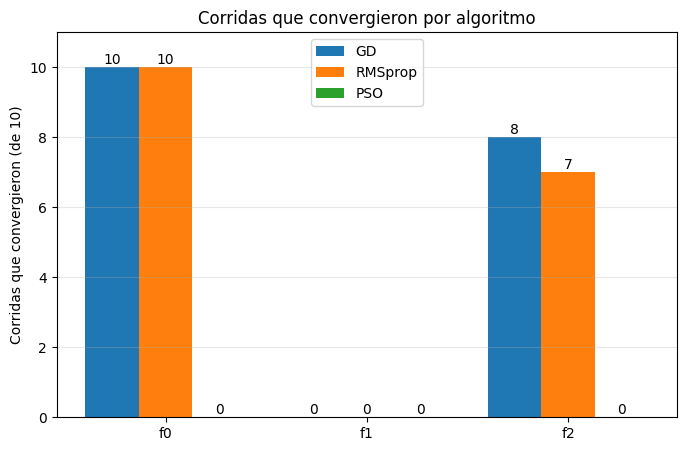

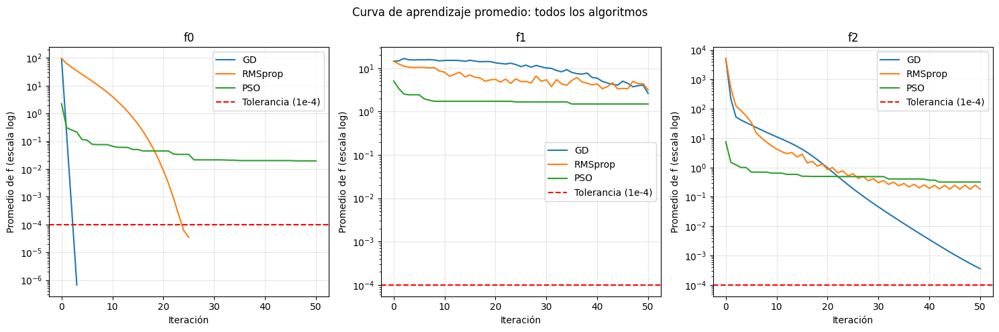

In [ ]:
algoritmos_todos = {
    "GD": {"f0": resultados_gd_f0, "f1": resultados_gd_f1, "f2": resultados_gd_f2},
    "RMSprop": {"f0": resultados_rms_f0, "f1": resultados_rms_f1, "f2": resultados_rms_f2},
    "PSO": {"f0": resultados_pso_f0, "f1": resultados_pso_f1, "f2": resultados_pso_f2}
}

tabla_todos = resumen_comparativo(algoritmos_todos)

graficar_convergencias(algoritmos_todos, "Corridas que convergieron por algoritmo")
graficar_curvas_promedio(algoritmos_todos, "Curva de aprendizaje promedio: todos los algoritmos")

**Nota sobre la curva de aprendizaje promedio de $f_2$.** Aunque varias corridas del descenso de gradiente y de RMSprop sí convergieron en $f_2$, sus curvas promedio no llegan a tocar la línea de tolerancia. Esto pasa por tres razones:

1. **La curva es el promedio de las 10 corridas**, no una corrida individual. Basta con que unas pocas corridas terminen arriba de la tolerancia para que el promedio también quede arriba. En el descenso de gradiente, las 2 corridas que no convergieron terminaron en 0.00088 y 0.0021; solo ellas ya aportan (0.00088 + 0.0021) / 10 ≈ 0.0003 al promedio, que es tres veces la tolerancia (0.0001). En RMSprop es más marcado: la corrida desde (-4, 9) terminó en 1.66, así que ella sola sube el promedio a más de 0.16.
2. **Las corridas que convergieron se detienen justo debajo de la tolerancia.** Una corrida se considera convergida en la primera iteración en que f baja de 0.0001 (por ejemplo, en 0.00009), y ese último valor se repite hasta el final de la gráfica. Por eso, aun las corridas exitosas quedan pegadas a la línea, no muy por debajo de ella.
3. **El promedio lo dominan los valores más grandes.** En escala logarítmica, un valor de 1.66 pesa muchísimo más que varios valores de 0.00009, por lo que la curva promedio refleja sobre todo a las corridas que peor terminaron.

Por eso, para saber cuántas corridas convergieron conviene mirar la gráfica de barras o la tabla resumen, y usar la curva promedio solo para ver qué tan rápido baja cada algoritmo en general.

**Respuesta 4**

**Resumen de resultados.** Además de los resultados del descenso de gradiente y RMSprop analizados en el inciso 2f, PSO obtuvo:

| Función | Hiperparámetros de PSO | Corridas que convergieron | Valor promedio de f | Mejor corrida |
|---|---|---|---|---|
| $f_0$ | c1 = 0.29, c2 = 1.73, 53 partículas | 0/10 | 0.0196 | 0.0016 |
| $f_1$ | c1 = 3.82, c2 = 3.36, 48 partículas | 0/10 | 1.49 | 0.27 |
| $f_2$ | c1 = 3.09, c2 = 1.46, 77 partículas | 0/10 | 0.319 | 0.0196 |

**Qué muestran los resultados**

- **Ninguno es el mejor en todas las funciones.** En $f_0$ gana el descenso de gradiente (10/10 corridas en 3 iteraciones), en $f_2$ el descenso de gradiente y RMSprop quedan parecidos (8/10 y 7/10), y en $f_1$ gana PSO con el mejor promedio (1.49, contra 2.67 de RMSprop y 4.80 del descenso de gradiente).
- **PSO es el único que no depende del punto inicial para explorar.** En $f_1$, el descenso de gradiente y RMSprop quedan atrapados en el valle más cercano a donde empiezan. PSO mueve varias partículas por todo el espacio a la vez, así que alguna encuentra valles mejores. Por eso su peor corrida en $f_1$ (2.82) es mucho mejor que la peor del descenso de gradiente (13.99).
- **PSO encuentra la zona correcta, pero le cuesta afinar.** No convergió en ninguna de las 30 corridas. En $f_0$ quedó en promedio en 0.0196, lo que equivale a quedar a unas 0.14 unidades del mínimo, cuando el descenso de gradiente llegó a alrededor de 0.001 en 3 iteraciones. PSO no usa la pendiente, solo compara valores entre partículas; para bajar de la tolerancia alguna partícula tiene que caer casi exactamente en el mínimo, y eso es poco probable en 50 iteraciones.
- **El costo es muy distinto.** El descenso de gradiente y RMSprop calculan un gradiente por iteración, es decir, como máximo 50 cálculos por corrida. PSO evalúa la función una vez por cada partícula en cada iteración: 53 × 50 = 2 650 evaluaciones por corrida en $f_0$, 2 400 en $f_1$ y 3 850 en $f_2$. Aun haciendo entre 48 y 77 veces más cálculos, solo superó a los otros dos en $f_1$.
- **Sensibilidad a los hiperparámetros.** El descenso de gradiente necesitó un α distinto para cada función (de 0.522 a 0.0044) y con α grande diverge hasta nan en $f_2$. RMSprop funcionó con α parecidos en las tres funciones (0.41 a 0.64) y nunca divergió. PSO tiene tres hiperparámetros, y sus mejores valores cambiaron bastante entre funciones (c1 fue de 0.29 a 3.82).
- **Repetibilidad.** Desde un mismo punto inicial, el descenso de gradiente y RMSprop siempre dan el mismo resultado. PSO depende de números aleatorios, por lo que tuvimos que fijar una semilla por corrida para poder repetir los resultados.

**Ventajas y desventajas**

**Descenso de gradiente**
- Ventajas: es el más sencillo, tiene un solo hiperparámetro y es muy rápido y preciso en funciones con forma de tazón, como $f_0$. *[agregar fuente]*
- Desventajas: es muy sensible al valor de α, puede diverger si el paso es grande (como en $f_2$), se queda atrapado en mínimos locales (como en $f_1$) y avanza lento en zonas donde la pendiente es pequeña, como cerca de puntos silla. *[agregar fuente]*

**RMSprop**
- Ventajas: ajusta el tamaño del paso según la pendiente reciente, por lo que no explota con pendientes grandes ni se frena tanto con pendientes pequeñas, y es más fácil de calibrar porque un mismo α sirve en funciones distintas. *[agregar fuente]*
- Desventajas: tiene un hiperparámetro más (β), sigue siendo un método local que se atrapa en mínimos locales (como en $f_1$) y, con un α grande, puede quedarse rebotando alrededor del mínimo en lugar de asentarse. *[agregar fuente]*

**PSO**
- Ventajas: no necesita derivadas, solo evaluar la función, por lo que sirve incluso donde la derivada no existe (como en el origen de $f_1$). Además explora todo el espacio a la vez, lo que lo hace mejor en funciones con muchos mínimos locales. *[agregar fuente]*
- Desventajas: necesita muchas más evaluaciones de la función, tiene más hiperparámetros, sus resultados dependen del azar y le cuesta llegar con precisión al mínimo exacto. *[agregar fuente]*

**Conclusión.** La elección depende de la función. Para funciones sencillas y suaves, como $f_0$, el descenso de gradiente es la mejor opción. Si las pendientes cambian mucho de una zona a otra, como en $f_2$, RMSprop es más seguro porque no diverge y es más fácil de ajustar. Para funciones con muchos mínimos locales, como $f_1$, PSO es el que mejor explora, aunque a un costo mayor y sin llegar con precisión al mínimo. Por eso, combinar la exploración de PSO con la precisión de un método basado en gradiente, como se propone en el inciso 3d, aprovecha lo mejor de ambos.

# Pruebas unitarias

Para cada algoritmo implementamos dos pruebas sencillas que verifican que se comporta como esperamos. Cada prueba lanza un error (AssertionError) si algo no se cumple, y si todo está bien imprime "OK".

**Descenso de gradiente**
1. Las derivadas escritas a mano de $f_2$ dan el mismo resultado que backward() de PyTorch.
2. Desde (1, 1) con alpha = 0.1, el algoritmo converge al mínimo de $f_0$ antes de 50 iteraciones.

**RMSprop**
1. Sobre $f_0$, el valor final de la función es menor que el inicial.
2. En el primer paso, cada coordenada se mueve exactamente $\alpha / \sqrt{1-\beta}$, sin importar el tamaño del gradiente. Por eso RMSprop no explota en $f_2$ como el descenso de gradiente.

**PSO**
1. Las partículas nunca salen del rango [-10, 10].
2. La partícula fija empieza en el punto indicado, y el mejor valor global nunca empeora de una iteración a otra.

In [ ]:
def prueba_gd_derivadas_manuales():
    """!
    @brief Prueba 1 del descenso de gradiente: verifica que las derivadas
    escritas a mano de f2 coincidan con las calculadas por backward().

    @return None. Lanza AssertionError si alguna derivada no coincide.
    """
    for x0, y0 in [(1.0, 2.0), (-3.0, 0.5), (4.0, -2.0)]:
        x = torch.tensor(x0, requires_grad=True)
        y = torch.tensor(y0, requires_grad=True)
        f2(x, y).backward()

        dx_manual = df2_dx(x0, y0)
        dy_manual = df2_dy(x0, y0)

        assert abs(x.grad.item() - dx_manual) < 1e-4 * (1 + abs(dx_manual))
        assert abs(y.grad.item() - dy_manual) < 1e-4 * (1 + abs(dy_manual))

    print("GD - prueba 1 (derivadas manuales = backward): OK")


def prueba_gd_converge_f0():
    """!
    @brief Prueba 2 del descenso de gradiente: desde (1, 1) con
    alpha = 0.1, debe converger al mínimo de f0 antes de 50 iteraciones.

    @return None. Lanza AssertionError si no converge.
    """
    resultados = ejecutar_gd_10_veces(f0, [(1.0, 1.0)], alpha=0.1, P=50)

    assert resultados[0]["convergio"]
    assert resultados[0]["valor_final"] < 1e-4

    print("GD - prueba 2 (converge en f0):", resultados[0]["iteraciones"], "iteraciones, OK")


def prueba_rmsprop_disminuye_f0():
    """!
    @brief Prueba 1 de RMSprop: sobre f0, el valor final de la función
    debe ser menor que el valor inicial.

    @return None. Lanza AssertionError si el valor no disminuye.
    """
    theta_history, f_history = rmsprop(f0, [3.0, 3.0], alpha=0.5, beta=0.9, P=25)

    assert f_history[-1] < f_history[0]

    print("RMSprop - prueba 1 (disminuye f0): OK")


def prueba_rmsprop_paso_acotado():
    """!
    @brief Prueba 2 de RMSprop: en el primer paso cada coordenada se
    mueve alpha / sqrt(1 - beta), sin importar el tamaño del gradiente.
    Se prueba en f2 desde (9.5, 9.5), donde el gradiente es enorme.

    @return None. Lanza AssertionError si el paso no tiene ese tamaño.
    """
    alpha = 0.05
    beta = 0.9

    theta_history, f_history = rmsprop(f2, [9.5, 9.5], alpha=alpha, beta=beta, P=1)

    paso = (theta_history[0] - theta_history[1]).abs()
    esperado = alpha / (1 - beta) ** 0.5

    assert torch.all((paso - esperado).abs() < 1e-3)

    print("RMSprop - prueba 2 (paso acotado en f2):", paso.tolist(), "OK")


def prueba_pso_dentro_de_limites():
    """!
    @brief Prueba 1 de PSO: ninguna partícula sale del rango [-10, 10]
    en ninguna iteración.

    @return None. Lanza AssertionError si alguna partícula sale del rango.
    """
    torch.manual_seed(SEMILLA)
    _, _, _, historial_particulas, _, _ = pso(
        f2, limites=(-10, 10), n_particulas=30, iteraciones=25
    )

    for posiciones in historial_particulas:
        assert posiciones.min() >= -10 and posiciones.max() <= 10

    print("PSO - prueba 1 (partículas dentro del rango): OK")


def prueba_pso_punto_fijo_y_mejora():
    """!
    @brief Prueba 2 de PSO: la partícula fija empieza en el punto
    indicado y el mejor valor global nunca empeora entre iteraciones.

    @return None. Lanza AssertionError si alguna condición no se cumple.
    """
    torch.manual_seed(SEMILLA)
    _, _, _, historial_particulas, historial_valores, _ = pso(
        f0, limites=(-10, 10), n_particulas=30, iteraciones=25,
        valor_fijo=True, punto_fijo=(4.0, -9.0)
    )

    assert torch.allclose(historial_particulas[0][0], torch.tensor([4.0, -9.0]))

    for i in range(len(historial_valores) - 1):
        assert historial_valores[i + 1] <= historial_valores[i]

    print("PSO - prueba 2 (punto fijo y mejor valor no empeora): OK")


prueba_gd_derivadas_manuales()
prueba_gd_converge_f0()
prueba_rmsprop_disminuye_f0()
prueba_rmsprop_paso_acotado()
prueba_pso_dentro_de_limites()
prueba_pso_punto_fijo_y_mejora()

GD - prueba 1 (derivadas manuales = backward): OK
GD - prueba 2 (converge en f0): 23 iteraciones, OK
RMSprop - prueba 1 (disminuye f0): OK
RMSprop - prueba 2 (paso acotado en f2): [0.1581134796142578, 0.1581134796142578] OK
PSO - prueba 1 (partículas dentro del rango): OK
PSO - prueba 2 (punto fijo y mejor valor no empeora): OK
